# Evaluación Sumativa 2 — Validación por remuestreo y simulación
## Dataset: *E-Commerce Shipping Data* (entregas atrasadas)

**MCDI501 - Estadística Computacional para la Toma de Decisiones**
Magíster en Ciencia de Datos e Inteligencia Artificial, Universidad Andrés Bello
Equipo: José Ignacio Rodríguez, Yerko Gallardo Miranda y Sebastián Rojas Araya

Este cuaderno valida **todos** los resultados de la Sumativa 1 (S1) de cada familia mediante bootstrap, permutación, simulación Monte Carlo, jackknife y análisis de sensibilidad, y prepara insumos verificables para la Sumativa 3 (S3). Sigue el orden de la planificación del equipo (versión 5):

0. Configuración, datos y semilla
1. Punto de partida, alcance y cobertura
2. Bootstrap y pruebas de permutación
3. Correlaciones, asociaciones y simulación Monte Carlo
4. Robustez, sensibilidad e insumos para S3
5. Comprobaciones de aceptación

El cuaderno desarrolla la cobertura completa. El informe presenta en su cuerpo principal (máximo siete páginas) los hallazgos más relevantes, y en los anexos A–F el desarrollo completo.

### Trabajo en equipo sobre este cuaderno

Todo el análisis se desarrolla en este único cuaderno, sin módulos externos. Para que los tres integrantes puedan trabajar en paralelo sin conflictos en Git:

1. **Cada integrante edita solo las celdas de su sección** y, en la sección «Funciones compartidas», solo las funciones de las que es responsable.
2. **El cuaderno se commitea con sus salidas**, porque debe mostrar los resultados. Cada integrante ejecuta y commitea solo su sección; si aparece un conflicto en las salidas, se reejecuta la sección en vez de resolverlo a mano.
3. **Se trabaja con PR pequeños y frecuentes**, cada uno con revisión cruzada.
4. **Revisión final de todo el equipo:** al cerrar, los tres revisan el cuaderno completo. Luego se ejecuta desde un kernel reiniciado, con todas las celdas en orden y el entorno de `uv.lock` (`uv sync --locked`), y esa ejecución, con sus salidas, es la que se entrega.

## 0. Configuración, datos y semilla

Los datos se leen directamente desde S1, sin copiarlos: `sumativa_1/data/raw/ecommerce_shipping.csv`. Antes de usarlos se verifica su huella SHA-256 contra `sumativa_1/docs/registro_fuente.json`, que acepta la forma original (CRLF) y la normalizada (LF) del archivo.

La base de trabajo `df` usa los mismos nombres de variables y la misma codificación que S1: `entrega_atrasada = 1` para atraso y `0` para entrega puntual; las diferencias entre grupos se calculan como **atrasadas menos puntuales**. No se eliminan filas ni se modifica el CSV.

In [1]:
from pathlib import Path
import hashlib
import json

import pandas as pd

# Raíz de la Sumativa 2: funciona al ejecutar desde el repositorio, sumativa_2/ o sus notebooks/
ubicacion = Path.cwd().resolve()
candidatas = [p for a in [ubicacion, *ubicacion.parents] for p in [a, a / 'sumativa_2']]
RAIZ = next((p for p in candidatas if (p / 'notebooks/sumativa_2_grupo1.ipynb').is_file()
             and (p / 'docs/registro_semilla.json').is_file()), None)
if RAIZ is None:
    raise FileNotFoundError('Ejecute desde el repositorio, sumativa_2/ o sus notebooks/.')
RAIZ_S1 = RAIZ.parent / 'sumativa_1'
DATOS = RAIZ_S1 / 'data/raw/ecommerce_shipping.csv'

# Integridad: el CSV debe ser el registrado en S1 (forma original CRLF o normalizada LF)
registro_fuente = json.loads((RAIZ_S1 / 'docs/registro_fuente.json').read_text(encoding='utf-8'))
HUELLA_DATOS = hashlib.sha256(DATOS.read_bytes()).hexdigest()
assert HUELLA_DATOS in {registro_fuente['file']['sha256'], registro_fuente['file']['sha256_lf_normalized']}, \
    'El CSV no coincide con el registrado en S1.'

raw = pd.read_csv(DATOS, encoding='utf-8-sig')

NOMBRES = {
    'ID': 'id_envio', 'Warehouse_block': 'bloque_bodega', 'Mode_of_Shipment': 'modalidad_envio',
    'Customer_care_calls': 'llamadas_atencion', 'Customer_rating': 'calificacion_cliente',
    'Cost_of_the_Product': 'costo_producto', 'Prior_purchases': 'compras_previas',
    'Product_importance': 'importancia_producto', 'Gender': 'genero',
    'Discount_offered': 'descuento_ofrecido', 'Weight_in_gms': 'peso_gramos',
}
TARGET = 'entrega_atrasada'

df = raw.rename(columns=NOMBRES)
df[TARGET] = raw['Reached.on.Time_Y.N']
df['importancia_producto'] = pd.Categorical(df['importancia_producto'],
                                            categories=['low', 'medium', 'high'], ordered=True)

n = len(df)
n_atr, n_punt = int(df[TARGET].sum()), int((df[TARGET] == 0).sum())
assert (n, n_atr, n_punt) == (10_999, 6_563, 4_436), 'Los conteos no coinciden con S1.'

print(f'Datos: {DATOS.relative_to(RAIZ.parent).as_posix()} (SHA-256 {HUELLA_DATOS[:12]}…)')
print(f'Dimensiones: {n:,} filas x {df.shape[1]} columnas | atrasadas: {n_atr:,} | puntuales: {n_punt:,}'.replace(',', '.'))
df.head()

Datos: sumativa_1/data/raw/ecommerce_shipping.csv (SHA-256 dcdc3fd8f050…)
Dimensiones: 10.999 filas x 13 columnas | atrasadas: 6.563 | puntuales: 4.436


,id_envio,bloque_bodega,modalidad_envio,llamadas_atencion,calificacion_cliente,costo_producto,compras_previas,importancia_producto,genero,descuento_ofrecido,peso_gramos,Reached.on.Time_Y.N,entrega_atrasada
0,1,D,Flight,4,2,177,3,low,F,44,1233,1,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1,1


### Semilla

Toda la aleatoriedad del cuaderno usa la **semilla única** registrada según `docs/protocolo_semilla.md`, obtenida del *beacon* de aleatoriedad de la Universidad de Chile con una regla publicada antes de la emisión del pulso. Se lee desde `docs/registro_semilla.json`: no se escribe a mano, no se reemplaza por otra (por ejemplo, 42) ni se genera una nueva.

Aquí solo se comprueba que la semilla corresponde al `outputValue` del pulso registrado. La verificación completa contra el *beacon* se ejecuta con `uv run python sumativa_2/scripts/semilla_beacon.py verificar`.

In [2]:
registro_semilla = json.loads((RAIZ / 'docs/registro_semilla.json').read_text(encoding='utf-8'))
SEMILLA = registro_semilla['semilla']

# La semilla debe derivarse del pulso registrado: int(outputValue, 16) mod 2**32
assert SEMILLA == int(registro_semilla['pulso']['outputValue'], 16) % 2**32, \
    'La semilla no corresponde al pulso registrado.'

print(f'SEMILLA = {SEMILLA}')
print(f"Pulso: {registro_semilla['pulso']['uri']} ({registro_semilla['pulso']['timeStamp']})")

SEMILLA = 1505514103
Pulso: https://random.uchile.cl/beacon/2.1-beta/chain/2/pulse/1053589 (2026-10-14T15:00:00.000Z)


### Flujos aleatorios

Cada módulo recibe su propio generador, derivado de la semilla con `np.random.SeedSequence(SEMILLA).spawn(k)`. Así, los resultados de un módulo no dependen de las llamadas aleatorias de otro, y cada sección puede ejecutarse o revisarse por separado.

El orden de los flujos es fijo: no se reordena, y un flujo nuevo se agrega siempre al final. Cada sección obtiene su generador con `generador('<nombre>')`, que entrega los mismos números cada vez que la sección se ejecuta.

| Flujo | Nombre | Módulo | Sección |
|---|---|---|---|
| 0 | `bootstrap_parametros` | Bootstrap de todos los parámetros y efectos | 2.1 |
| 1 | `permutaciones` | Permutaciones de las siete pruebas | 2.2 |
| 2 | `bootstrap_coeficientes` | Bootstrap de las 20 correlaciones y 15 asociaciones | 3.1 |
| 3 | `montecarlo_lotes` | Monte Carlo de lotes de envíos | 3.2 |
| 4 | `montecarlo_empirico` | Monte Carlo empírico de todos los estimandos (Anexo D) | 3.2 |
| 5 | `sensibilidad_escenarios` | Bootstrap y permutaciones de los escenarios de sensibilidad | 4.2 |
| 6 | `sensibilidad_montecarlo` | Sensibilidad de Monte Carlo | 4.3 |

El *jackknife* (4.1) es determinista y no usa flujo. Junto con el mapa de flujos se registran la semilla, n, B, N, α, las versiones de los paquetes, los tiempos y las advertencias.

In [3]:
import numpy as np

# Orden fijo de los flujos: no se reordena; un flujo nuevo se agrega siempre al final
FLUJOS = [
    'bootstrap_parametros',      # 2.1  Yerko
    'permutaciones',             # 2.2  Sebastián
    'bootstrap_coeficientes',    # 3.1  Sebastián
    'montecarlo_lotes',          # 3.2  José
    'montecarlo_empirico',       # 3.2  José (Anexo D)
    'sensibilidad_escenarios',   # 4.2  Yerko y Sebastián
    'sensibilidad_montecarlo',   # 4.3  José
]
SEMILLAS_FLUJO = dict(zip(FLUJOS, np.random.SeedSequence(SEMILLA).spawn(len(FLUJOS))))


def generador(flujo):
    """Generador nuevo del flujo indicado; al reejecutar una sección se obtienen los mismos números."""
    return np.random.default_rng(SEMILLAS_FLUJO[flujo])


pd.DataFrame({'flujo': range(len(FLUJOS)), 'nombre': FLUJOS}).set_index('flujo')

,nombre
flujo,
0,bootstrap_parametros
1,permutaciones
2,bootstrap_coeficientes
3,montecarlo_lotes
4,montecarlo_empirico
5,sensibilidad_escenarios
6,sensibilidad_montecarlo


### Funciones compartidas

Varias secciones reutilizan los mismos procedimientos; por ejemplo, la sensibilidad (4.2) repite el *bootstrap*, las permutaciones y las correlaciones en cada escenario. Esas funciones se definen **aquí, una sola vez y antes de su primer uso**:

| Responsable | Funciones | Uso | Secciones que las usan |
|---|---|---|---|
| Yerko | `bootstrap(estadistico, muestras, rng, B, lote)`, `jackknife(estadistico, muestras, lote)`, `intervalos_bootstrap(replicas, estimacion, valores_jk, tamanos, alfa)` | Réplicas por lotes, valores *leave-one-out*, sesgo, EE, IC percentil y BCa | 2.1, 4.1, 4.2 |
| Sebastián | `preparar_contraste(datos, codigo)`, `permutar_contraste(datos, codigo, rng, B)`, `ajustar_holm(p, alfa)` | Estadístico de cada prueba de S1, distribución nula, $p_{perm}$ y Holm | 2.2, 4.2 |
| Sebastián | `preparar_coeficientes(datos, catalogo)`, `coeficientes_lote(preparados, indices)`, `bootstrap_coeficientes(datos, catalogo, rng, B, lote)` | Correlaciones y V de Cramér con filas emparejadas | 3.1, 4.2 |
| José | `simular_lotes(p, N, B, rng)`, `resumir_lotes(tasas, p, N, umbral)`, `convergencia_lotes(tasas, p, N, umbral, puntos)` | Lotes binomiales, resumen con controles analíticos, MCSE y convergencia | 3.2, 4.3 |
| — | `guardar(nombre)` y utilidades de formato (celda «Convención de figuras») | Exportación de figuras en PDF y PNG | Todas |

**Reglas:**

- Antes de desarrollar, se acuerdan los nombres, los parámetros (datos, generador, B) y las columnas de salida de cada función.
- Cada función recibe su generador como parámetro; ninguna crea generadores propios ni usa otra semilla.
- Si una firma debe cambiar, se hace en un PR corto y aparte, avisando a quienes la usan.

**Contrato de coeficientes:** `bootstrap_coeficientes(datos, catalogo, rng, B=10_000, lote=32)` devuelve una tabla por coeficiente y una matriz de réplicas en el orden del catálogo. Recibe el generador externo, conserva los datos y es reutilizable en los escenarios de sensibilidad. `preparar_coeficientes` codifica las entradas y `coeficientes_lote` calcula remuestras conjuntas. Los casos constantes se registran como indefinidos; no se les atribuye asociación cero.


In [4]:
# --- Funciones compartidas de remuestreo (Yerko): bootstrap, jackknife e intervalos ---
from scipy.stats import norm


def bootstrap(estadistico, muestras, rng, B=10_000, lote=1_000):
    """Réplicas bootstrap de `estadistico`, procesadas por lotes.

    estadistico: función que recibe una remuestra por cada muestra, cada una con forma (lote, n_g),
                 y devuelve (lote,) o (lote, k). Con k > 1, los k estadísticos comparten remuestras.
    muestras:    tupla de arreglos 1D. Una muestra = filas completas; varias = dentro de cada grupo.
    rng:         generador del flujo de la sección, por ejemplo generador('bootstrap_parametros').
    """
    muestras = [np.asarray(m) for m in muestras]
    replicas = []
    for inicio in range(0, B, lote):
        b = min(lote, B - inicio)
        # Cada grupo se remuestrea con reemplazo y con su propio tamaño
        remuestras = [m[rng.integers(0, len(m), size=(b, len(m)))] for m in muestras]
        replicas.append(np.asarray(estadistico(*remuestras)))
    return np.concatenate(replicas)


def jackknife(estadistico, muestras, lote=1_000):
    """Valores leave-one-out: `estadistico` recalculado al retirar cada observación, grupo por grupo.

    Usa la misma función que bootstrap(). Al retirar una observación de un grupo, los demás quedan
    completos. Devuelve (n_total,) o (n_total, k), en el orden de las muestras y sus observaciones.
    """
    muestras = [np.asarray(m) for m in muestras]
    valores = []
    for g, m in enumerate(muestras):
        n_g = len(m)
        posiciones = np.arange(n_g - 1)
        for inicio in range(0, n_g, lote):
            retiradas = np.arange(inicio, min(inicio + lote, n_g))
            # Fila r: todas las posiciones del grupo excepto la retirada
            indices = posiciones[None, :] + (posiciones[None, :] >= retiradas[:, None])
            entradas = [np.broadcast_to(o, (len(retiradas), len(o))) for o in muestras]
            entradas[g] = m[indices]
            valores.append(np.asarray(estadistico(*entradas)))
    return np.concatenate(valores)


def intervalos_bootstrap(replicas, estimacion, valores_jk, tamanos=None, alfa=0.05):
    """Sesgo, EE, z0, aceleración, IC percentil y BCa de un estimando.

    tamanos: tamaño de cada grupo, en el orden usado por jackknife() (None = una sola muestra).
    """
    rep = np.asarray(replicas, dtype=float)
    B = len(rep)
    res = {'B': B, 'sesgo': rep.mean() - estimacion, 'ee': rep.std(ddof=1),
           'ic_percentil_inf': np.quantile(rep, alfa / 2),
           'ic_percentil_sup': np.quantile(rep, 1 - alfa / 2),
           'z0': np.nan, 'aceleracion': np.nan, 'ic_bca_inf': np.nan, 'ic_bca_sup': np.nan,
           'advertencia': ''}

    # z0 con empates: (#{réplicas < estimación} + 0,5 #{réplicas = estimación}) / B
    prop = (np.sum(rep < estimacion) + 0.5 * np.sum(rep == estimacion)) / B

    # Aceleración por jackknife; con varios grupos, cada uno se pondera por su tamaño
    tamanos = [len(valores_jk)] if tamanos is None else list(tamanos)
    num = den = 0.0
    for v in np.split(np.asarray(valores_jk, dtype=float), np.cumsum(tamanos)[:-1]):
        u = (len(v) - 1) * (v.mean() - v)
        num += np.sum(u ** 3) / len(v) ** 3
        den += np.sum(u ** 2) / len(v) ** 2

    if rep.min() == rep.max():
        res['advertencia'] = 'Réplicas constantes: distribución degenerada; BCa no estimable'
    elif den == 0:
        res['advertencia'] = 'Jackknife sin variación: aceleración y BCa no estimables'
    elif prop in (0, 1):
        res['advertencia'] = 'Estimación fuera del rango de las réplicas: BCa no estimable'
    else:
        z0, a = norm.ppf(prop), num / (6 * den ** 1.5)
        z = norm.ppf([alfa / 2, 1 - alfa / 2])
        niveles = norm.cdf(z0 + (z0 + z) / (1 - a * (z0 + z)))
        res.update(z0=z0, aceleracion=a, ic_bca_inf=np.quantile(rep, niveles[0]),
                   ic_bca_sup=np.quantile(rep, niveles[1]))
    return res

In [5]:
# --- Funciones compartidas de permutación (Sebastián): S01 y sensibilidad S03 ---
from scipy import stats
from statsmodels.stats.multitest import multipletests
import time

ORDEN_PRUEBAS = ('T01', 'T02', 'T03', 'E1', 'E2', 'E3', 'E4')


def preparar_contraste(datos, codigo):
    """Devuelve etiquetas, estadístico y metadatos; conserva grupos y dirección de S1.

    Los rangos de E1 se calculan una vez sobre todos los pesos: permutar las
    etiquetas no cambia los valores ni los empates de los rangos combinados.
    """
    if codigo not in ORDEN_PRUEBAS:
        raise ValueError(f'Contraste desconocido: {codigo}')
    y = datos['entrega_atrasada'].to_numpy(dtype=int)
    if not np.isin(y, [0, 1]).all():
        raise ValueError('El atraso debe estar codificado como 0/1.')
    n_total = len(y)
    n1, n0 = int(y.sum()), int(n_total - y.sum())
    if min(n1, n0) == 0:
        raise ValueError('No evaluable: falta un grupo de atraso.')
    centro, cola = 0.0, 'bilateral'
    if codigo in ('T02', 'T03', 'E4'):
        variable = {'T02': 'peso_gramos', 'T03': 'descuento_ofrecido', 'E4': 'costo_producto'}[codigo]
        x = datos[variable].to_numpy(dtype=float)
        if not np.isfinite(x).all() or min(n1, n0) < 2:
            raise ValueError('Welch requiere valores finitos y al menos dos filas por grupo.')
        def estadistico(etiquetas):
            a, b = x[etiquetas == 1], x[etiquetas == 0]
            se2 = a.var(ddof=1)/len(a) + b.var(ddof=1)/len(b)
            if se2 <= 0:
                raise ValueError('Welch no evaluable: error estándar nulo.')
            return (a.mean() - b.mean()) / np.sqrt(se2)
        nombre = 't de Welch'
        efecto = x[y == 1].mean() - x[y == 0].mean()
        nombre_efecto = 'diferencia_medias_atrasada_menos_puntual'
    elif codigo == 'E1':
        x = datos['peso_gramos'].to_numpy(dtype=float)
        if not np.isfinite(x).all():
            raise ValueError('Mann–Whitney requiere pesos finitos.')
        rangos = stats.rankdata(x, method='average')
        def estadistico(etiquetas):
            return rangos[etiquetas == 1].sum() - n1*(n1+1)/2
        centro = n1*n0/2
        nombre, variable = 'U de Mann–Whitney', 'peso_gramos'
        efecto = 2*estadistico(y)/(n1*n0) - 1
        nombre_efecto = 'r_biserial_rangos'
    elif codigo in ('E2', 'E3'):
        grupo = (datos['importancia_producto'].eq('high') if codigo == 'E2'
                 else datos['descuento_ofrecido'].gt(10)).to_numpy()
        ng1, ng0 = int(grupo.sum()), int((~grupo).sum())
        if min(ng1, ng0) == 0:
            raise ValueError('No evaluable por diseño: falta un grupo del contraste de proporciones.')
        p_comun = y.mean()
        se = np.sqrt(p_comun*(1-p_comun)*(1/ng1+1/ng0))
        def estadistico(etiquetas):
            return (etiquetas[grupo].mean() - etiquetas[~grupo].mean())/se
        nombre = 'z de dos proporciones'
        variable = 'importancia_producto' if codigo == 'E2' else 'descuento_ofrecido'
        efecto = y[grupo].mean() - y[~grupo].mean()
        nombre_efecto = 'diferencia_proporciones_grupo1_menos_grupo0'
        n1, n0 = ng1, ng0
    else:
        categorias, niveles = pd.factorize(datos['modalidad_envio'])
        if (categorias < 0).any() or len(niveles) < 2:
            raise ValueError('Chi-cuadrado requiere al menos dos modalidades sin faltantes.')
        totales = np.bincount(categorias).astype(float)
        esperados = np.column_stack((totales*(n_total-y.sum())/n_total, totales*y.sum()/n_total))
        def estadistico(etiquetas):
            atrasos = np.bincount(categorias, weights=etiquetas, minlength=len(totales))
            observado = np.column_stack((totales-atrasos, atrasos))
            return np.sum((observado-esperados)**2/esperados)
        nombre, variable, cola = 'chi-cuadrado de Pearson', 'modalidad_envio', 'superior'
        efecto = np.sqrt(estadistico(y)/n_total)
        nombre_efecto = 'v_cramer'
    return y, estadistico, dict(codigo=codigo, estadistico=nombre, variable=variable,
        n=n_total, n1=n1, n0=n0, centro=centro, cola=cola,
        efecto=efecto, nombre_efecto=nombre_efecto)


def permutar_contraste(datos, codigo, rng, B=10_000):
    """Permuta atraso entre filas; conserva márgenes y recalcula el estadístico.

    Retorna (resumen, réplicas). No crea generadores ni cambia datos.
    Un contraste no evaluable lanza ValueError para que S03 registre la causa.
    """
    if not isinstance(B, (int, np.integer)) or B < 1:
        raise ValueError('B debe ser un entero positivo.')
    inicio = time.perf_counter()
    y, estadistico, meta = preparar_contraste(datos, codigo)
    observado = float(estadistico(y))
    replicas = np.array([estadistico(rng.permutation(y)) for _ in range(B)])
    if not np.isfinite(replicas).all():
        raise ValueError('Distribución nula con valores no finitos.')
    distancia = replicas if meta['cola'] == 'superior' else np.abs(replicas-meta['centro'])
    referencia = observado if meta['cola'] == 'superior' else abs(observado-meta['centro'])
    # Tolerancia relativa para empates numéricos; se cuentan conservadoramente.
    tolerancia = 100*np.finfo(float).eps*max(1.0, abs(referencia))
    empates = np.abs(distancia-referencia) <= tolerancia
    excedencias = int(np.count_nonzero((distancia > referencia) | empates))
    p_perm = (excedencias+1)/(B+1)
    # IC binomial exacto simultáneo >=99% para las siete probabilidades de cola.
    # Se usa para diagnosticar incertidumbre Monte Carlo, no como IC del efecto.
    tail = 0.01/(2*len(ORDEN_PRUEBAS))
    inferior = 0.0 if excedencias == 0 else stats.beta.ppf(tail, excedencias, B-excedencias+1)
    superior = 1.0 if excedencias == B else stats.beta.ppf(1-tail, excedencias+1, B-excedencias)
    meta.update(estadistico_observado=observado, B=B, excedencias=excedencias,
        empates=int(empates.sum()), tolerancia_empates=tolerancia, p_perm=p_perm,
        resolucion=1/(B+1), formula_p='(1 + excedencias) / (B + 1)',
        p_cola_mc_inf=inferior, p_cola_mc_sup=superior,
        segundos=time.perf_counter()-inicio)
    return meta, replicas


def ajustar_holm(p, alfa=0.05):
    """Holm en el orden recibido, sin ordenar ni perder los IDs originales."""
    return multipletests(np.asarray(p, dtype=float), alpha=alfa, method='holm')[1]

In [6]:
# Bootstrap emparejado de coeficientes; reutilizable en sensibilidad.
from scipy.stats import rankdata


def preparar_coeficientes(datos, catalogo):
    """Codifica datos una vez; no elimina observaciones ni cambia los estimandos."""
    catalogo = catalogo.reset_index(drop=True).copy()
    permitidos = {'rho_spearman', 'r_punto_biserial', 'v_cramer'}
    if not set(catalogo['estimando']).issubset(permitidos):
        raise ValueError('El catálogo debe contener solo coeficientes, no sus valores p.')
    pares = [v.split('|') for v in catalogo['variable']]
    numericas = sorted({v for par, est in zip(pares, catalogo['estimando'])
                        if est != 'v_cramer' for v in par})
    x = datos[numericas].to_numpy(dtype=float)
    if len(datos) < 3 or not np.isfinite(x).all():
        raise ValueError('Se requieren al menos tres filas completas con valores finitos.')
    categorias = sorted({v for par, est in zip(pares, catalogo['estimando'])
                         if est == 'v_cramer' for v in par})
    codigos, niveles = {}, {}
    for v in categorias:
        codigos[v], valores = pd.factorize(datos[v], sort=True)
        niveles[v] = len(valores)
        if (codigos[v] < 0).any():
            raise ValueError(f'Categoría faltante en {v}: definir tratamiento antes de remuestrear.')
    return dict(catalogo=catalogo, pares=pares, numericas=numericas, x=x,
                codigos=codigos, niveles=niveles, n=len(datos))


def coeficientes_lote(preparados, indices):
    """Cada fila de índices es una remuestra conjunta; rangos recalculados por fila.

    V de Cramér sin corrección de continuidad ni de sesgo, igual que S1.
    Si desaparecen categorías se usan las dimensiones efectivamente observadas;
    un margen constante produce NaN y se registra, nunca se reemplaza por cero.
    """
    indices = np.asarray(indices)
    x = preparados['x'][indices]
    def correlaciones(valores):
        centrados = valores - valores.mean(axis=1, keepdims=True)
        productos = np.einsum('bni,bnj->bij', centrados, centrados)
        var = np.diagonal(productos, axis1=1, axis2=2)
        with np.errstate(divide='ignore', invalid='ignore'):
            return np.clip(productos / np.sqrt(var[:, :, None]*var[:, None, :]), -1, 1)
    pearson = correlaciones(x)
    spearman = correlaciones(rankdata(x, axis=1, method='average'))
    ubicacion = {v: i for i, v in enumerate(preparados['numericas'])}
    resultado = np.full((len(indices), len(preparados['catalogo'])), np.nan)
    for j, (par, est) in enumerate(zip(preparados['pares'], preparados['catalogo']['estimando'])):
        a, b = par
        if est != 'v_cramer':
            matriz = spearman if est == 'rho_spearman' else pearson
            resultado[:, j] = matriz[:, ubicacion[a], ubicacion[b]]
            continue
        ka, kb = preparados['niveles'][a], preparados['niveles'][b]
        aa, bb = preparados['codigos'][a][indices], preparados['codigos'][b][indices]
        offset = np.arange(len(indices))[:, None]*(ka*kb)
        tabla = np.bincount((offset+aa*kb+bb).ravel(), minlength=len(indices)*ka*kb)
        tabla = tabla.reshape(len(indices), ka, kb).astype(float)
        filas, columnas = tabla.sum(axis=2), tabla.sum(axis=1)
        esperado = filas[:, :, None]*columnas[:, None, :]/indices.shape[1]
        componentes = np.divide((tabla-esperado)**2, esperado, out=np.zeros_like(tabla), where=esperado>0)
        chi = componentes.sum(axis=(1, 2))
        dimension = np.minimum((filas>0).sum(axis=1), (columnas>0).sum(axis=1))-1
        with np.errstate(divide='ignore', invalid='ignore'):
            resultado[:, j] = np.where(dimension>0, np.sqrt(chi/(indices.shape[1]*dimension)), np.nan)
    return resultado


def bootstrap_coeficientes(datos, catalogo, rng, B=10_000, lote=32):
    """Retorna tabla y réplicas (B × coeficientes); recibe su generador externo.

    Comparte filas entre todos los coeficientes. No usa los rangos originales para
    Spearman ni descarta réplicas indefinidas silenciosamente. Si hay alguna,
    conserva réplicas válidas para diagnóstico pero no publica un IC nominal.
    """
    if not isinstance(B, (int, np.integer)) or B < 2 or not isinstance(lote, int) or lote < 1:
        raise ValueError('B debe ser entero >=2 y lote entero positivo.')
    inicio = time.perf_counter()
    preparados = preparar_coeficientes(datos, catalogo)
    observado = coeficientes_lote(preparados, np.arange(len(datos))[None, :])[0]
    replicas = np.empty((B, len(catalogo)))
    for desde in range(0, B, lote):
        hasta = min(desde+lote, B)
        indices = rng.integers(0, len(datos), size=(hasta-desde, len(datos)))
        replicas[desde:hasta] = coeficientes_lote(preparados, indices)
    filas = []
    for j, (_, r) in enumerate(catalogo.iterrows()):
        valores = replicas[:, j]
        validos = valores[np.isfinite(valores)]
        completa = len(validos)==B and np.isfinite(observado[j])
        inferior, superior = np.quantile(validos, [0.025, 0.975]) if completa else (np.nan, np.nan)
        es_v = r['estimando']=='v_cramer'
        incluye = bool(inferior<=0<=superior) if completa and not es_v else None
        diagnostico = ('no evaluable: estadístico o réplicas indefinidas' if not completa else
            'magnitud y precisión; IC no prueba independencia' if es_v else
            'signo no resuelto al 95%' if incluye else 'signo conservado al 95%')
        filas.append(dict(id=r['id'], estimando=r['estimando'], variable=r['variable'],
            fuentes=r['fuentes'], estimacion_s1=r['estimacion_s1'], estimacion=observado[j],
            n=len(datos), B=B, B_validas=len(validos), B_indefinidas=B-len(validos),
            media_bootstrap=validos.mean() if len(validos) else np.nan,
            sesgo=validos.mean()-observado[j] if len(validos) else np.nan,
            ee=validos.std(ddof=1) if len(validos)>1 else np.nan,
            ic_inf=inferior, ic_sup=superior, ancho_ic=superior-inferior,
            incluye_cero=incluye, diagnostico=diagnostico,
            sensibilidad='pendiente de escenarios de extremos y estructura',
            metodo_ic='percentil 95%; filas emparejadas',
            advertencia=('V no negativa: sesgo cerca de cero; no inferir dependencia por IC positivo.' if es_v
                        else 'IC marginal; signo distinto de cero no implica efecto importante ni causalidad.')))
    tabla = pd.DataFrame(filas)
    tabla.attrs['segundos'] = time.perf_counter()-inicio
    return tabla, replicas

In [7]:
# Escenarios independientes para las pruebas y los coeficientes.
def construir_escenarios_sensibilidad(datos, variables_iqr):
    """Umbrales globales, calculados una vez; sin encadenar tratamientos ni mutar datos."""
    if not datos['id_envio'].is_unique or not variables_iqr:
        raise ValueError('Se requieren IDs únicos y variables explícitas para IQR.')
    escenarios = {'completos': datos.copy(deep=True)}
    umbrales, registros = [], []
    winsor = datos.copy(deep=True)
    cambios = {}
    for v in ('peso_gramos', 'costo_producto'):
        lo, hi = datos[v].quantile([0.01, 0.99], interpolation='linear')
        winsor[v] = datos[v].clip(lo, hi)
        cambios[v] = datos[v].ne(winsor[v])
        umbrales.append(dict(tratamiento='winsor_01_99', variable=v, inferior=lo, superior=hi,
                             regla='cuantiles 0.01/0.99; interpolación lineal'))
    escenarios['winsor_01_99'] = winsor
    extremos = pd.DataFrame(index=datos.index)
    for v in variables_iqr:
        q1, q3 = datos[v].quantile([0.25, 0.75], interpolation='linear')
        lo, hi = q1-1.5*(q3-q1), q3+1.5*(q3-q1)
        extremos[v] = datos[v].lt(lo) | datos[v].gt(hi)
        umbrales.append(dict(tratamiento='exclusion_iqr', variable=v, inferior=lo, superior=hi,
                             regla='fuera de [Q1−1.5 IQR, Q3+1.5 IQR]; unión entre variables'))
    escenarios['exclusion_iqr'] = datos.loc[~extremos.any(axis=1)].copy(deep=True)
    escenarios['descuento_le10'] = datos.loc[datos['descuento_ofrecido'].le(10)].copy(deep=True)
    umbrales.append(dict(tratamiento='descuento_le10', variable='descuento_ofrecido',
                         inferior=np.nan, superior=10.0, regla='retener descuento <=10'))
    resumen = []
    for nombre, muestra in escenarios.items():
        retenidos = datos['id_envio'].isin(muestra['id_envio'])
        modificadas = pd.Series(False, index=datos.index)
        if nombre == 'winsor_01_99':
            modificadas = pd.DataFrame(cambios).any(axis=1)
        resumen.append(dict(escenario=nombre, n_original=len(datos), n_retenido=len(muestra),
            n_excluido=int((~retenidos).sum()), n_modificado=int(modificadas.sum()),
            n_atrasado=int(muestra[TARGET].sum()), tasa_atraso=muestra[TARGET].mean()))
        for ix, r in datos.iterrows():
            variables = ([v for v in cambios if cambios[v].loc[ix]] if nombre=='winsor_01_99' else
                         [v for v in variables_iqr if extremos.loc[ix,v]] if nombre=='exclusion_iqr' else
                         ['descuento_ofrecido'] if nombre=='descuento_le10' and not retenidos.loc[ix] else [])
            registros.append(dict(escenario=nombre, id_envio=r['id_envio'], retenido=bool(retenidos.loc[ix]),
                modificado=bool(modificadas.loc[ix]), variables_afectadas=';'.join(variables),
                valores_originales=json.dumps({v: float(r[v]) for v in variables}),
                valores_tratados=json.dumps({v: float(winsor.loc[ix,v]) for v in variables})
                    if nombre=='winsor_01_99' else '{}'))
    return escenarios, pd.DataFrame(resumen), pd.DataFrame(umbrales), pd.DataFrame(registros)


def semilla_sensibilidad(indice_escenario, tecnica, indice_prueba=0):
    """Subárbol 1 del flujo de sensibilidad reservado para pruebas/coeficientes.

    El subárbol 0 queda disponible para parámetros; no depende del orden de ejecución.
    tecnica: 0=permutación, 1=bootstrap de coeficientes.
    """
    clave = tuple(SEMILLAS_FLUJO['sensibilidad_escenarios'].spawn_key)
    return np.random.SeedSequence(SEMILLA, spawn_key=clave+(1, indice_escenario, tecnica, indice_prueba))


def evaluar_pruebas_sensibilidad(datos, indice_escenario, B=10_000):
    """Siete filas aun si falta un grupo; no oculta errores inesperados de simulación."""
    validas, ausentes = [], []
    for codigo in ORDEN_PRUEBAS:
        try:
            preparar_contraste(datos, codigo)
        except ValueError as exc:
            ausentes.append(dict(codigo=codigo, n=len(datos), B=0, estado='no evaluable por diseño',
                                  motivo=str(exc), p_perm=np.nan))
        else:
            validas.append(codigo)
    historial = []
    for repeticiones in (B, max(50_000, B)):
        filas, replicas = [], {}
        for codigo in validas:
            ss = semilla_sensibilidad(indice_escenario, 0, ORDEN_PRUEBAS.index(codigo))
            fila, replicas[codigo] = permutar_contraste(datos, codigo, np.random.default_rng(ss), B=repeticiones)
            fila.update(estado='evaluable', motivo='', spawn_key='.'.join(map(str, ss.spawn_key)))
            filas.append(fila)
        tabla = pd.DataFrame(filas+ausentes).set_index('codigo').reindex(ORDEN_PRUEBAS).reset_index()
        evaluable = tabla['estado'].eq('evaluable')
        # Mantener familia predefinida de 7: relleno conservador SOLO para Holm.
        # El p del contraste no evaluable permanece ausente en la salida.
        tabla['p_perm_holm'] = ajustar_holm(tabla['p_perm'].fillna(1.0))
        lo = tabla['p_cola_mc_inf'].fillna(1.0)
        hi = tabla['p_cola_mc_sup'].fillna(1.0)
        tabla['mc_ambiguo_crudo'] = evaluable & lo.le(0.05) & hi.gt(0.05)
        tabla['mc_ambiguo_holm'] = evaluable & (ajustar_holm(lo)<=0.05) & (ajustar_holm(hi)>0.05)
        tabla.loc[~evaluable,'p_perm_holm'] = np.nan
        ambiguo = bool(tabla[['mc_ambiguo_crudo','mc_ambiguo_holm']].to_numpy().any())
        historial.append(dict(B=repeticiones, decision_ambigua=ambiguo))
        if not ambiguo:
            break
    tabla['familia_holm'] = 7
    tabla['n_pruebas_evaluables'] = int(evaluable.sum())
    for columna in ['p_perm', 'p_perm_holm']:
        tabla['rechaza_'+columna] = pd.array([bool(p<=0.05) if np.isfinite(p) else pd.NA
                                             for p in tabla[columna]], dtype='boolean')
    return tabla, replicas, historial

In [7]:
# --- Funciones compartidas de Monte Carlo (José): lotes binomiales (3.2) y sensibilidad (4.3) ---
from scipy.stats import binom


def simular_lotes(p, N, B, rng):
    """Tasas de atraso K/N de B lotes simulados, con K ~ Binomial(N, p)."""
    return rng.binomial(N, p, size=B) / N


def resumir_lotes(tasas, p, N, umbral=0.60, alfa=0.05):
    """Resumen de los lotes simulados junto a sus valores analíticos binomiales.

    P(tasa > umbral) = P(K > floor(umbral * N)). Si ningún lote supera el umbral, se informa
    el límite superior binomial 1 - alfa**(1/B) en lugar de afirmar una probabilidad nula.
    """
    tasas = np.asarray(tasas, dtype=float)
    B = len(tasas)
    excede = tasas > umbral
    q = excede.mean()
    res = {
        'N': N, 'B': B, 'p': p, 'umbral': umbral,
        'media': tasas.mean(), 'de': tasas.std(ddof=1),
        'q025': np.quantile(tasas, 0.025), 'q975': np.quantile(tasas, 0.975), 'q99': np.quantile(tasas, 0.99),
        'prob_sobre_umbral': q, 'excedencias': int(excede.sum()),
        'mcse_media': tasas.std(ddof=1) / np.sqrt(B), 'mcse_prob': np.sqrt(q * (1 - q) / B),
        'media_teorica': p, 'de_teorica': np.sqrt(p * (1 - p) / N),
        'q025_exacto': binom.ppf(0.025, N, p) / N, 'q975_exacto': binom.ppf(0.975, N, p) / N,
        'q99_exacto': binom.ppf(0.99, N, p) / N,
        'prob_exacta': binom.sf(np.floor(umbral * N), N, p),
        'limite_sup_prob': 1 - alfa ** (1 / B) if not excede.any() else np.nan,
    }
    res['dif_media'] = res['media'] - res['media_teorica']
    res['dif_prob'] = res['prob_sobre_umbral'] - res['prob_exacta']
    return res


def convergencia_lotes(tasas, p, N, umbral=0.60, puntos=(100, 500, 1_000, 5_000, 10_000)):
    """Media y probabilidad acumuladas con los primeros B lotes, con su MCSE, para cada B de `puntos`."""
    tasas = np.asarray(tasas, dtype=float)
    prob_exacta = binom.sf(np.floor(umbral * N), N, p)
    filas = []
    for b in [b for b in puntos if b <= len(tasas)]:
        t = tasas[:b]
        q = (t > umbral).mean()
        filas.append({'N': N, 'B_parcial': b, 'media': t.mean(), 'mcse_media': t.std(ddof=1) / np.sqrt(b),
                      'prob_sobre_umbral': q, 'mcse_prob': np.sqrt(q * (1 - q) / b),
                      'dif_media': t.mean() - p, 'dif_prob': q - prob_exacta})
    return pd.DataFrame(filas)

### Convención de figuras

Se usa la misma convención de la Sumativa 1: paleta, tamaños al ancho del informe (`ANCHO` = 6,3 pulgadas y `ANCHO_MEDIO` = 4,2), tipografía serif, etiquetas en español y números con formato es-CL. Cada figura se exporta con `guardar(nombre)` en PDF (para LaTeX) y PNG, en `outputs/figuras/`.

**Nombres:** `fig_<técnica>_<n>_<tema>`, con la técnica de cada sección: `boot` (2.1), `perm` (2.2), `cor` (3.1), `mc` (3.2 y 4.3), `jk` (4.1) y `sens` (4.2). Por ejemplo, `fig_boot_1_parametros` o `fig_perm_1_t02`.

In [8]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Convención de figuras de S1
AZUL  = '#1f5f8b'   # entregas a tiempo / serie principal
TERRA = '#d1603d'   # entregas atrasadas
GRIS  = '#555555'   # referencias: tasa global, medias, umbrales
BG    = '#ffffff'   # fondo de los ejes
GRID  = '#e1e4e8'   # líneas de grilla

ANCHO, ANCHO_MEDIO = 6.3, 4.2   # pulgadas: ancho de texto del informe y 2/3 de él

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'pdf.fonttype': 42,
    'figure.constrained_layout.use': True,
    'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 9, 'axes.labelsize': 8.5, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'legend.frameon': False,
    'axes.facecolor': BG, 'axes.edgecolor': '#8c8578',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'normal', 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
})
(RAIZ / 'outputs/figuras').mkdir(parents=True, exist_ok=True)

ETIQ_VAR = {
    'llamadas_atencion': 'Llamadas a atención', 'costo_producto': 'Costo (USD)',
    'compras_previas': 'Compras previas', 'descuento_ofrecido': 'Descuento ofrecido',
    'peso_gramos': 'Peso (g)', 'bloque_bodega': 'Bloque de bodega',
    'modalidad_envio': 'Modalidad de envío', 'calificacion_cliente': 'Calificación del cliente',
    'importancia_producto': 'Importancia del producto', 'genero': 'Género', TARGET: 'Entrega atrasada',
}
ETIQ_CORTA = {
    'llamadas_atencion': 'Llamadas', 'costo_producto': 'Costo', 'compras_previas': 'Compras previas',
    'descuento_ofrecido': 'Descuento', 'peso_gramos': 'Peso', 'bloque_bodega': 'Bodega',
    'modalidad_envio': 'Modalidad', 'calificacion_cliente': 'Calificación',
    'importancia_producto': 'Importancia', 'genero': 'Género',
}
ETIQ_CAT = {
    'modalidad_envio': {'Flight': 'Avión', 'Road': 'Carretera', 'Ship': 'Barco'},
    'importancia_producto': {'low': 'Baja', 'medium': 'Media', 'high': 'Alta'},
    'genero': {'F': 'Femenino', 'M': 'Masculino'},
}


def etiq(v):
    return ETIQ_VAR.get(v, v)


def etiq_cat(v, valores):
    m = ETIQ_CAT.get(v, {})
    return [m.get(str(x), str(x)) for x in valores]


def num(x, dec=0):
    '''Número con formato es-CL: punto de miles y coma decimal.'''
    return f'{x:,.{dec}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


FMT_MILES = FuncFormatter(lambda x, _: num(x))
FMT_PCT = FuncFormatter(lambda x, _: f'{num(x)}%')


def rejilla(k, ncols=3, alto=1.9, ancho_total=ANCHO, **kw):
    '''Figura con k paneles en ncols columnas al ancho del informe; devuelve también los ejes sobrantes.'''
    nfilas = int(np.ceil(k / ncols))
    fig, ax = plt.subplots(nfilas, ncols, figsize=(ancho_total, alto * nfilas), squeeze=False, **kw)
    return fig, ax.flat[:k], ax.flat[k:]


def guardar(nombre, fig=None, formatos=('pdf', 'png')):
    '''Exporta la figura en PDF (vectorial, para LaTeX) y PNG (vista rápida).'''
    fig = fig or plt.gcf()
    for ext in formatos:
        fig.savefig(RAIZ / f'outputs/figuras/{nombre}.{ext}')
    plt.show()

## 1. Punto de partida, alcance y cobertura

**Objetivo.** Validar resultados propios de S1 sobre atrasos en envíos de comercio electrónico, cuantificar su incertidumbre y su sensibilidad, y preparar insumos verificables para S3. Los valores de referencia son resultados de S1, no de S2.

**Referencias de S1.** Se leen desde `sumativa_1/outputs/tablas/` y se registran en `docs/manifiesto_s1.json`, con el commit, las rutas y las huellas de cada archivo. Los cuatro parámetros inferenciales principales son la proporción de atraso (IC de Wilson) y las medias de peso, costo y llamadas (IC *t* de Student), en `estimaciones.csv`.

### Regla de cobertura completa

Cada técnica se aplica a **todos los resultados de S1 de la familia a la que corresponde**. Ningún resultado se excluye del cálculo porque no se destaque en el cuerpo del informe. El inventario comprende:

- las cuatro estimaciones inferenciales principales;
- todos los IC y efectos de los contrastes;
- las estadísticas descriptivas y las proporciones por grupo;
- las siete pruebas;
- 20 coeficientes de correlación distintos y 15 asociaciones V de Cramér.

Los resultados repetidos entre tablas se deduplican, conservando el vínculo con cada fuente, y las cantidades se verifican contra la línea base. Una técnica no se aplica mecánicamente donde no es válida: se registra el método, el resultado o el motivo de no aplicabilidad. Por ejemplo, los IC *bootstrap* de valores extremos o de variables constantes requieren advertencia, y la V de Cramér es una asociación no negativa, no una correlación con signo.

### Desarrollo completo en anexos

| Anexo | Contenido |
|---|---|
| A | Todos los parámetros y sus IC |
| B | Las siete pruebas, sus distribuciones nulas y Holm |
| C | 20 correlaciones, 15 asociaciones y atlas de distribuciones |
| D | Todos los experimentos de Monte Carlo |
| E | Sensibilidad, jackknife e IDs influyentes |
| F | Matriz completa de resultados para S3 |

La selección de lo que va al cuerpo se justifica en `matriz_editorial.csv` (ID, pregunta, aporte, ubicación y criterio de rúbrica), sin elegir por valor *p*, signo favorable o facilidad de representación.

**Decisiones de alcance.** No se introduce otro conjunto de datos ni se ajusta un modelo predictivo nuevo.

**Limitaciones.** La inferencia sigue condicionada a la independencia y la representatividad de los registros, que el origen del conjunto de datos no permite asegurar. El remuestreo no corrige sesgos de selección ni demuestra causalidad.

### Inventario de resultados de S1 y manifiesto

**Responsable:** Yerko · **Revisor:** José

Se recorren todas las tablas de `sumativa_1/outputs/tablas/` y se registra cada resultado publicado. Los resultados repetidos entre tablas se deduplican, comprobando que su valor y su n coincidan, y se conserva el vínculo con cada fuente. Cada resultado queda con su ID, familia, variable o grupo, n, estimación, IC original (o «no disponible en S1») y método de S2, o el motivo por el que la técnica no se aplica. Los conteos se vinculan a su proporción mediante n; un n fijo no se remuestrea.

`docs/manifiesto_s1.json` congela las entradas de S1: commit, rutas y huellas SHA-256 de cada archivo, fuente de cada parámetro y matriz de cobertura. Se crea una sola vez; en las ejecuciones siguientes solo se verifica.

In [9]:
TABLAS_S1 = RAIZ_S1 / 'outputs/tablas'
TABLAS_S2 = RAIZ / 'outputs/tablas'
COMMIT_S1 = '04e6df05454a5d12e73b174f022313b20fd80032'   # línea base de la planificación


def huella(ruta):
    """SHA-256 con saltos de línea normalizados a LF, para que coincida en cualquier sistema operativo."""
    return hashlib.sha256(ruta.read_bytes().replace(b'\r\n', b'\n')).hexdigest()


# Familia de S1 a la que pertenece cada tabla
FAMILIA_TABLA = {
    'estimaciones.csv': 'parametros', 'intervalos_confianza.csv': 'parametros',
    'supuestos_intervalos.csv': 'descriptivas', 'descriptiva_cuantitativas.csv': 'descriptivas',
    'frecuencias.csv': 'descriptivas', 'segmento_descuento.csv': 'descriptivas',
    'relacion_dependiente_cuantitativas.csv': 'descriptivas',
    'contraste_peso.csv': 'contrastes', 'contraste_descuento.csv': 'contrastes',
    'contraste_costo.csv': 'contrastes', 'contraste_modalidad.csv': 'contrastes',
    'contrastes_complementarios.csv': 'contrastes', 'contrastes_consolidados.csv': 'contrastes',
    'contrastes_holm_7.csv': 'contrastes', 'comparaciones_proporciones.csv': 'contrastes',
    'correlacion_spearman.csv': 'correlaciones', 'correlacion_dependiente_cuantitativas.csv': 'correlaciones',
    'asociacion_cramer.csv': 'asociaciones', 'relacion_dependiente_cualitativas.csv': 'asociaciones',
    'calidad_datos.csv': 'control de calidad (sin estimandos)',
    'entorno_ejecucion.json': 'entorno (sin estimandos)',
}
archivos_s1 = sorted(p.name for p in TABLAS_S1.iterdir() if p.suffix in {'.csv', '.json'})
assert set(archivos_s1) == set(FAMILIA_TABLA), \
    f'Tablas de S1 sin clasificar o faltantes: {set(archivos_s1) ^ set(FAMILIA_TABLA)}'

huellas_s1 = {nombre: huella(TABLAS_S1 / nombre) for nombre in archivos_s1}
print(f'{len(huellas_s1)} archivos de S1 con huella SHA-256.')

21 archivos de S1 con huella SHA-256.


In [10]:
filas = []

def agregar(fuente, columna, estimando, variable, grupo, valor, n_res, esquema,
            ic_inf=None, ic_sup=None, metodo_ic=None):
    """Registra un resultado publicado en S1 (una fila por aparición en una tabla)."""
    filas.append(dict(fuente=fuente, columna=columna, estimando=estimando, variable=variable,
                      grupo=grupo, n=str(n_res), estimacion_s1=float(valor), esquema=esquema,
                      ic_inf_s1=ic_inf, ic_sup_s1=ic_sup, metodo_ic_s1=metodo_ic))

def leer(nombre, **kw):
    return pd.read_csv(TABLAS_S1 / nombre, float_precision='round_trip', **kw)

def par(a, b):
    """Nombre canónico de un par de variables (orden alfabético; el atraso siempre al final)."""
    if TARGET in (a, b):
        return f'{a if b == TARGET else b}|{TARGET}'
    return '|'.join(sorted([a, b]))

ATR, PUNT, DIF = 'atrasada', 'puntual', 'atrasada - puntual'
N_DIF = f'{n_atr}/{n_punt}'          # n de los contrastes atrasadas - puntuales
VARIABLE_PRUEBA = {'T01': 'modalidad_envio', 'T02': 'peso_gramos', 'T03': 'descuento_ofrecido',
                   'E1': 'peso_gramos', 'E2': 'importancia_producto', 'E3': 'descuento_ofrecido',
                   'E4': 'costo_producto'}
GRUPO_CANONICO = {'importancia alta': 'importancia_producto=high',
                  'resto': 'importancia_producto en {low, medium}',
                  'descuento > 10': 'descuento_ofrecido > 10',
                  'descuento <= 10': 'descuento_ofrecido <= 10'}

# 1) Parámetros principales (estimaciones.csv e intervalos_confianza.csv)
for fuente in ['estimaciones.csv', 'intervalos_confianza.csv']:
    for _, r in leer(fuente).iterrows():
        es_prop = r['variable'] == TARGET
        agregar(fuente, 'estimacion', 'proporcion' if es_prop else 'media', r['variable'],
                '1' if es_prop else 'global', r['estimacion'], r['n'], 'global',
                r['ic_inf'], r['ic_sup'], r['metodo'])

# 2) Descriptivas globales
DESCRIPTIVAS = {'mean': 'media', 'std': 'de', 'min': 'minimo', '25%': 'q25', '50%': 'mediana',
                '75%': 'q75', 'max': 'maximo', 'IQR': 'iqr', 'asimetria': 'asimetria',
                'curtosis_exceso': 'curtosis_exceso'}
for var, r in leer('descriptiva_cuantitativas.csv', index_col=0).iterrows():
    for col, est in DESCRIPTIVAS.items():
        agregar('descriptiva_cuantitativas.csv', col, est, var, 'global', r[col], int(r['count']), 'global')

SUPUESTOS = {'asimetria': 'asimetria', 'curtosis_exceso': 'curtosis_exceso', 'media': 'media',
             'mediana': 'mediana', 'extremos_IQR': 'n_extremos_iqr', '%_suma_top1%': 'pct_suma_top1'}
for _, r in leer('supuestos_intervalos.csv').iterrows():
    for col, est in SUPUESTOS.items():
        agregar('supuestos_intervalos.csv', col, est, r['variable'], 'global', r[col], r['n_efectivo'], 'global')

# Conteos de frecuencias: se registran como proporción; el conteo se recupera con proporción x n
for _, r in leer('frecuencias.csv').iterrows():
    agregar('frecuencias.csv', 'porcentaje', 'proporcion', r['variable'], str(r['categoria']),
            r['porcentaje'] / 100, n, 'global')

# 3) Descriptivas por grupo de atraso
for _, r in leer('relacion_dependiente_cuantitativas.csv').iterrows():
    v = r['variable']
    fuente = 'relacion_dependiente_cuantitativas.csv'
    agregar(fuente, 'media_atrasada', 'media', v, ATR, r['media_atrasada'], n_atr, 'grupo')
    agregar(fuente, 'media_a_tiempo', 'media', v, PUNT, r['media_a_tiempo'], n_punt, 'grupo')
    agregar(fuente, 'mediana_atrasada', 'mediana', v, ATR, r['mediana_atrasada'], n_atr, 'grupo')
    agregar(fuente, 'mediana_a_tiempo', 'mediana', v, PUNT, r['mediana_a_tiempo'], n_punt, 'grupo')
    agregar(fuente, 'd_av', 'd_av', v, DIF, r['d_av'], N_DIF, 'grupo')

for _, r in leer('segmento_descuento.csv').iterrows():
    grupo = GRUPO_CANONICO['descuento > 10' if r['descuento_mayor_10'] else 'descuento <= 10']
    agregar('segmento_descuento.csv', 'mean', 'tasa_atraso', 'descuento_ofrecido', grupo, r['mean'],
            r['size'], 'grupo', r['ic_wilson_inf'], r['ic_wilson_sup'], 'Wilson (score)')

# Tasas mínima y máxima por variable: S1 no indica la categoría, se identifica con los datos
for _, r in leer('relacion_dependiente_cualitativas.csv').iterrows():
    v = r['variable']
    tasas = df.groupby(v, observed=True)[TARGET].agg(['mean', 'size'])
    for col in ['tasa_min_%', 'tasa_max_%']:
        cat = (tasas['mean'] * 100 - r[col]).abs().idxmin()
        agregar('relacion_dependiente_cualitativas.csv', col, 'tasa_atraso', v, f'{v}={cat}',
                r[col] / 100, tasas.loc[cat, 'size'], 'grupo')
    agregar('relacion_dependiente_cualitativas.csv', 'V_cramer', 'v_cramer', par(v, TARGET),
            'global', r['V_cramer'], n, 'global')

# 4) Contrastes de medias (T02, T03, E4)
for fuente in ['contraste_peso.csv', 'contraste_descuento.csv', 'contraste_costo.csv']:
    r = leer(fuente).iloc[0]
    v, cod, n_g = r['variable'], r['codigo'], f"{r['n_atr']}/{r['n_punt']}"
    agregar(fuente, 'media_atr', 'media', v, ATR, r['media_atr'], r['n_atr'], 'grupo')
    agregar(fuente, 'media_punt', 'media', v, PUNT, r['media_punt'], r['n_punt'], 'grupo')
    agregar(fuente, 'de_atr', 'de', v, ATR, r['de_atr'], r['n_atr'], 'grupo')
    agregar(fuente, 'de_punt', 'de', v, PUNT, r['de_punt'], r['n_punt'], 'grupo')
    agregar(fuente, 'diferencia', 'diferencia_medias', v, DIF, r['diferencia'], n_g, 'grupo',
            r['ic_inf'], r['ic_sup'], 't de Welch')
    agregar(fuente, 'd_av', 'd_av', v, DIF, r['d_av'], n_g, 'grupo')
    agregar(fuente, 't', 'estadistico', v, cod, r['t'], n_g, 'prueba')
    agregar(fuente, 'p', 'p', v, cod, r['p'], n_g, 'prueba')

# 5) Chi-cuadrado (T01)
r = leer('contraste_modalidad.csv').iloc[0]
agregar('contraste_modalidad.csv', 'chi2', 'estadistico', r['variable'], 'T01', r['chi2'], r['n'], 'prueba')
agregar('contraste_modalidad.csv', 'p', 'p', r['variable'], 'T01', r['p'], r['n'], 'prueba')
agregar('contraste_modalidad.csv', 'v_cramer', 'v_cramer', par(r['variable'], TARGET), 'global',
        r['v_cramer'], r['n'], 'global')

# 6) Comparaciones de proporciones (E2, E3)
comparaciones = leer('comparaciones_proporciones.csv').set_index('codigo')
for cod, r in comparaciones.iterrows():
    v, n_g = VARIABLE_PRUEBA[cod], f"{r['n1']}/{r['n0']}"
    g1, g0 = GRUPO_CANONICO[r['grupo1']], GRUPO_CANONICO[r['grupo0']]
    fuente = 'comparaciones_proporciones.csv'
    agregar(fuente, 'p1', 'tasa_atraso', v, g1, r['p1'], r['n1'], 'grupo')
    agregar(fuente, 'p0', 'tasa_atraso', v, g0, r['p0'], r['n0'], 'grupo')
    agregar(fuente, 'diferencia', 'diferencia_proporciones', v, f'{g1} - {g0}', r['diferencia'], n_g,
            'grupo', r['ic_inf'], r['ic_sup'], 'Wald (dos proporciones)')
    agregar(fuente, 'riesgo_relativo', 'riesgo_relativo', v, f'{g1} / {g0}', r['riesgo_relativo'], n_g, 'grupo')
    agregar(fuente, 'z', 'estadistico', v, cod, r['z'], n_g, 'prueba')
    agregar(fuente, 'p', 'p', v, cod, r['p'], n_g, 'prueba')

# 7) Contrastes complementarios (E1-E4) y Holm
def n_prueba(cod):
    return f"{comparaciones.loc[cod, 'n1']}/{comparaciones.loc[cod, 'n0']}" if cod in comparaciones.index else (
        n if cod == 'T01' else N_DIF)

for _, r in leer('contrastes_complementarios.csv').iterrows():
    cod = r['codigo']
    v, n_g = VARIABLE_PRUEBA[cod], n_prueba(cod)
    fuente = 'contrastes_complementarios.csv'
    agregar(fuente, 'valor_estadistico', 'estadistico', v, cod, r['valor_estadistico'], n_g, 'prueba')
    agregar(fuente, 'p', 'p', v, cod, r['p'], n_g, 'prueba')
    if r['efecto'] == 'r biserial de rangos':
        agregar(fuente, 'valor_efecto', 'r_biserial_rangos', v, DIF, r['valor_efecto'], n_g, 'grupo')
    elif r['efecto'] == 'd_av':
        agregar(fuente, 'valor_efecto', 'd_av', v, DIF, r['valor_efecto'], n_g, 'grupo')
    else:  # diferencia de proporciones
        c = comparaciones.loc[cod]
        grupos = f"{GRUPO_CANONICO[c['grupo1']]} - {GRUPO_CANONICO[c['grupo0']]}"
        agregar(fuente, 'valor_efecto', 'diferencia_proporciones', v, grupos, r['valor_efecto'], n_g, 'grupo')

for fuente in ['contrastes_consolidados.csv', 'contrastes_holm_7.csv']:
    for _, r in leer(fuente).iterrows():
        cod = r['codigo']
        v, n_g = VARIABLE_PRUEBA[cod], n_prueba(cod)
        agregar(fuente, 'p', 'p', v, cod, r['p'], n_g, 'prueba')
        agregar(fuente, 'p_holm', 'p_holm', v, cod, r['p_holm'], n_g, 'prueba')

# 8) Correlaciones (20) y asociaciones (15): solo pares únicos, sin diagonal
for fuente, est in [('correlacion_spearman.csv', 'rho_spearman'), ('asociacion_cramer.csv', 'v_cramer')]:
    m = leer(fuente, index_col=0)
    for i, a in enumerate(m.index):
        for b in m.columns[i + 1:]:
            agregar(fuente, b, est, par(a, b), 'global', m.loc[a, b], n, 'global')

for _, r in leer('correlacion_dependiente_cuantitativas.csv').iterrows():
    nombre_par = par(r['variable'], TARGET)
    fuente = 'correlacion_dependiente_cuantitativas.csv'
    agregar(fuente, 'r_punto_biserial', 'r_punto_biserial', nombre_par, 'global', r['r_punto_biserial'], n, 'global')
    agregar(fuente, 'rho_spearman', 'rho_spearman', nombre_par, 'global', r['rho_spearman'], n, 'global')
    agregar(fuente, 'p_punto_biserial', 'p_correlacion', nombre_par, 'r_punto_biserial', r['p_punto_biserial'], n, 'global')
    agregar(fuente, 'p_spearman', 'p_correlacion', nombre_par, 'rho_spearman', r['p_spearman'], n, 'global')

apariciones = pd.DataFrame(filas)
print(f'{len(apariciones)} apariciones de resultados en {apariciones["fuente"].nunique()} tablas de S1.')

249 apariciones de resultados en 19 tablas de S1.


In [11]:
CLAVE = ['estimando', 'variable', 'grupo']

def consolidar(g):
    """Une las apariciones repetidas de un resultado y comprueba que su valor y su n coincidan."""
    valores = g['estimacion_s1']
    assert valores.max() - valores.min() <= 1e-9 * max(1.0, valores.abs().max()), \
        f'Valores distintos para el mismo resultado: {g.name}'
    assert g['n'].nunique() == 1, f'n distintos para el mismo resultado: {g.name}'
    con_ic = g.dropna(subset=['ic_inf_s1'])
    ic = con_ic.iloc[0] if len(con_ic) else None
    return pd.Series({
        'n': g['n'].iloc[0],
        'estimacion_s1': valores.iloc[0],
        'ic_inf_s1': ic['ic_inf_s1'] if ic is not None else None,
        'ic_sup_s1': ic['ic_sup_s1'] if ic is not None else None,
        'metodo_ic_s1': ic['metodo_ic_s1'] if ic is not None else 'no disponible en S1',
        'esquema': g['esquema'].iloc[0],
        'fuentes': '; '.join(sorted(set(g['fuente'] + ':' + g['columna']))),
    })

inventario = (apariciones.groupby(CLAVE, sort=False)[apariciones.columns.drop(CLAVE)]
              .apply(consolidar).reset_index())

# Familia de cada resultado
PRINCIPALES = {('proporcion', TARGET, '1'), ('media', 'peso_gramos', 'global'),
               ('media', 'costo_producto', 'global'), ('media', 'llamadas_atencion', 'global')}
FAMILIA = {'diferencia_medias': 'efectos', 'd_av': 'efectos', 'diferencia_proporciones': 'efectos',
           'riesgo_relativo': 'efectos', 'r_biserial_rangos': 'efectos',
           'estadistico': 'pruebas', 'p': 'pruebas', 'p_holm': 'pruebas',
           'rho_spearman': 'correlaciones', 'r_punto_biserial': 'correlaciones',
           'p_correlacion': 'correlaciones', 'v_cramer': 'asociaciones'}
inventario['familia'] = [
    'parametros' if c in PRINCIPALES else FAMILIA.get(c[0], 'descriptivas')
    for c in zip(inventario['estimando'], inventario['variable'], inventario['grupo'])]

# Método de S2, o motivo por el que no se aplica la técnica
def metodo_s2(r):
    if r['estimando'] == 'estadistico':
        return 'Permutación (S01): estadístico recalculado en cada permutación'
    if r['estimando'] == 'p':
        return 'Permutación (S01): p de permutación'
    if r['estimando'] == 'p_holm':
        return 'Permutación (S01): Holm sobre los 7 p de permutación'
    if r['estimando'] == 'p_correlacion':
        return 'Bootstrap de coeficientes (S02): no se recalcula el p; se evalúa con el IC del coeficiente'
    if r['familia'] in ('correlaciones', 'asociaciones'):
        return 'Bootstrap de coeficientes (S02): filas emparejadas, IC percentil'
    if r['estimando'] in ('minimo', 'maximo'):
        return 'Bootstrap (Y02): solo diagnóstico; el bootstrap de extremos no tiene cobertura poblacional'
    if r['esquema'] == 'grupo':
        return 'Bootstrap (Y02): remuestreo dentro de cada grupo, IC percentil y BCa'
    return 'Bootstrap (Y02): remuestreo de filas, IC percentil y BCa'

inventario['metodo_s2'] = inventario.apply(metodo_s2, axis=1)

# Identificadores ordenados por familia
ORDEN = ['parametros', 'efectos', 'descriptivas', 'pruebas', 'correlaciones', 'asociaciones']
PREFIJO = dict(zip(ORDEN, ['PAR', 'EFE', 'DES', 'PRU', 'COR', 'ASO']))
inventario['familia'] = pd.Categorical(inventario['familia'], categories=ORDEN, ordered=True)
inventario = inventario.sort_values(['familia', 'estimando', 'variable', 'grupo'], ignore_index=True)
inventario['id'] = [f'{PREFIJO[f]}-{i:03d}' for f, i in
                    zip(inventario['familia'], inventario.groupby('familia', observed=True).cumcount() + 1)]
inventario = inventario[['id', 'familia', 'estimando', 'variable', 'grupo', 'n', 'estimacion_s1',
                         'ic_inf_s1', 'ic_sup_s1', 'metodo_ic_s1', 'fuentes', 'metodo_s2']]

# Verificación de cantidades contra la línea base de la planificación
cuenta = inventario['estimando'].value_counts()
assert (inventario['familia'] == 'parametros').sum() == 4, 'Deben ser 4 parámetros principales.'
assert cuenta['estadistico'] == cuenta['p'] == cuenta['p_holm'] == 7, 'Deben ser 7 pruebas.'
assert cuenta['rho_spearman'] + cuenta['r_punto_biserial'] == 20, 'Deben ser 20 correlaciones.'
assert cuenta['v_cramer'] == 15, 'Deben ser 15 asociaciones V de Cramér.'

inventario.to_csv(TABLAS_S2 / 'inventario_resultados_s1.csv', index=False)
print(f'Inventario: {len(apariciones)} apariciones -> {len(inventario)} resultados únicos.')

# Matriz de cobertura: resultados de cada familia por método de S2
cobertura = pd.crosstab(inventario['metodo_s2'], inventario['familia'], margins=True, margins_name='Total')
cobertura

Inventario: 249 apariciones -> 194 resultados únicos.


familia,parametros,efectos,descriptivas,pruebas,correlaciones,asociaciones,Total
metodo_s2,,,,,,,
"Bootstrap (Y02): remuestreo de filas, IC percentil y BCa",4,0,62,0,0,0,66
"Bootstrap (Y02): remuestreo dentro de cada grupo, IC percentil y BCa",0,13,39,0,0,0,52
Bootstrap (Y02): solo diagnóstico; el bootstrap de extremos no tiene cobertura poblacional,0,0,10,0,0,0,10
"Bootstrap de coeficientes (S02): filas emparejadas, IC percentil",0,0,0,0,20,15,35
Bootstrap de coeficientes (S02): no se recalcula el p; se evalúa con el IC del coeficiente,0,0,0,0,10,0,10
Permutación (S01): Holm sobre los 7 p de permutación,0,0,0,7,0,0,7
Permutación (S01): estadístico recalculado en cada permutación,0,0,0,7,0,0,7
Permutación (S01): p de permutación,0,0,0,7,0,0,7
Total,4,13,111,21,30,15,194


In [12]:
RUTA_MANIFIESTO = RAIZ / 'docs/manifiesto_s1.json'

if RUTA_MANIFIESTO.is_file() and RUTA_MANIFIESTO.stat().st_size > 0:
    manifiesto = json.loads(RUTA_MANIFIESTO.read_text(encoding='utf-8'))
    distintas = [t['archivo'] for t in manifiesto['tablas'] if huellas_s1.get(t['archivo']) != t['sha256']]
    assert not distintas, f'Tablas de S1 modificadas desde el congelamiento: {distintas}'
    print(f"Manifiesto verificado: {len(manifiesto['tablas'])} archivos de S1 sin cambios.")
else:
    manifiesto = {
        'commit_s1': COMMIT_S1,
        'datos': {'ruta': DATOS.relative_to(RAIZ.parent).as_posix(), 'sha256': HUELLA_DATOS},
        'tablas': [{'archivo': a, 'ruta': (TABLAS_S1 / a).relative_to(RAIZ.parent).as_posix(),
                    'familia': FAMILIA_TABLA[a], 'sha256': huellas_s1[a]} for a in archivos_s1],
        'parametros_principales': [
            {'parametro': r['parametro'], 'variable': r['variable'], 'estimacion': r['estimacion'],
             'ic_95': [r['ic_inf'], r['ic_sup']], 'metodo': r['metodo'],
             'fuente': (TABLAS_S1 / 'estimaciones.csv').relative_to(RAIZ.parent).as_posix()}
            for _, r in leer('estimaciones.csv').iterrows()],
        'matriz_cobertura': {
            'inventario': (TABLAS_S2 / 'inventario_resultados_s1.csv').relative_to(RAIZ.parent).as_posix(),
            'resultados': len(inventario),
            'por_familia_y_metodo': {m: {f: int(c) for f, c in fila.items() if c}
                                     for m, fila in cobertura.drop(index='Total', columns='Total').iterrows()},
        },
    }
    RUTA_MANIFIESTO.write_text(json.dumps(manifiesto, ensure_ascii=False, indent=2), encoding='utf-8')
    print(f'Manifiesto creado: {len(huellas_s1)} archivos de S1, commit {COMMIT_S1[:7]}.')

Manifiesto verificado: 21 archivos de S1 sin cambios.


## 2. Bootstrap y pruebas de permutación

### 2.1 Bootstrap de todos los parámetros y efectos

**Responsable:** Yerko · **Revisor:** Sebastián · **Desarrollo completo:** Anexo A

**Método.** Se procesa el inventario completo con **10.000 remuestras por resultado** e IC percentil y BCa al 95 %, conservando el estimador, la unidad, la población y los grupos de S1:

- **Parámetros globales:** se remuestrean filas completas, de tamaño 10.999.
- **Diferencias y efectos entre grupos:** se remuestrea dentro de cada grupo, manteniendo sus tamaños.
- Las réplicas se comparten dentro de una misma familia cuando corresponde.

| Familia de S1 | Cobertura y comparación |
|---|---|
| `estimaciones.csv` / `intervalos_confianza.csv` | Los cuatro parámetros (atraso, peso, costo y llamadas), comparados con el IC de Wilson o *t* original |
| Contrastes y `comparaciones_proporciones.csv` | Diferencias de peso, descuento y costo; diferencias de proporciones de E2 y E3; efectos $d_{av}$, riesgo relativo y biserial de rangos |
| Descriptivas, frecuencias y tasas por grupo | Todas las medias, medianas, dispersiones, cuantiles, proporciones y tasas publicadas, identificando cuáles no tenían IC clásico |
| Extremos, constantes y fronteras | Mínimo y máximo como diagnóstico descriptivo, sin atribuir cobertura poblacional al *bootstrap* ordinario de extremos; se registran las degeneraciones y los BCa no estimables |

**Inventario.** `inventario_resultados_s1.csv` registra ID, fuente, variable o grupo, estimación, IC original y método de S2. Si no hay IC clásico, se marca «no disponible en S1». Los conteos y proporciones redundantes se vinculan mediante n; un n fijo no se remuestrea.

**BCa.** Trata empates y estima la aceleración por *jackknife*; se valida contra una implementación de referencia y se procesa por lotes. No se sustituye *t* por *z* ni se supone robustez automática; se conservan las unidades y los estimandos.

**Evidencias:** `outputs/tablas/bootstrap_intervalos.csv` (una fila por estimando: n/B, estimación de S1, sesgo, EE, $z_0$, aceleración, IC percentil y BCa, y diferencias de extremos y ancho), distribuciones de todos los estimandos y un atlas en el Anexo A.

**Para el cuerpo del informe** *(pendiente)*: al menos tres parámetros relevantes, cada uno con IC clásico, percentil y BCa, su distribución e interpretación crítica. Propuesta: proporción de atraso (riesgo operativo), peso medio (perfil logístico) y costo medio (perfil económico); las llamadas solo si aportan una conclusión necesaria sobre atención.

#### Estimadores y bloques de remuestreo

Cada estimador replica exactamente el de S1 (por ejemplo, asimetría y curtosis corregidas por sesgo, cuartiles con interpolación lineal y la regla 1,5·IQR) y se calcula de forma vectorizada sobre lotes de remuestras. Los resultados se agrupan en **bloques** que comparten remuestras:

| Bloque | Muestras que se remuestrean | Resultados |
|---|---|---|
| Descriptivas globales de cada variable cuantitativa | Filas completas | Media, DE, mínimo, cuartiles, máximo, IQR, asimetría, curtosis, extremos IQR y % de suma del top 1 % |
| Proporciones de cada variable categórica | Filas completas | Proporción de cada categoría (incluye la proporción de atraso) |
| Cada variable cuantitativa por atraso | Atrasadas y puntuales, por separado | Media, mediana y DE por grupo; diferencia de medias y $d_{av}$ |
| Biserial de rangos (E1) | Atrasadas y puntuales | $r = 2U/(n_1 n_0) - 1$, con rangos promedio ante empates |
| Tasa de atraso por categoría | Cada categoría, por separado | Tasa de atraso de cada categoría |
| Comparaciones E2 y E3 | Los dos grupos de cada comparación | Tasas, diferencia de proporciones y riesgo relativo |

Antes de remuestrear, cada estimador se evalúa sobre los datos originales y se exige que coincida con el valor de S1.

In [13]:
from scipy.stats import rankdata

inventario_s1 = pd.read_csv(TABLAS_S2 / 'inventario_resultados_s1.csv', dtype={'grupo': str, 'n': str},
                            float_precision='round_trip')
inv_y02 = inventario_s1[inventario_s1['metodo_s2'].str.startswith('Bootstrap (Y02)')]
claves_y02 = set(zip(inv_y02['estimando'], inv_y02['variable'], inv_y02['grupo']))
CUANTITATIVAS = ['llamadas_atencion', 'costo_producto', 'compras_previas', 'descuento_ofrecido', 'peso_gramos']
CATEGORICAS = ['bloque_bodega', 'modalidad_envio', 'calificacion_cliente', 'importancia_producto', 'genero']
y = df[TARGET].to_numpy()


def asimetria(m):
    """Asimetría corregida por sesgo (G1), como stats.skew(bias=False) de S1."""
    n = m.shape[1]
    d = m - m.mean(axis=1, keepdims=True)
    m2, m3 = (d ** 2).mean(axis=1), (d ** 3).mean(axis=1)
    return m3 / m2 ** 1.5 * np.sqrt(n * (n - 1)) / (n - 2)


def curtosis(m):
    """Curtosis en exceso corregida por sesgo (G2), como stats.kurtosis(bias=False) de S1."""
    n = m.shape[1]
    d = m - m.mean(axis=1, keepdims=True)
    m2, m4 = (d ** 2).mean(axis=1), (d ** 4).mean(axis=1)
    g2 = m4 / m2 ** 2 - 3
    return ((n + 1) * g2 + 6) * (n - 1) / ((n - 2) * (n - 3))


def descriptivas_globales(m):
    q25, q50, q75 = np.quantile(m, [0.25, 0.5, 0.75], axis=1)
    iqr = q75 - q25
    extremos = ((m < (q25 - 1.5 * iqr)[:, None]) | (m > (q75 + 1.5 * iqr)[:, None])).sum(axis=1)
    k = max(1, m.shape[1] // 100)                                   # top 1 %, como nlargest de S1
    top1 = -np.partition(-m, k - 1, axis=1)[:, :k].sum(axis=1) / m.sum(axis=1) * 100
    return np.column_stack([m.mean(axis=1), m.std(axis=1, ddof=1), m.min(axis=1), q25, q50, q75,
                            m.max(axis=1), iqr, asimetria(m), curtosis(m), extremos, top1])


def por_atraso(a, p):
    va, vp = a.var(axis=1, ddof=1), p.var(axis=1, ddof=1)
    dif = a.mean(axis=1) - p.mean(axis=1)
    return np.column_stack([a.mean(axis=1), p.mean(axis=1), np.median(a, axis=1), np.median(p, axis=1),
                            np.sqrt(va), np.sqrt(vp), dif, dif / np.sqrt((va + vp) / 2)])


def biserial_rangos(a, p):
    n1, n0 = a.shape[1], p.shape[1]
    rangos = rankdata(np.concatenate([a, p], axis=1), axis=1)       # rangos promedio ante empates
    u = rangos[:, :n1].sum(axis=1) - n1 * (n1 + 1) / 2
    return 2 * u / (n1 * n0) - 1


def tasas(*grupos):
    return np.column_stack([g.mean(axis=1) for g in grupos])


def comparacion(a, p):
    p1, p0 = a.mean(axis=1), p.mean(axis=1)
    return np.column_stack([p1, p0, p1 - p0, p1 / p0])


# Bloques: (nombre, estadístico, muestras, claves de los resultados que produce)
bloques = []
for v in CUANTITATIVAS:
    x = df[v].to_numpy(dtype=float)
    bloques.append((f'globales {v}', descriptivas_globales, (x,),
                    [(e, v, 'global') for e in ['media', 'de', 'minimo', 'q25', 'mediana', 'q75', 'maximo',
                                                'iqr', 'asimetria', 'curtosis_exceso', 'n_extremos_iqr',
                                                'pct_suma_top1']]))
for c in [TARGET] + CATEGORICAS:
    codigos, categorias = pd.factorize(df[c].astype(str), sort=True)
    bloques.append((f'proporciones {c}', lambda m, k=len(categorias): np.column_stack([(m == j).mean(axis=1) for j in range(k)]),
                    (codigos,), [('proporcion', c, cat) for cat in categorias]))
for v in CUANTITATIVAS:
    x = df[v].to_numpy(dtype=float)
    bloques.append((f'por atraso {v}', por_atraso, (x[y == 1], x[y == 0]),
                    [('media', v, ATR), ('media', v, PUNT), ('mediana', v, ATR), ('mediana', v, PUNT),
                     ('de', v, ATR), ('de', v, PUNT), ('diferencia_medias', v, DIF), ('d_av', v, DIF)]))
x = df['peso_gramos'].to_numpy(dtype=float)
bloques.append(('biserial E1', biserial_rangos, (x[y == 1], x[y == 0]),
                [('r_biserial_rangos', 'peso_gramos', DIF)]))
for c in CATEGORICAS:
    categorias = sorted(df[c].astype(str).unique())
    bloques.append((f'tasas {c}', tasas, tuple(y[df[c].astype(str) == cat] for cat in categorias),
                    [('tasa_atraso', c, f'{c}={cat}') for cat in categorias]))
for v, en_g1 in [('importancia_producto', df['importancia_producto'] == 'high'),
                 ('descuento_ofrecido', df['descuento_ofrecido'] > 10)]:
    g1, g0 = [GRUPO_CANONICO[k] for k in (['importancia alta', 'resto'] if v == 'importancia_producto'
                                          else ['descuento > 10', 'descuento <= 10'])]
    en_g1 = en_g1.to_numpy()
    bloques.append((f'comparación {v}', comparacion, (y[en_g1], y[~en_g1]),
                    [('tasa_atraso', v, g1), ('tasa_atraso', v, g0),
                     ('diferencia_proporciones', v, f'{g1} - {g0}'), ('riesgo_relativo', v, f'{g1} / {g0}')]))

# Cada resultado del inventario debe salir de algún bloque, y cada estimador debe reproducir S1
producidas = {c for *_, claves in bloques for c in claves}
assert claves_y02 <= producidas, f'Resultados sin bloque: {claves_y02 - producidas}'
s1 = inv_y02.set_index(['estimando', 'variable', 'grupo'])['estimacion_s1']
for nombre, est, muestras, claves in bloques:
    original = np.atleast_1d(np.asarray(est(*[m[None, :] for m in muestras]))[0])
    for clave, valor in zip(claves, original):
        if clave in s1.index:
            assert np.isclose(valor, s1[clave], rtol=1e-9, atol=1e-12), f'{clave}: {valor} ≠ S1 {s1[clave]}'
print(f'{len(bloques)} bloques; {len(claves_y02)} resultados del inventario; todos los estimadores reproducen S1.')

24 bloques; 128 resultados del inventario; todos los estimadores reproducen S1.


#### Ejecución del bootstrap (B = 10.000)

Todos los bloques usan el flujo `bootstrap_parametros`, en el orden fijo de la lista. Para cada resultado se registran las réplicas, el *jackknife* (aceleración del BCa) y el resumen de `intervalos_bootstrap()`. Los mínimos y máximos se informan solo como diagnóstico.

In [14]:
import time

B_BOOT = 10_000
rng = generador('bootstrap_parametros')
REPLICAS_Y02, filas_boot = {}, []
inicio_y02 = time.perf_counter()

for nombre, est, muestras, claves in bloques:
    usadas = [i for i, c in enumerate(claves) if c in claves_y02 and c not in REPLICAS_Y02]
    if not usadas:
        continue
    rep = bootstrap(est, muestras, rng, B=B_BOOT).reshape(B_BOOT, -1)
    jk = jackknife(est, muestras).reshape(-1, rep.shape[1])
    original = np.atleast_1d(np.asarray(est(*[m[None, :] for m in muestras]))[0])
    for i in usadas:
        REPLICAS_Y02[claves[i]] = rep[:, i]
        res = intervalos_bootstrap(rep[:, i], original[i], jk[:, i], tamanos=[len(m) for m in muestras])
        filas_boot.append({'estimando': claves[i][0], 'variable': claves[i][1], 'grupo': claves[i][2], **res})

boot = inv_y02.merge(pd.DataFrame(filas_boot), on=['estimando', 'variable', 'grupo'], validate='one_to_one')
extremo = boot['estimando'].isin(['minimo', 'maximo'])
boot.loc[extremo, 'advertencia'] = ('Extremo muestral: solo diagnóstico, sin cobertura poblacional; '
                                    + boot.loc[extremo, 'advertencia']).str.rstrip('; ')
# Diferencias de extremos y de ancho del BCa respecto del IC clásico de S1 (vacías si S1 no tenía IC)
boot['dif_inf_bca'] = boot['ic_bca_inf'] - boot['ic_inf_s1']
boot['dif_sup_bca'] = boot['ic_bca_sup'] - boot['ic_sup_s1']
boot['dif_ancho_bca'] = (boot['ic_bca_sup'] - boot['ic_bca_inf']) - (boot['ic_sup_s1'] - boot['ic_inf_s1'])

bootstrap_intervalos = boot.rename(columns={'ic_inf_s1': 'ic_clasico_inf', 'ic_sup_s1': 'ic_clasico_sup'})[
    ['id', 'estimando', 'variable', 'grupo', 'n', 'B', 'estimacion_s1', 'sesgo', 'ee', 'z0', 'aceleracion',
     'ic_clasico_inf', 'ic_clasico_sup', 'ic_percentil_inf', 'ic_percentil_sup', 'ic_bca_inf', 'ic_bca_sup',
     'dif_inf_bca', 'dif_sup_bca', 'dif_ancho_bca', 'advertencia']]
assert len(bootstrap_intervalos) == len(inv_y02), 'Faltan resultados del inventario.'
bootstrap_intervalos.to_csv(TABLAS_S2 / 'bootstrap_intervalos.csv', index=False)

print(f'{len(bootstrap_intervalos)} resultados con B = {B_BOOT:,} en {time.perf_counter() - inicio_y02:.0f} s.'.replace(',', '.'))
print(f"BCa no estimable: {bootstrap_intervalos['ic_bca_inf'].isna().sum()} | "
      f"con advertencia: {(bootstrap_intervalos['advertencia'] != '').sum()}")
bootstrap_intervalos[bootstrap_intervalos['id'].str.startswith('PAR')][
    ['id', 'estimando', 'variable', 'estimacion_s1', 'ic_clasico_inf', 'ic_clasico_sup',
     'ic_percentil_inf', 'ic_percentil_sup', 'ic_bca_inf', 'ic_bca_sup']]

128 resultados con B = 10.000 en 169 s.
BCa no estimable: 37 | con advertencia: 38


,id,estimando,variable,estimacion_s1,ic_clasico_inf,ic_clasico_sup,ic_percentil_inf,ic_percentil_sup,ic_bca_inf,ic_bca_sup
0,PAR-001,media,costo_producto,210.196836,209.298513,211.095159,209.293997,211.101384,209.292428,211.100738
1,PAR-002,media,llamadas_atencion,4.054459,4.033125,4.075794,4.032730,4.075646,4.033109,4.076096
2,PAR-003,media,peso_gramos,3634.016729,3603.450825,3664.582632,3603.784921,3664.339144,3602.978413,3663.755291
3,PAR-004,proporcion,entrega_atrasada,0.596691,0.587491,0.605823,0.587599,0.605964,0.587690,0.606055


#### Validación del BCa contra una implementación de referencia

Se entregan a `scipy.stats.bootstrap` las mismas réplicas (`n_resamples=0`), para que calcule el BCa con su propio *jackknife*. Se comparan una proporción, una media y un efecto entre dos grupos.

In [15]:
from scipy import stats


def bca_scipy(est, muestras, replicas):
    """BCa de scipy con las mismas réplicas: solo cambia la implementación del jackknife y del BCa."""
    def estadistico(*m, axis=-1):
        m = [np.moveaxis(x, axis, -1) for x in m]
        forma = m[0].shape[:-1]
        return np.asarray(est(*[x.reshape(-1, x.shape[-1]) for x in m])).reshape(forma)
    previo = type('Previo', (), {'bootstrap_distribution': replicas})()
    ic = stats.bootstrap(muestras, estadistico, n_resamples=0, method='BCa', vectorized=True,
                         bootstrap_result=previo).confidence_interval
    return ic.low, ic.high


casos = [(('proporcion', TARGET, '1'), lambda m: m.mean(axis=1), (y,)),
         (('media', 'peso_gramos', 'global'), lambda m: m.mean(axis=1), (df['peso_gramos'].to_numpy(dtype=float),)),
         (('d_av', 'peso_gramos', DIF), lambda a, p: por_atraso(a, p)[:, 7],
          (df.loc[df[TARGET] == 1, 'peso_gramos'].to_numpy(dtype=float),
           df.loc[df[TARGET] == 0, 'peso_gramos'].to_numpy(dtype=float)))]
filas_val = []
for clave, est, muestras in casos:
    propio = bootstrap_intervalos.set_index(['estimando', 'variable', 'grupo']).loc[clave]
    inf, sup = bca_scipy(est, muestras, REPLICAS_Y02[clave])
    filas_val.append({'id': propio['id'], 'estimando': clave[0], 'variable': clave[1],
                      'bca_propio_inf': propio['ic_bca_inf'], 'bca_scipy_inf': inf,
                      'bca_propio_sup': propio['ic_bca_sup'], 'bca_scipy_sup': sup})
validacion_bca = pd.DataFrame(filas_val)
assert np.allclose(validacion_bca[['bca_propio_inf', 'bca_propio_sup']].to_numpy(),
                   validacion_bca[['bca_scipy_inf', 'bca_scipy_sup']].to_numpy(), rtol=1e-10), 'BCa distinto de scipy.'
print('BCa propio = BCa de scipy en los tres casos.')
validacion_bca

BCa propio = BCa de scipy en los tres casos.


,id,estimando,variable,bca_propio_inf,bca_scipy_inf,bca_propio_sup,bca_scipy_sup
0,PAR-004,proporcion,entrega_atrasada,0.587690,0.587690,0.606055,0.606055
1,PAR-003,media,peso_gramos,3602.978413,3602.978413,3663.755291,3663.755291
2,EFE-005,d_av,peso_gramos,-0.609985,-0.609985,-0.527340,-0.527340


#### Distribuciones bootstrap de los parámetros del cuerpo

Proporción de atraso, peso medio y costo medio: distribución de las 10.000 réplicas, estimación de S1 e IC clásico, percentil y BCa.

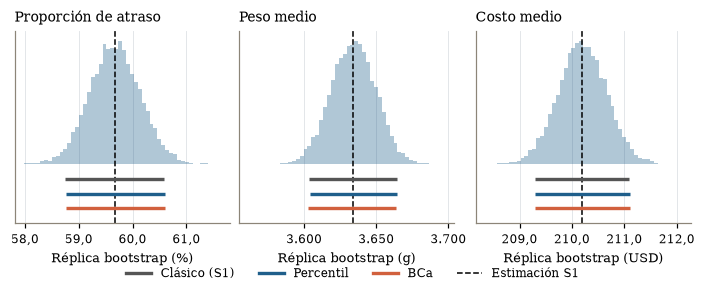

In [16]:
from matplotlib.lines import Line2D

PARAMETROS_CUERPO = [(('proporcion', TARGET, '1'), 'Proporción de atraso', 100, '%', 1),
                     (('media', 'peso_gramos', 'global'), 'Peso medio', 1, 'g', 0),
                     (('media', 'costo_producto', 'global'), 'Costo medio', 1, 'USD', 1)]
ESTILO_IC = [('Clásico (S1)', 'ic_clasico', GRIS), ('Percentil', 'ic_percentil', AZUL), ('BCa', 'ic_bca', TERRA)]
tabla_boot = bootstrap_intervalos.set_index(['estimando', 'variable', 'grupo'])

fig, ejes, _ = rejilla(3, ncols=3, alto=2.4)
for ax, (clave, titulo, escala, unidad, dec) in zip(ejes, PARAMETROS_CUERPO):
    fila = tabla_boot.loc[clave]
    alturas, _, _ = ax.hist(REPLICAS_Y02[clave] * escala, bins=50, color=AZUL, alpha=0.35, density=True)
    tope = alturas.max()
    ax.axvline(fila['estimacion_s1'] * escala, color='black', lw=1, ls='--')
    for j, (_, prefijo, color) in enumerate(ESTILO_IC):
        y_ic = -tope * (0.12 + 0.12 * j)
        ax.hlines(y_ic, fila[f'{prefijo}_inf'] * escala, fila[f'{prefijo}_sup'] * escala, color=color, lw=2.2)
    ax.set_ylim(-tope * 0.48, tope * 1.08)
    ax.set_yticks([])
    ax.set_title(titulo)
    ax.set_xlabel(f'Réplica bootstrap ({unidad})')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _, d=dec: num(v, d)))
fig.legend([Line2D([], [], color=c, lw=2.2) for _, _, c in ESTILO_IC] + [Line2D([], [], color='black', lw=1, ls='--')],
           [e for e, _, _ in ESTILO_IC] + ['Estimación S1'], loc='lower center', ncol=4,
           bbox_to_anchor=(0.5, -0.08))
guardar('fig_boot_1_parametros', fig)

#### Atlas del Anexo A

Distribución bootstrap de cada resultado del inventario a cargo de Y02, en páginas de 12 paneles ordenadas por ID, con la estimación de S1 y los IC percentil y BCa.

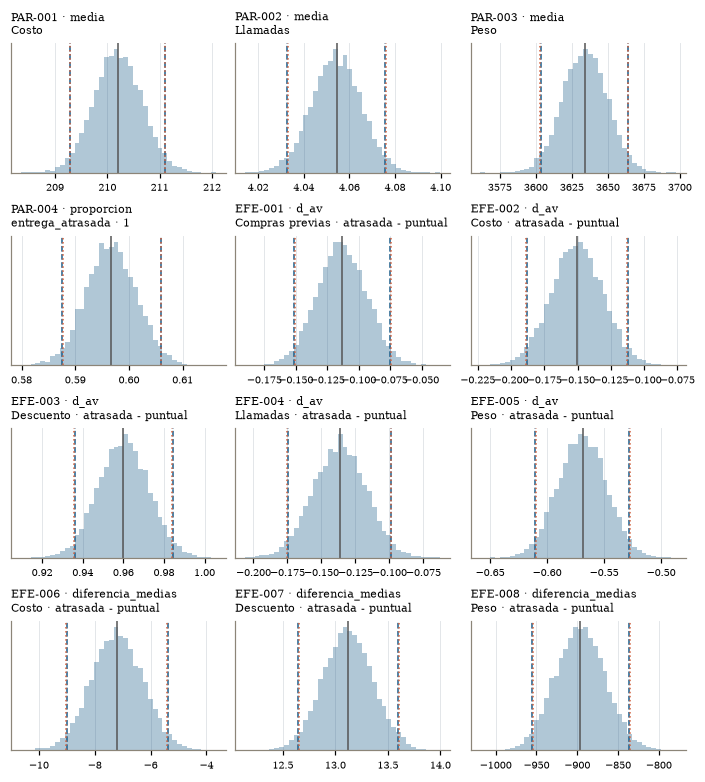

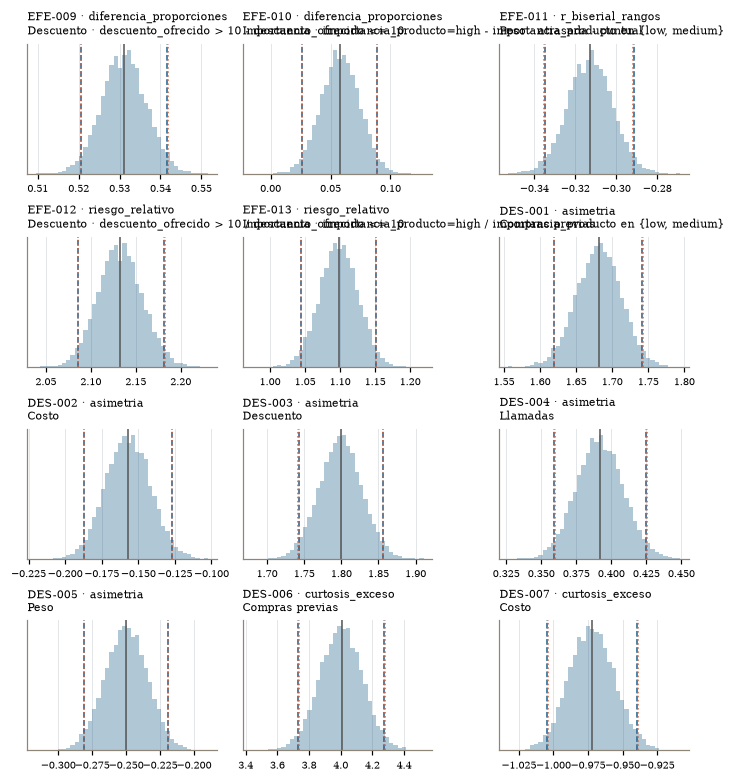

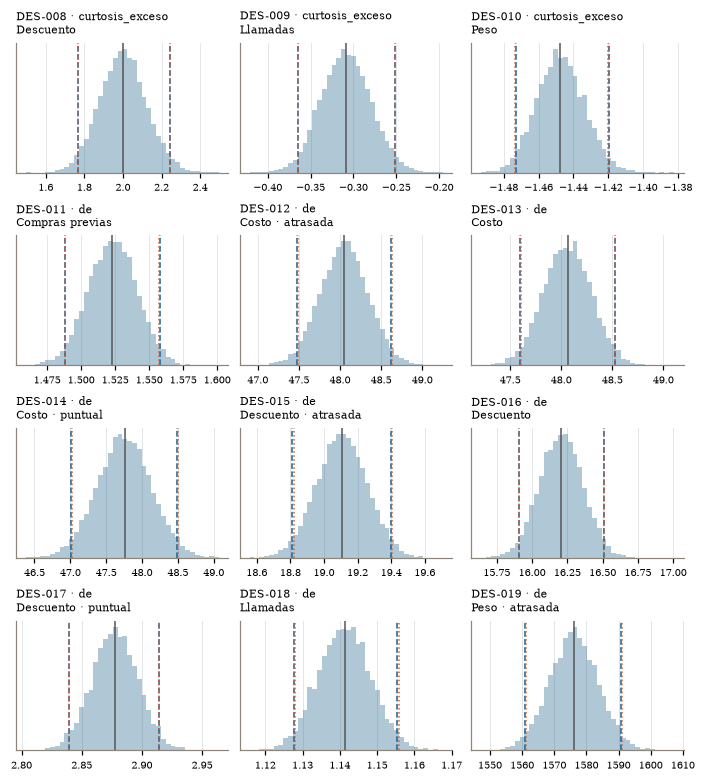

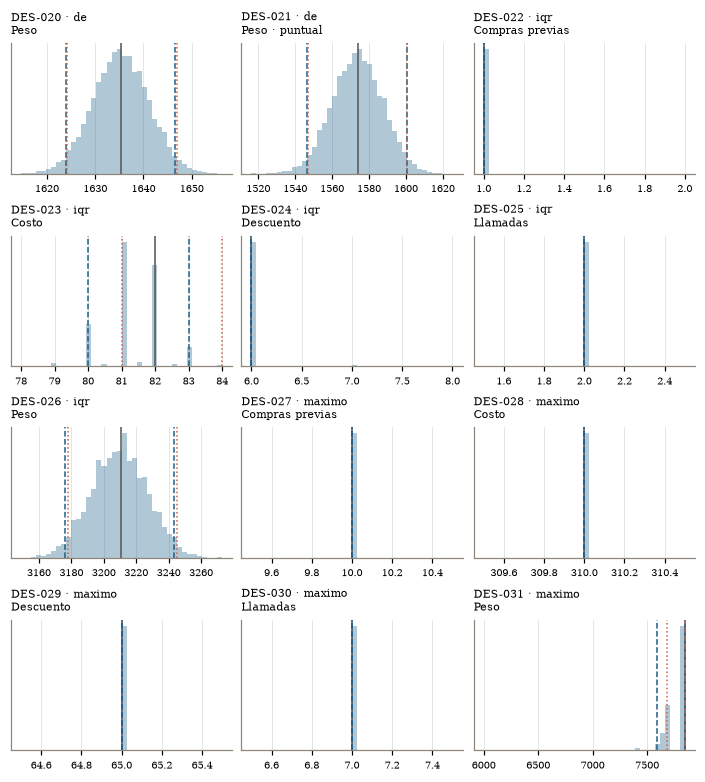

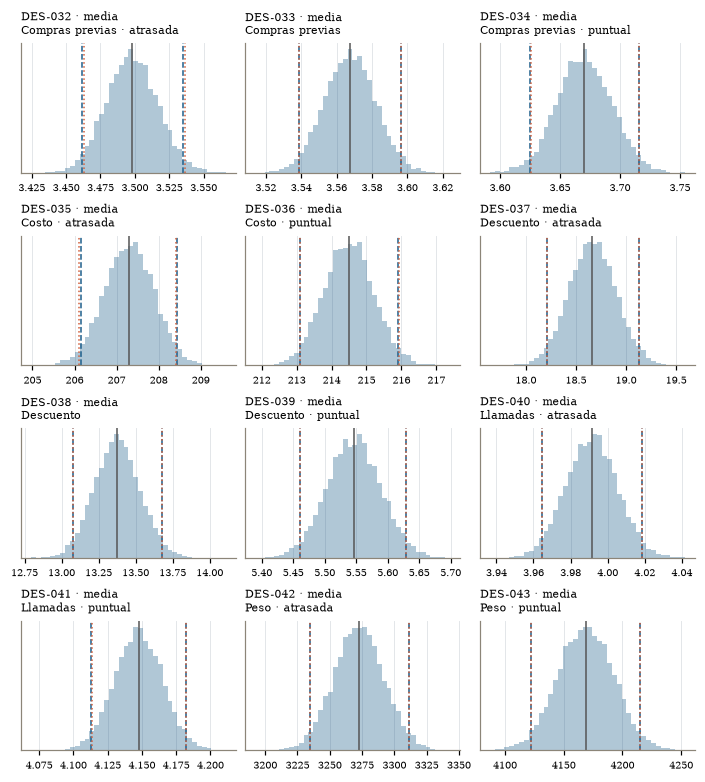

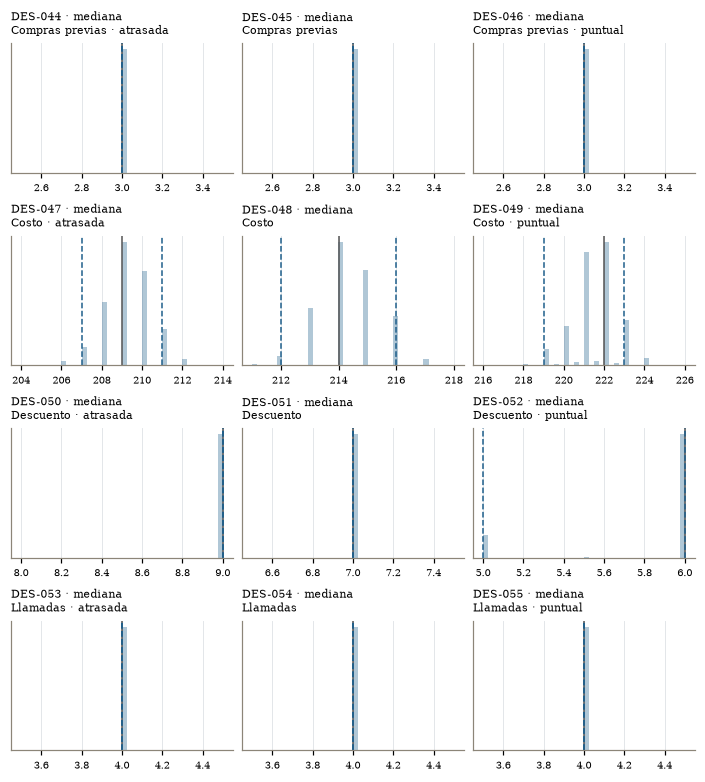

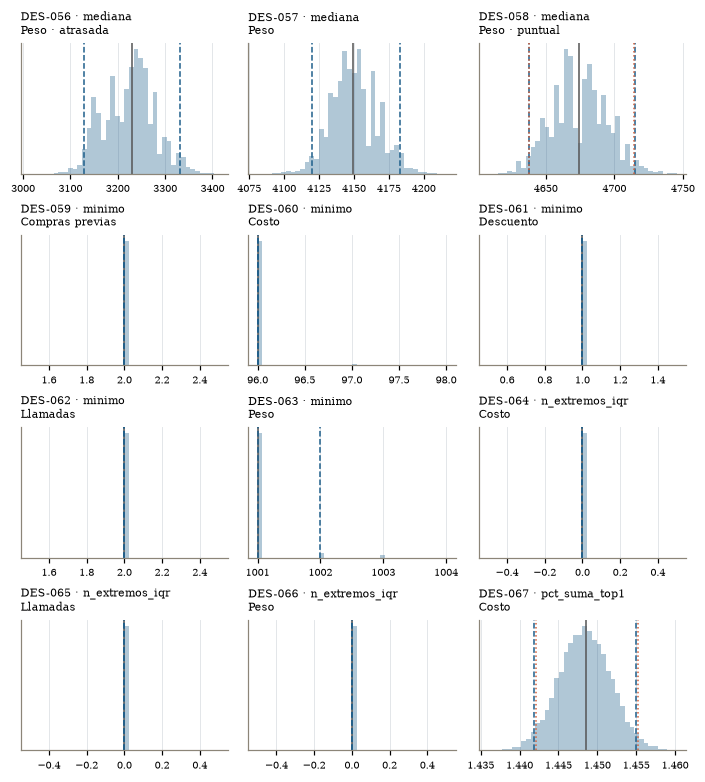

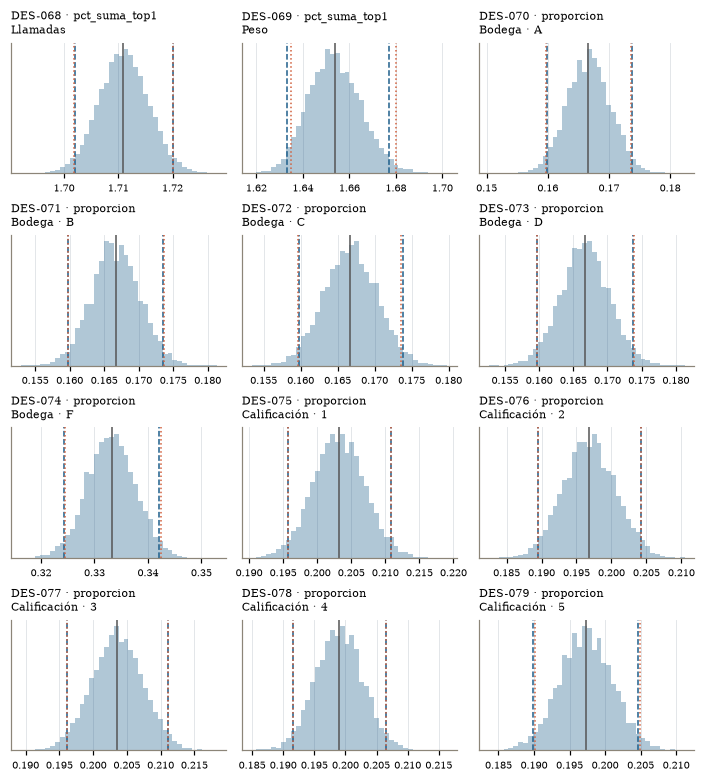

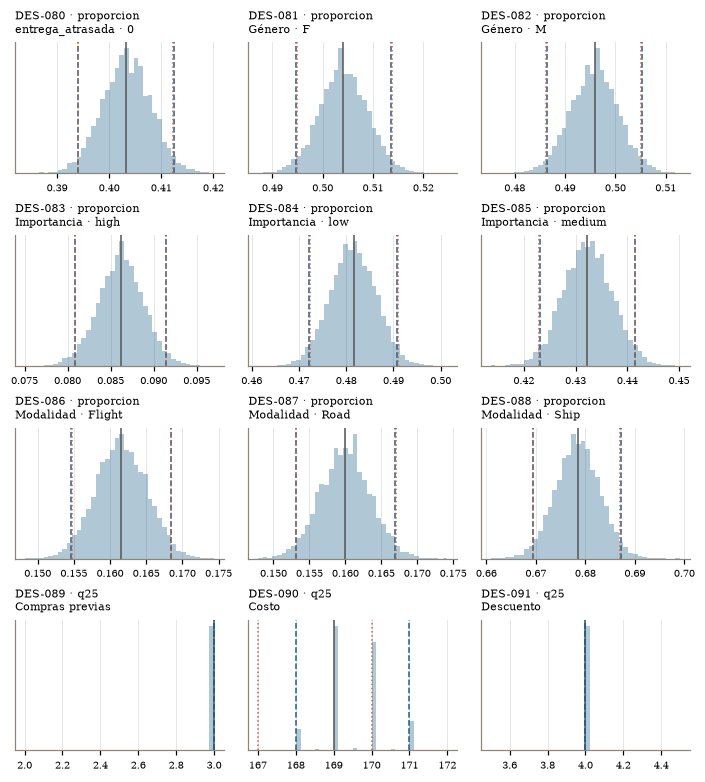

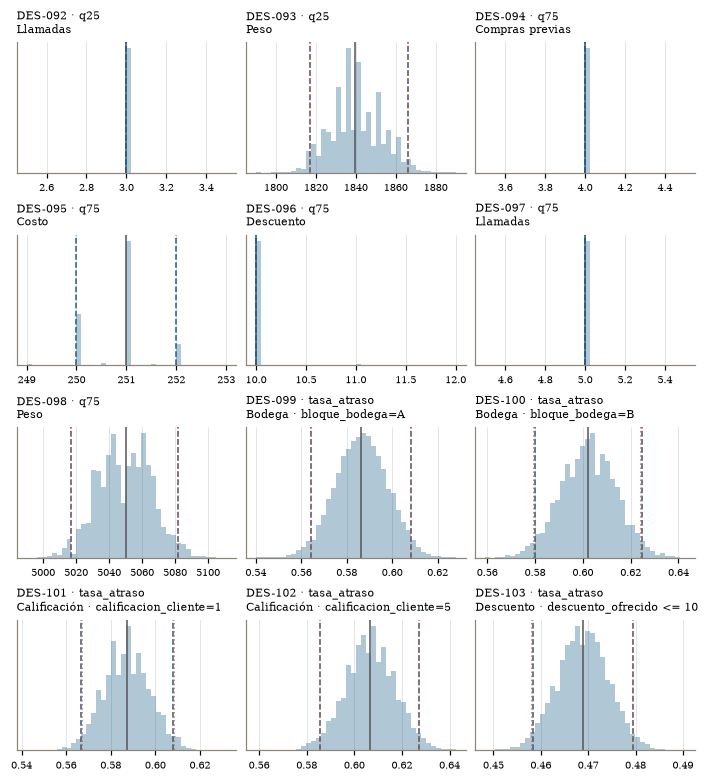

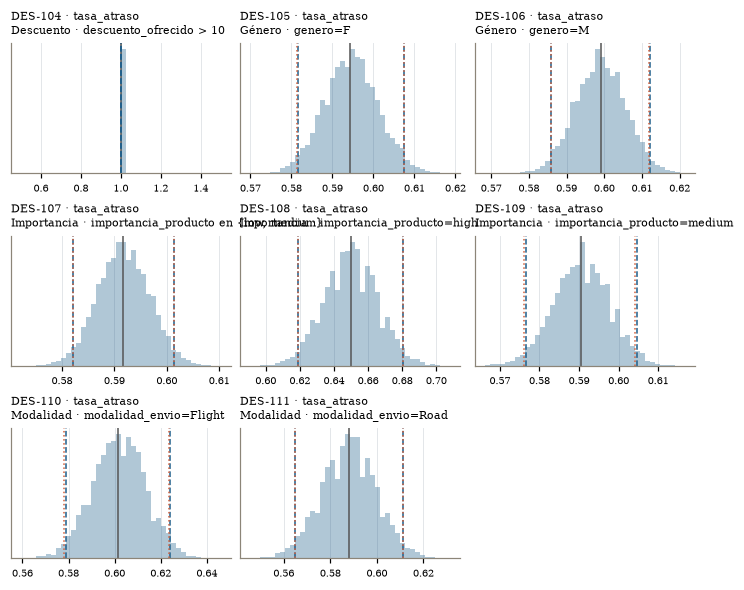

Atlas del Anexo A: 11 páginas, 128 distribuciones.


In [17]:
POR_PAGINA = 12
ids = bootstrap_intervalos['id'].tolist()
paginas = [ids[i:i + POR_PAGINA] for i in range(0, len(ids), POR_PAGINA)]
tabla_id = bootstrap_intervalos.set_index('id')

for p, ids_pagina in enumerate(paginas, start=1):
    fig, ejes, sobrantes = rejilla(len(ids_pagina), ncols=3, alto=1.75)
    for ax, i in zip(ejes, ids_pagina):
        fila = tabla_id.loc[i]
        clave = (fila['estimando'], fila['variable'], fila['grupo'])
        ax.hist(REPLICAS_Y02[clave], bins=40, color=AZUL, alpha=0.35)
        ax.axvline(fila['estimacion_s1'], color=GRIS, lw=1)
        for prefijo, color, estilo in [('ic_percentil', AZUL, '--'), ('ic_bca', TERRA, ':')]:
            for lado in ('inf', 'sup'):
                if pd.notna(fila[f'{prefijo}_{lado}']):
                    ax.axvline(fila[f'{prefijo}_{lado}'], color=color, lw=1, ls=estilo)
        grupo = '' if fila['grupo'] == 'global' else f" · {fila['grupo']}"
        ax.set_title(f"{i} · {fila['estimando']}\n{ETIQ_CORTA.get(fila['variable'], fila['variable'])}{grupo}",
                     fontsize=7)
        ax.set_yticks([])
        ax.tick_params(axis='x', labelsize=6.5)
    for ax in sobrantes:
        ax.set_visible(False)
    guardar(f'fig_boot_A{p:02d}_atlas', fig, formatos=('pdf',))
    plt.close(fig)
print(f'Atlas del Anexo A: {len(paginas)} páginas, {len(ids)} distribuciones.')

#### Interpretación

**Cobertura.** Los 128 resultados del inventario a cargo de Y02 tienen réplicas, IC percentil y diagnóstico. El BCa es estimable en 91; en los otros 37 queda registrado como no estimable y se informa el IC percentil con su advertencia:

- **23 con réplicas constantes:** medianas, cuartiles e IQR de variables enteras con muchos empates, mínimos y máximos, conteos de extremos iguales a 0 y la tasa de atraso con descuento > 10.
- **14 con *jackknife* sin variación:** medianas y cuartiles que no cambian al retirar un envío, por lo que la aceleración no se puede estimar.

**Parámetros principales.** Para la proporción de atraso y las medias de peso, costo y llamadas, los IC percentil y BCa prácticamente coinciden con el IC clásico de S1: los anchos difieren en menos de 1 % y $|z_0|$ y la aceleración son cercanos a 0, lo que indica distribuciones bootstrap simétricas. Con n = 10.999, la aproximación de Wilson y *t* de S1 queda respaldada, siempre bajo el supuesto de independencia y representatividad de los envíos.

**Efectos entre grupos.** Los 13 IC BCa de diferencias, $d_{av}$, biserial de rangos y riesgo relativo excluyen el valor nulo (0, o 1 para el riesgo relativo), con la misma dirección que en S1. Cuando S1 tiene IC clásico, los anchos difieren de él en menos de 2 %.

**Casos que no se interpretan como certeza.** La tasa de atraso con descuento > 10 vale 1 en todas las réplicas: el IC [1; 1] refleja una frontera muestral, no una certeza poblacional, y se conserva como advertencia el IC de Wilson de S1, [0,998551; 1]. En el costo, los cuartiles y el IQR toman pocos valores distintos y el BCa se desplaza respecto del percentil ($z_0$ hasta 0,70); allí el IC se lee como diagnóstico. Los mínimos y máximos se informan solo como diagnóstico descriptivo.

**Limitación.** El remuestreo cuantifica la variabilidad muestral, pero no corrige sesgos de selección ni demuestra causalidad.

### 2.2 Permutación de las siete pruebas

**Desarrollo completo:** Anexo B

**Método.** Cada contraste conserva su $H_0/H_1$, sus grupos, su dirección y su estadístico de S1. Se ejecutan **10.000 permutaciones por prueba**, recalculando siempre el estadístico:

| Prueba de S1 | Estadístico y esquema de permutación |
|---|---|
| T01: modalidad–atraso | $\chi^2$ de Pearson; se permuta el atraso entre modalidades, con márgenes fijos |
| T02: peso por atraso | *t* de Welch studentizada; se permutan las etiquetas de atraso |
| T03: descuento por atraso | *t* de Welch studentizada; mismo esquema |
| E1: peso por atraso | *U* de Mann–Whitney con empates; se permutan las etiquetas y se centra en $n_1 n_0/2$ |
| E2: atraso, importancia alta frente al resto | *z* de dos proporciones; se permuta el atraso entre grupos fijos |
| E3: atraso, descuento > 10 frente a ≤ 10 | *z* de dos proporciones; mismo esquema, advirtiendo la frontera $p_1 = 1$ |
| E4: costo por atraso | *t* de Welch studentizada; se permutan las etiquetas de atraso |

**Valor p.** Para *t* y *z* bilaterales se cuentan las excedencias de $|\text{estadístico}|$; para *U* bilateral, la distancia al centro $n_1 n_0/2$; para $\chi^2$, la cola superior:

$$p_{perm} = \frac{1 + \#\{\text{excedencias}\}}{B + 1}$$

Se guardan la fórmula, los empates y la resolución $1/10.001$. Los *p* registrados como 0 en S1 son subdesbordamiento numérico, no probabilidad exactamente nula.

**Multiplicidad.** Se aplica **Holm a la familia completa de los siete *p* de permutación** y se comparan las decisiones con las de la familia de Holm original, separando las comparaciones crudas de las ajustadas. Con B = 10.000 se reconoce una resolución limitada y una posible incertidumbre de decisión cerca del umbral; si hace falta, se amplía B con una regla documentada.

**Supuestos.** La exactitud requiere intercambiabilidad; la *t* de Welch studentizada tiene justificación asintótica bajo heterocedasticidad; Mann–Whitney contrasta distribuciones o rangos, no igualdad de medias.

**Evidencias:** `outputs/tablas/permutaciones_todas.csv` y las siete distribuciones nulas (Anexo B).

**Para el cuerpo del informe** *(pendiente)*: al menos una prueba relevante, T02 (peso por atraso), con $H_0/H_1$, efecto, estadístico observado, distribución nula, *p* original y de permutación, y discusión de supuestos. Se agrega otra solo si aporta una respuesta distinta y útil al problema; la comparación completa y Holm quedan en el Anexo B, conservando para las pruebas reportadas la referencia al ajuste familiar.

#### Hipótesis, referencias y criterio de precisión

Se conserva la familia de S1: T01 contrasta independencia entre modalidad y atraso;
T02, T03 y E4 contrastan diferencia de medias igual a cero frente a distinta de cero;
E1 contrasta igualdad de distribuciones de peso mediante rangos (bilateral);
E2 compara la tasa de atraso de importancia alta frente al resto y E3 la de descuento
>10 frente a ≤10 (igualdad frente a diferencia). Las diferencias de medias y U usan
atrasadas primero; las diferencias de proporciones usan alta o >10 primero.

Se fijan **B=10.000** y **α=0,05** antes de ejecutar. Se cuenta la cola superior de χ²,
la magnitud de t/z y la distancia de U a n₁n₀/2, incluyendo empates. El mínimo p
reportable es 1/(B+1). Los ceros de S1 se conservan como subdesbordamiento numérico.

**Regla de ampliación predefinida:** calcular intervalos binomiales exactos de la
probabilidad de excedencia, con cobertura simultánea de al menos 99% para las siete
pruebas (Bonferroni). Aplicar Holm a sus extremos. Si alguna decisión cruda o ajustada
puede cambiar dentro de esos límites, repetir la familia completa con B=50.000,
reiniciando su flujo para reproducibilidad. Si persiste la ambigüedad, reportarla como
incertidumbre Monte Carlo; no seguir simulando hasta obtener una decisión deseada.
Estos intervalos describen precisión computacional, no incertidumbre del efecto.

In [18]:
from IPython.display import display

B_PERM, ALFA_PERM = 10_000, 0.05
referencias_perm = pd.read_csv(TABLAS_S1 / 'contrastes_holm_7.csv').set_index('codigo').loc[list(ORDEN_PRUEBAS)]
referencias_estadistico = {}
for codigo, archivo, columna in [('T01', 'contraste_modalidad.csv', 'chi2'),
                                 ('T02', 'contraste_peso.csv', 't'),
                                 ('T03', 'contraste_descuento.csv', 't')]:
    referencias_estadistico[codigo] = pd.read_csv(TABLAS_S1 / archivo).iloc[0][columna]
for _, fila in pd.read_csv(TABLAS_S1 / 'contrastes_complementarios.csv').iterrows():
    referencias_estadistico[fila['codigo']] = fila['valor_estadistico']

# Trazabilidad previa: mismos estadísticos observados y mismo ajuste familiar de S1.
for codigo in ORDEN_PRUEBAS:
    y_prueba, calcular_prueba, _ = preparar_contraste(df, codigo)
    np.testing.assert_allclose(calcular_prueba(y_prueba), referencias_estadistico[codigo], rtol=1e-10, atol=1e-10)
np.testing.assert_allclose(ajustar_holm(referencias_perm['p']), referencias_perm['p_holm'], rtol=1e-12, atol=1e-15)

historial_precision = []
for B_actual in (B_PERM, 50_000):
    rng_perm = generador('permutaciones')
    filas_perm, REPLICAS_S01 = [], {}
    for codigo in ORDEN_PRUEBAS:
        resumen, replicas = permutar_contraste(df, codigo, rng_perm, B=B_actual)
        filas_perm.append(resumen)
        REPLICAS_S01[codigo] = replicas
    permutaciones_todas = pd.DataFrame(filas_perm)
    permutaciones_todas['p_perm_holm'] = ajustar_holm(permutaciones_todas['p_perm'])
    lo, hi = permutaciones_todas['p_cola_mc_inf'], permutaciones_todas['p_cola_mc_sup']
    permutaciones_todas['mc_ambiguo_crudo'] = (lo <= ALFA_PERM) & (hi > ALFA_PERM)
    permutaciones_todas['mc_ambiguo_holm'] = (ajustar_holm(lo) <= ALFA_PERM) & (ajustar_holm(hi) > ALFA_PERM)
    ambiguo = bool(permutaciones_todas[['mc_ambiguo_crudo', 'mc_ambiguo_holm']].to_numpy().any())
    historial_precision.append({'B': B_actual, 'decision_ambigua': ambiguo})
    if not ambiguo:
        break

permutaciones_todas['p_s1'] = permutaciones_todas['codigo'].map(referencias_perm['p'])
permutaciones_todas['p_s1_holm'] = permutaciones_todas['codigo'].map(referencias_perm['p_holm'])
permutaciones_todas['estadistico_s1'] = permutaciones_todas['codigo'].map(referencias_estadistico)
for origen in ('s1', 'perm'):
    for ajuste in ('', '_holm'):
        permutaciones_todas[f'rechaza_{origen}{ajuste}'] = permutaciones_todas[f'p_{origen}{ajuste}'] <= ALFA_PERM
permutaciones_todas['concordancia_cruda'] = permutaciones_todas['rechaza_s1'] == permutaciones_todas['rechaza_perm']
permutaciones_todas['concordancia_holm'] = permutaciones_todas['rechaza_s1_holm'] == permutaciones_todas['rechaza_perm_holm']
permutaciones_todas['semilla'] = SEMILLA
permutaciones_todas['flujo'] = 'permutaciones'
permutaciones_todas['alfa'] = ALFA_PERM
permutaciones_todas['fuente_s1'] = 'contrastes_holm_7.csv; tablas originales por contraste'
permutaciones_todas['ids_inventario'] = permutaciones_todas['codigo'].map(
    inventario[inventario['familia'] == 'pruebas'].groupby('grupo')['id'].agg(';'.join))
permutaciones_todas['advertencia'] = permutaciones_todas['codigo'].map({
    'T01': 'Intercambiabilidad bajo independencia.',
    'T02': 'Welch studentizado: justificación asintótica bajo heterocedasticidad.',
    'T03': 'p S1=0 por subdesbordamiento; descuento sin unidad acreditada; Welch asintótico.',
    'E1': 'Contrasta distribuciones/rangos, no igualdad de medias; rangos medios para empates.',
    'E2': 'Intercambiabilidad bajo igualdad de tasas.',
    'E3': 'p S1=0 por subdesbordamiento; tasa observada del grupo >10 en frontera 1.',
    'E4': 'Welch studentizado: justificación asintótica bajo heterocedasticidad.'})
assert len(permutaciones_todas) == 7 and permutaciones_todas['B'].ge(10_000).all()
assert permutaciones_todas['p_perm'].between(1/(B_actual+1), 1).all()
permutaciones_todas.to_csv(TABLAS_S2 / 'permutaciones_todas.csv', index=False)
# Conservar las distribuciones completas para auditar las colas y reutilizar evidencia.
pd.DataFrame(REPLICAS_S01).rename_axis('replica').to_csv(TABLAS_S2 / 'permutaciones_distribuciones.csv', index=True)
import platform
import scipy
import statsmodels
metadatos_s01 = dict(semilla=SEMILLA, flujo='permutaciones', spawn_key=list(SEMILLAS_FLUJO['permutaciones'].spawn_key),
    orden_pruebas=list(ORDEN_PRUEBAS), n=len(df), alfa=ALFA_PERM, historial_precision=historial_precision,
    commit_s1=COMMIT_S1, sha256_datos=HUELLA_DATOS,
    versiones=dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                   scipy=scipy.__version__, statsmodels=statsmodels.__version__))
(TABLAS_S2 / 'permutaciones_metadatos.json').write_text(json.dumps(metadatos_s01, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'siete pruebas, B={B_actual:,}, resolución={1/(B_actual+1):.8f}.')
display(permutaciones_todas[['codigo', 'estadistico_observado', 'p_s1', 'p_perm',
    'p_s1_holm', 'p_perm_holm', 'concordancia_cruda', 'concordancia_holm', 'mc_ambiguo_holm']])

siete pruebas, B=10,000, resolución=0.00009999.


,codigo,estadistico_observado,p_s1,p_perm,p_s1_holm,p_perm_holm,concordancia_cruda,concordancia_holm,mc_ambiguo_holm
0,T01,7.434357e-01,6.895488e-01,0.691131,6.895488e-01,0.691131,True,True,False
1,T02,-2.927223e+01,1.930930e-180,0.000100,9.654651e-180,0.000700,True,True,False
2,T03,5.470287e+01,0.000000e+00,0.000100,0.000000e+00,0.000700,True,True,False
3,E1,1.000033e+07,3.398797e-171,0.000100,1.359519e-170,0.000700,True,True,False
4,E2,3.486294e+00,4.897629e-04,0.000800,9.795259e-04,0.001600,True,True,False
5,E3,4.854035e+01,0.000000e+00,0.000100,0.000000e+00,0.000700,True,True,False
6,E4,-7.747115e+00,1.035728e-14,0.000100,3.107184e-14,0.000700,True,True,False


#### Distribuciones nulas de las siete pruebas

Cada figura muestra el estadístico recalculado bajo permutación y el observado.
Para U se representa U−n₁n₀/2; para los contrastes bilaterales se marca también
el umbral simétrico. El panel izquierdo permite apreciar la distribución nula;
el derecho conserva su distancia real al estadístico observado cuando este cae
muy lejos de la distribución. Son figuras del notebook, sin selección editorial
para el informe ni generación de anexos.

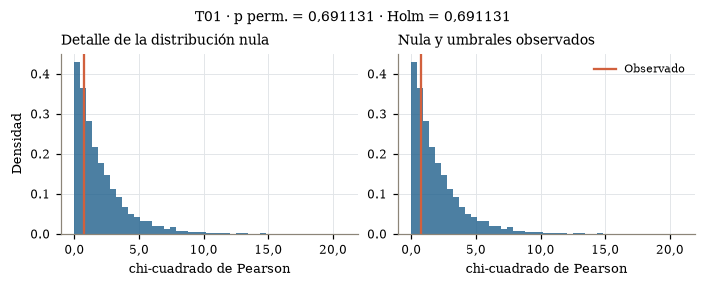

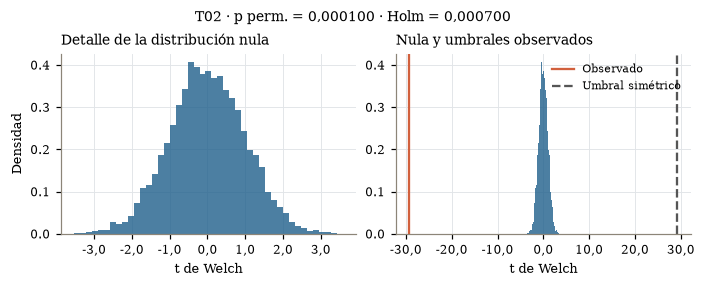

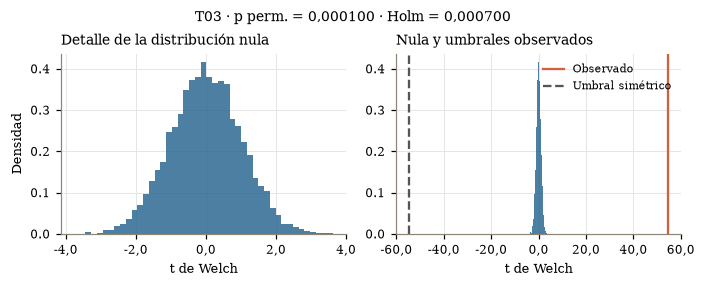

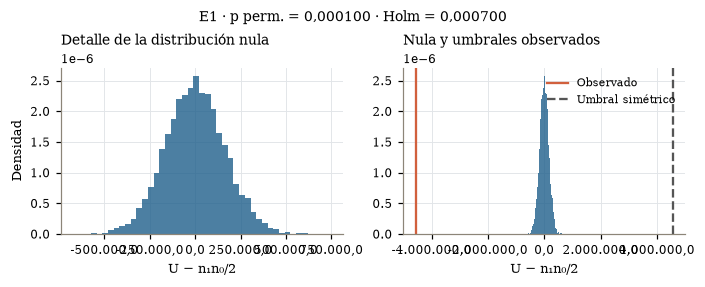

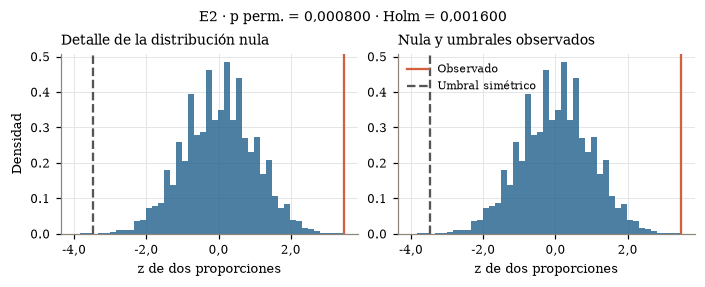

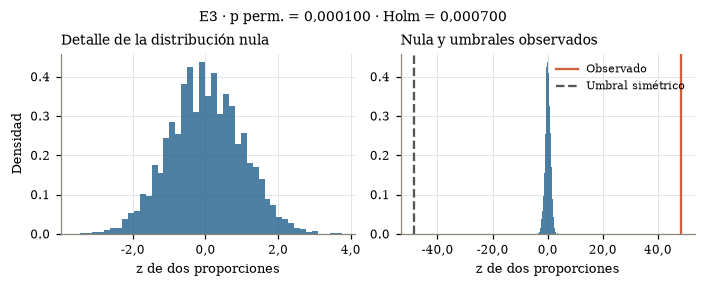

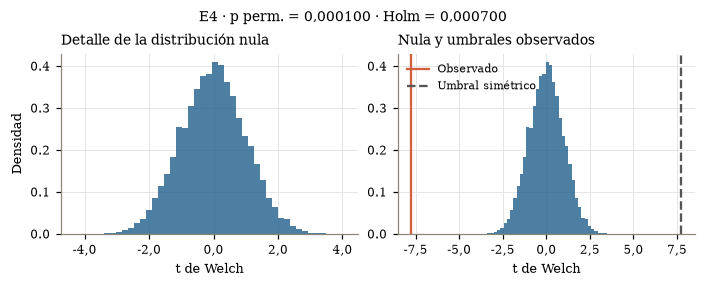

In [19]:
for fila in permutaciones_todas.to_dict('records'):
    codigo = fila['codigo']
    valores = REPLICAS_S01[codigo] - fila['centro']
    observado = fila['estadistico_observado'] - fila['centro']
    fig, ejes = plt.subplots(1, 2, figsize=(ANCHO, 2.5))
    for ax in ejes:
        ax.hist(valores, bins=45, color=AZUL, alpha=0.8, density=True)
        ax.set_xlabel('U − n₁n₀/2' if codigo == 'E1' else fila['estadistico'])
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: num(x, 1)))
    limites_nulos = ejes[0].get_xlim()
    for ax in ejes:
        ax.axvline(observado, color=TERRA, label='Observado')
        if fila['cola'] == 'bilateral':
            ax.axvline(-observado, color=GRIS, linestyle='--', label='Umbral simétrico')
    ejes[0].set_xlim(limites_nulos)
    ejes[0].set_title('Detalle de la distribución nula')
    ejes[0].set_ylabel('Densidad')
    ejes[1].set_title('Nula y umbrales observados')
    ejes[1].legend(fontsize=7)
    fig.suptitle(f"{codigo} · p perm. = {num(fila['p_perm'], 6)} · Holm = {num(fila['p_perm_holm'], 6)}", fontsize=9)
    guardar(f'fig_perm_{ORDEN_PRUEBAS.index(codigo)+1}_{codigo.lower()}', fig)
    plt.close(fig)

#### Interpretación y límites

Con **10.000 permutaciones por prueba**, las siete decisiones concuerdan con S1,
tanto sin ajuste como tras Holm (α=0,05). Los intervalos de precisión Monte Carlo
no cruzan los umbrales de decisión crudos ni ajustados según la regla predefinida;
por ello no se activó la ampliación a 50.000. Esto respalda las decisiones bajo los
supuestos del remuestreo; no demuestra que los supuestos se cumplan en el dataset.

| Prueba | p de S1 | p permutación | p permutación Holm | Lectura |
|---|---:|---:|---:|---|
| T01: modalidad–atraso | 0,689549 | 0,691131 | 0,691131 | No se rechaza independencia |
| T02: peso por atraso | 1,93×10⁻¹⁸⁰ | 0,000100 | 0,000700 | Se rechaza igualdad de medias |
| T03: descuento por atraso | 0 registrado | 0,000100 | 0,000700 | Se rechaza igualdad de medias |
| E1: peso, Mann–Whitney | 3,40×10⁻¹⁷¹ | 0,000100 | 0,000700 | Se rechaza igualdad de distribuciones |
| E2: importancia alta/resto | 0,000490 | 0,000800 | 0,001600 | Se rechaza igualdad de tasas |
| E3: descuento >10/≤10 | 0 registrado | 0,000100 | 0,000700 | Se rechaza igualdad de tasas |
| E4: costo por atraso | 1,04×10⁻¹⁴ | 0,000100 | 0,000700 | Se rechaza igualdad de medias |

Los valores de la tabla se redondean; los CSV conservan la precisión del cálculo.
En T02, T03, E1, E3 y E4 no hubo excedencias: el p reportado es exactamente
**1/10.001**, no cero ni una estimación precisa de un p extremadamente pequeño.
Sus p ajustados coinciden por la resolución finita, no porque los efectos sean iguales.
E2 tuvo siete excedencias y T01 tuvo 6.911. La diferencia numérica entre los p de E2
(0,000490 en S1 y 0,000800 por permutación) no cambia su decisión y debe leerse
junto con la incertidumbre Monte Carlo exportada. Los ceros de S1 en T03 y E3
son subdesbordamiento numérico, nunca probabilidades exactamente nulas.

**Peso (T02 y E1).** El peso medio de los envíos atrasados es 3.272,64 g y el de
los puntuales 4.168,67 g: diferencia de **−896,03 g**, con t de Welch=−29,2722.
El IC clásico de S1 es [−956,03; −836,03] g; se cita como referencia de S1, no como
un IC obtenido por permutación. La evidencia contra igualdad de medias persiste
tras el ajuste familiar. E1 también detecta diferencias en las distribuciones/rangos
(U=10.000.332,5; biserial de rangos=−0,3130), pero no prueba la misma hipótesis
sobre medias ni constituye evidencia independiente, pues usa los mismos envíos.

**Otros contrastes.** T01 presenta una asociación muy pequeña (V de Cramér=0,0082);
no rechazar independencia no demuestra equivalencia entre modalidades. En T03,
los atrasados tienen un descuento medio 13,12 unidades mayor; la unidad original
no está acreditada y no se interpreta como porcentaje. En E2, la tasa de atraso
es 5,81 puntos porcentuales mayor en importancia alta que en el resto. E3 muestra
una diferencia de 53,11 puntos porcentuales, pero los 2.647 envíos con descuento >10
están atrasados: esa frontera muestral requiere la sensibilidad restringida de S03,
no una afirmación de certeza poblacional. En E4, la diferencia de costo medio es
−7,21 USD; la significación no determina por sí sola su relevancia operativa.

**Elección del método y supuestos.** La permutación evita depender de una forma
paramétrica para la distribución nula si las etiquetas son intercambiables bajo H₀.
Esa condición no se deduce de obtener concordancia con S1. Para contrastar medias
con varianzas distintas se conserva Welch studentizado: su permutación tiene
justificación asintótica bajo heterocedasticidad, no exactitud finita garantizada
bajo la sola igualdad de medias. Para T01 y los contrastes de tasas, la permutación
es una comparación condicionada a los márgenes observados. En este análisis ambas
vías resultan complementarias: Welch conserva el estimando de medias, mientras
Mann–Whitney responde una pregunta sobre distribuciones/rangos. No se elige un
método por producir el menor p.


## 3. Correlaciones, asociaciones y simulación Monte Carlo

### 3.1 Todas las correlaciones y asociaciones

**Responsable:** Sebastián · **Revisor:** José

**Universo completo:**

| Fuente de S1 | Coeficientes |
|---|---|
| `correlacion_spearman.csv` | 10 pares únicos entre cinco variables cuantitativas |
| `correlacion_dependiente_cuantitativas.csv` | 5 punto-biseriales y 5 Spearman con el atraso |
| `asociacion_cramer.csv` | 10 pares únicos entre cinco variables categóricas |
| `relacion_dependiente_cualitativas.csv` | 5 asociaciones V de Cramér con el atraso |

**Resultado esperado:** 20 correlaciones y 15 asociaciones, con estimación de S1, n/B, EE, IC, ancho, diagnóstico y sensibilidad. Las asociaciones repetidas en T01 se validan una vez y se referencian desde ambos apartados.

**Método.** Se remuestrean filas emparejadas **10.000 veces por coeficiente**, con IC percentil al 95 %. Se conserva el tipo de coeficiente y se recalculan los rangos de Spearman en cada remuestra. Se excluyen las diagonales y los pares simétricos duplicados, y nunca se remuestrean las columnas por separado.

**Criterios de interpretación.**

- **Correlaciones:** inclusión del cero, signo y precisión; distinguir un efecto débil de uno inestable.
- **V de Cramér**, acotada en [0, 1]: no se traslada la lógica del signo. Se informan la magnitud, el ancho y el sesgo del *bootstrap* cerca de cero; la independencia no se resuelve solo con un IC percentil positivo.

**Evidencias:** `outputs/tablas/correlaciones_bootstrap.csv`, `outputs/tablas/asociaciones_bootstrap.csv`, atlas de distribuciones y todos los IC (Anexo C).

**Para el cuerpo del informe** *(pendiente)*: entre tres y cinco correlaciones de mayor relevancia para los atrasos, con distribución, IC 95 %, estabilidad y magnitud. Propuesta inicial: atraso–descuento y atraso–peso (punto-biseriales) y descuento–peso (Spearman). Dos coeficientes del mismo par no cuentan como dos hallazgos, y no se agregan 35 pruebas nuevas a la familia de Holm original.

#### Cobertura, remuestreo y lectura de estabilidad

Se toma el inventario congelado: 15 Spearman (10 entre variables cuantitativas y
5 con atraso), 5 punto-biseriales y 15 V de Cramér. Los diez valores p de
correlación publicados en S1 son referencias de esos mismos coeficientes, no diez
coeficientes adicionales. La asociación modalidad–atraso coincide con la de T01 y
se referencia sin agregar otra prueba a la familia Holm.

Cada una de las **10.000 remuestras** contiene 10.999 filas completas. Se comparten
los índices entre los 35 coeficientes para conservar el emparejamiento. Se recalculan
los rangos medios de Spearman dentro de cada remuestra, incluidos los empates.
El punto-biserial equivale a Pearson con atraso codificado 0/1. V de Cramér usa
χ² sin corrección de continuidad ni corrección de sesgo, como las tablas de S1.
Se trabaja en lotes de 32 para limitar memoria; el tamaño del lote no cambia el
flujo de índices ni el resultado.

Se exportan estimación, sesgo bootstrap, error estándar, IC percentil al 95%, ancho
y réplicas indefinidas. Para correlaciones se informa si el IC incluye cero y si
conserva el signo; la amplitud cuantifica precisión sin imponer un umbral arbitrario
de «estabilidad». Un coeficiente pequeño puede tener signo preciso. Los IC son
**marginales**, no intervalos simultáneos para toda la familia.

V de Cramér está acotada entre 0 y 1: un IC percentil positivo no demuestra
independencia ni dependencia, especialmente cerca de cero. Se examinan magnitud,
ancho y sesgo. La sensibilidad a tratamientos de extremos se completará después;
no se declara robustez frente a escenarios que aún no se ejecutaron.

In [20]:
from IPython.display import display

catalogo_coef = inventario[inventario['estimando'].isin(
    ['rho_spearman', 'r_punto_biserial', 'v_cramer'])].copy().sort_values('id').reset_index(drop=True)
assert catalogo_coef['id'].is_unique and len(catalogo_coef)==35
assert catalogo_coef['estimando'].value_counts().to_dict()=={
    'rho_spearman': 15, 'r_punto_biserial': 5, 'v_cramer': 15}
preparados_coef = preparar_coeficientes(df, catalogo_coef)
observados_coef = coeficientes_lote(preparados_coef, np.arange(len(df))[None, :])[0]
np.testing.assert_allclose(observados_coef, catalogo_coef['estimacion_s1'].astype(float), rtol=1e-10, atol=1e-12)

B_COEF, LOTE_COEF = 10_000, 32
tabla_coeficientes, REPLICAS_COEFICIENTES = bootstrap_coeficientes(
    df, catalogo_coef, generador('bootstrap_coeficientes'), B=B_COEF, lote=LOTE_COEF)
tiempo_coeficientes = tabla_coeficientes.attrs['segundos']
for nombre, valor in [('semilla', SEMILLA), ('flujo', 'bootstrap_coeficientes')]:
    tabla_coeficientes[nombre] = valor
es_asociacion = tabla_coeficientes['estimando'].eq('v_cramer')
correlaciones_bootstrap = tabla_coeficientes[~es_asociacion].copy()
asociaciones_bootstrap = tabla_coeficientes[es_asociacion].copy()
assert (len(correlaciones_bootstrap), len(asociaciones_bootstrap))==(20, 15)
assert tabla_coeficientes['B_validas'].eq(B_COEF).all(), 'Revisar réplicas indefinidas antes de interpretar.'
assert correlaciones_bootstrap[['ic_inf','ic_sup']].ge(-1).all().all()
assert correlaciones_bootstrap[['ic_inf','ic_sup']].le(1).all().all()
assert asociaciones_bootstrap[['ic_inf','ic_sup']].ge(0).all().all()
assert asociaciones_bootstrap[['ic_inf','ic_sup']].le(1+1e-12).all().all()
for nombre, tabla in [('correlaciones_bootstrap', correlaciones_bootstrap),
                      ('asociaciones_bootstrap', asociaciones_bootstrap)]:
    tabla.to_csv(TABLAS_S2 / f'{nombre}.csv', index=False)
pd.DataFrame(REPLICAS_COEFICIENTES, columns=catalogo_coef['id']).rename_axis('replica').to_csv(
    TABLAS_S2 / 'coeficientes_replicas.csv')
import platform
import scipy
metadatos_coef = dict(semilla=SEMILLA, flujo='bootstrap_coeficientes',
    spawn_key=list(SEMILLAS_FLUJO['bootstrap_coeficientes'].spawn_key),
    orden_ids=catalogo_coef['id'].tolist(), n=len(df), B=B_COEF, lote=LOTE_COEF,
    nivel_ic=0.95, segundos=tiempo_coeficientes, commit_s1=COMMIT_S1, sha256_datos=HUELLA_DATOS,
    versiones=dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, scipy=scipy.__version__),
    sensibilidad='pendiente', intervalos='marginales, no simultáneos')
(TABLAS_S2 / 'coeficientes_metadatos.json').write_text(json.dumps(metadatos_coef, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'Bootstrap completado: {len(correlaciones_bootstrap)} correlaciones y {len(asociaciones_bootstrap)} asociaciones; {B_COEF:,} remuestras emparejadas.')
display(tabla_coeficientes[['id','estimando','variable','estimacion_s1','ic_inf','ic_sup','ee','sesgo','diagnostico']])

Bootstrap completado: 20 correlaciones y 15 asociaciones; 10,000 remuestras emparejadas.


,id,estimando,variable,estimacion_s1,ic_inf,ic_sup,ee,sesgo,diagnostico
0,ASO-001,v_cramer,bloque_bodega|calificacion_cliente,0.015084,0.016639,0.032109,0.003934,0.008913,magnitud y precisión; IC no prueba independencia
1,ASO-002,v_cramer,bloque_bodega|entrega_atrasada,0.009952,0.007618,0.035617,0.007184,0.010297,magnitud y precisión; IC no prueba independencia
2,ASO-003,v_cramer,bloque_bodega|genero,0.008656,0.007594,0.034333,0.006970,0.011064,magnitud y precisión; IC no prueba independencia
3,ASO-004,v_cramer,bloque_bodega|importancia_producto,0.019139,0.015509,0.038214,0.005829,0.007358,magnitud y precisión; IC no prueba independencia
4,ASO-005,v_cramer,bloque_bodega|modalidad_envio,0.001061,0.009996,0.028220,0.004676,0.017499,magnitud y precisión; IC no prueba independencia
5,ASO-006,v_cramer,calificacion_cliente|entrega_atrasada,0.017057,0.009460,0.040772,0.008000,0.007235,magnitud y precisión; IC no prueba independencia
6,ASO-007,v_cramer,calificacion_cliente|genero,0.016395,0.009478,0.040535,0.007988,0.007461,magnitud y precisión; IC no prueba independencia
7,ASO-008,v_cramer,calificacion_cliente|importancia_producto,0.018052,0.014803,0.037035,0.005721,0.007501,magnitud y precisión; IC no prueba independencia
8,ASO-009,v_cramer,calificacion_cliente|modalidad_envio,0.017024,0.014516,0.036368,0.005627,0.007947,magnitud y precisión; IC no prueba independencia
9,ASO-010,v_cramer,genero|entrega_atrasada,0.004689,0.000337,0.023543,0.006377,0.003873,magnitud y precisión; IC no prueba independencia


#### Distribuciones e intervalos de todos los coeficientes

Las figuras cubren los 35 coeficientes en el orden del inventario, con la estimación
de S1 y los extremos del IC percentil. Las correlaciones y las asociaciones se
muestran por separado para conservar sus dominios e interpretación. Estas figuras
son evidencia del notebook; la selección de contenido del informe permanece pendiente.

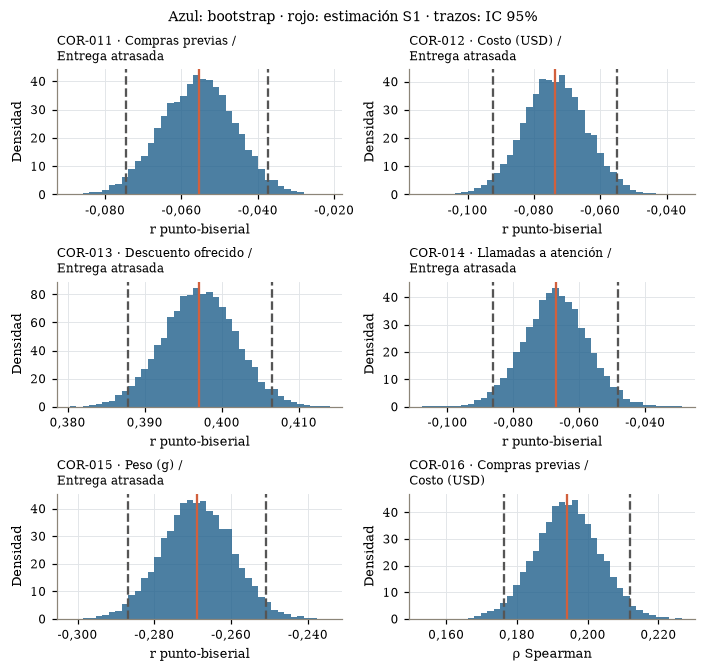

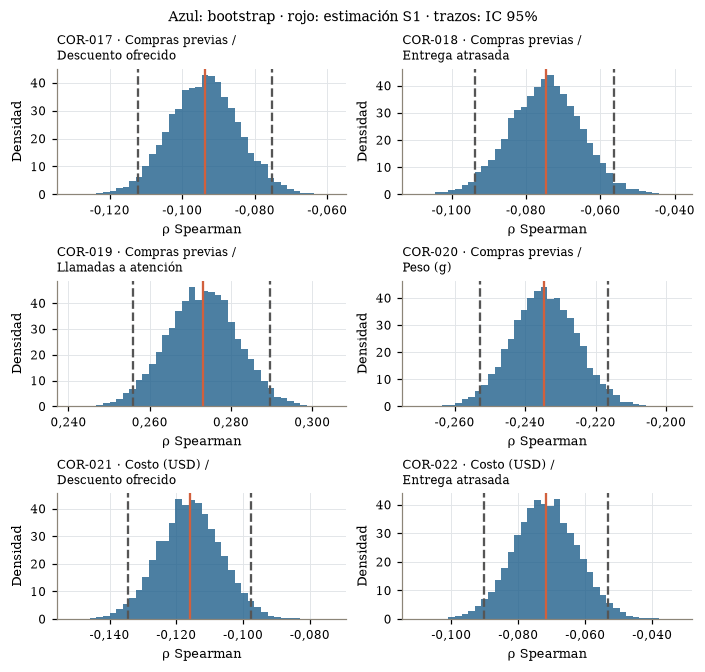

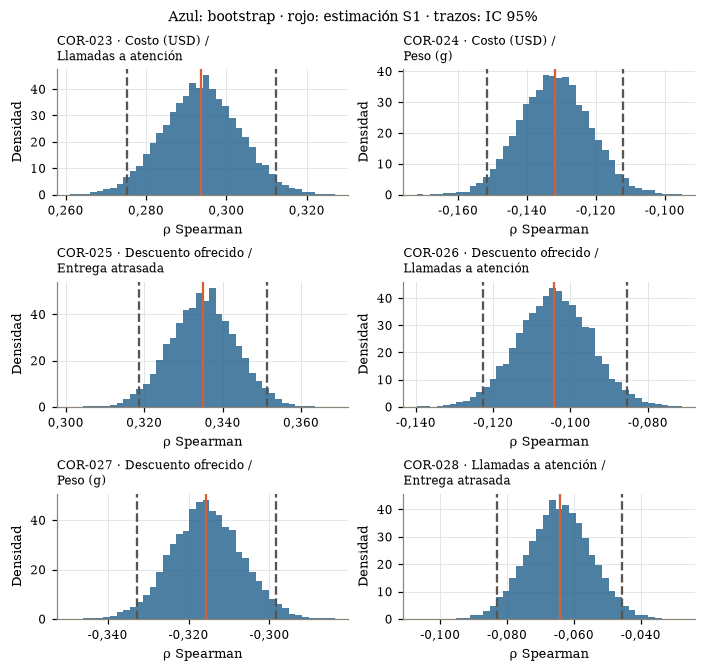

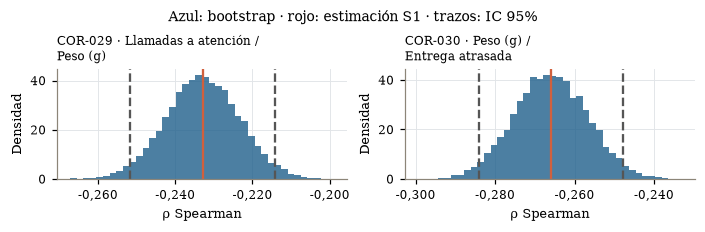

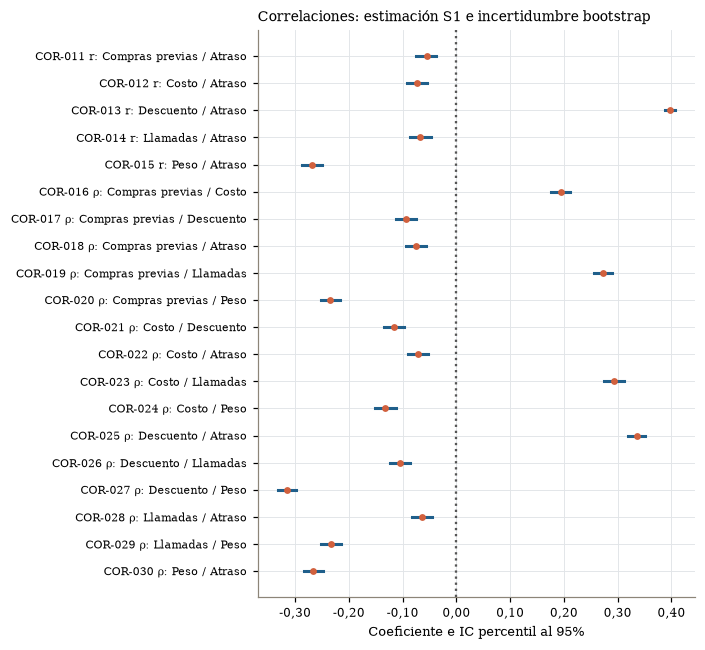

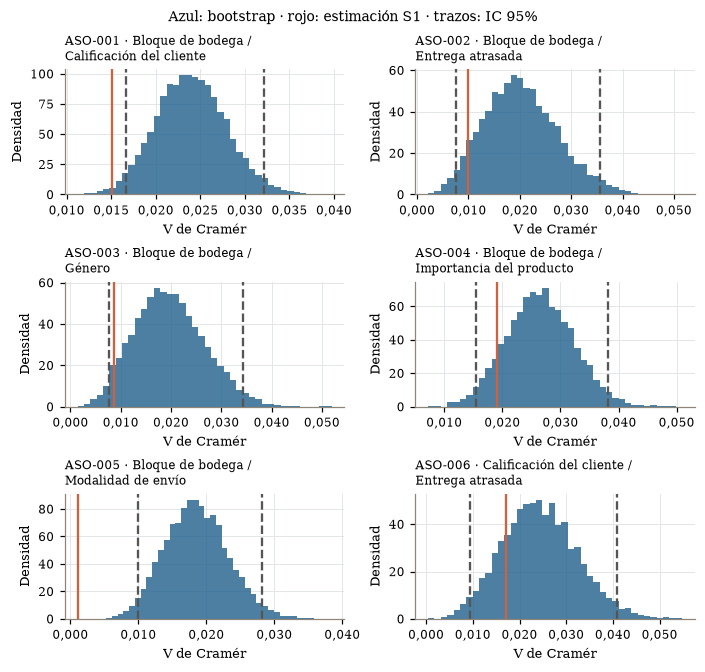

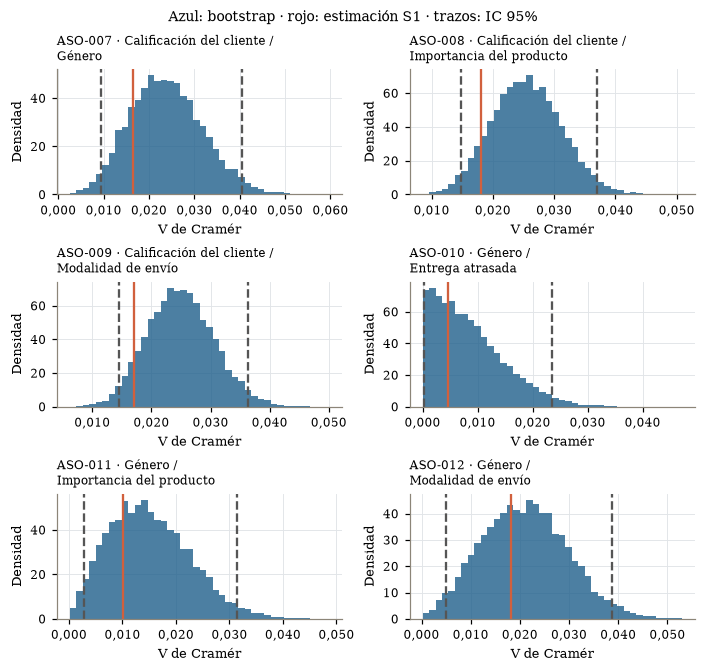

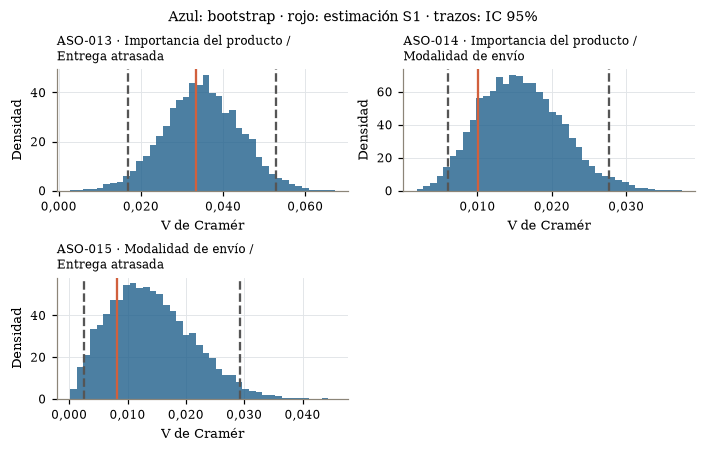

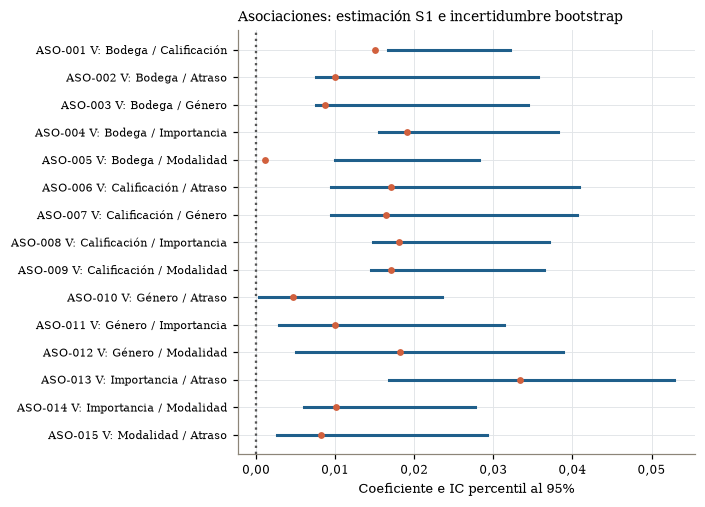

In [21]:
from matplotlib.lines import Line2D

posiciones_coef = {identificador: i for i, identificador in enumerate(catalogo_coef['id'])}
for familia, tabla in [('correlaciones', correlaciones_bootstrap), ('asociaciones', asociaciones_bootstrap)]:
    for pagina, inicio in enumerate(range(0, len(tabla), 6), 1):
        grupo = tabla.iloc[inicio:inicio+6]
        fig, ejes, sobrantes = rejilla(len(grupo), ncols=2, alto=2.0)
        for ax, (_, r) in zip(ejes, grupo.iterrows()):
            valores = REPLICAS_COEFICIENTES[:, posiciones_coef[r['id']]]
            ax.hist(valores, bins=40, color=AZUL, alpha=0.8, density=True)
            ax.axvline(r['estimacion_s1'], color=TERRA)
            for limite in (r['ic_inf'], r['ic_sup']):
                ax.axvline(limite, color=GRIS, linestyle='--')
            a, b = r['variable'].split('|')
            etiqueta = 'ρ Spearman' if r['estimando']=='rho_spearman' else ('r punto-biserial' if r['estimando']=='r_punto_biserial' else 'V de Cramér')
            ax.set_title(f"{r['id']} · {etiq(a)} /\n{etiq(b)}", fontsize=8)
            ax.set_xlabel(etiqueta)
            ax.set_ylabel('Densidad')
            ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: num(x, 3)))
        for ax in sobrantes: ax.set_visible(False)
        fig.suptitle('Azul: bootstrap · rojo: estimación S1 · trazos: IC 95%', fontsize=9)
        guardar(f'fig_cor_{familia}_distribuciones_{pagina}', fig)
        plt.close(fig)
    fig, ax = plt.subplots(figsize=(ANCHO, max(4.5, len(tabla)*0.29)))
    for k, (_, r) in enumerate(tabla.iterrows()):
        ax.plot([r['ic_inf'], r['ic_sup']], [k, k], color=AZUL, linewidth=2)
        ax.scatter(r['estimacion_s1'], k, color=TERRA, s=12, zorder=3)
    etiquetas = []
    for _, r in tabla.iterrows():
        a, b = r['variable'].split('|')
        metodo = 'ρ' if r['estimando']=='rho_spearman' else ('r' if r['estimando']=='r_punto_biserial' else 'V')
        etiquetas.append(f"{r['id']} {metodo}: {ETIQ_CORTA.get(a, 'Atraso')} / {ETIQ_CORTA.get(b, 'Atraso')}")
    ax.set_yticks(range(len(tabla)), etiquetas, fontsize=7)
    ax.invert_yaxis()
    ax.axvline(0, color=GRIS, linestyle=':')
    ax.set_xlabel('Coeficiente e IC percentil al 95%')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: num(x, 2)))
    ax.set_title(f'{familia.capitalize()}: estimación S1 e incertidumbre bootstrap')
    guardar(f'fig_cor_{familia}_intervalos', fig)
    plt.close(fig)

#### Interpretación de correlaciones y asociaciones

**Cobertura y precisión.** Se ejecutaron 10.000 remuestras conjuntas para los 35
coeficientes, sin réplicas indefinidas. Los valores observados reproducen los de S1.
Las **20 correlaciones conservan su signo** en sus IC percentiles marginales al
95%: ninguna incluye cero. Sus anchos van de 0,0186 a 0,0396. Esto indica precisión
del signo bajo el remuestreo de estas filas; no equivale a robustez ante outliers,
sesgo de selección o dependencia entre observaciones. No se identifican correlaciones
con signo incierto con este criterio, pero sí asociaciones de pequeña magnitud.

Tres relaciones relevantes para entender el atraso, sin fijar todavía el contenido
editorial del informe, son:

| Relación | Coeficiente de S1 | IC bootstrap 95% | Interpretación |
|---|---:|---:|---|
| Descuento–atraso, punto-biserial | 0,3971 | [0,3879; 0,4065] | Asociación positiva, de mayor magnitud que las otras punto-biseriales con atraso |
| Peso–atraso, punto-biserial | −0,2688 | [−0,2867; −0,2509] | Asociación negativa, coherente con el menor peso medio de los atrasados |
| Descuento–peso, Spearman | −0,3157 | [−0,3327; −0,2984] | Relación monotónica negativa entre ambas variables |

El Spearman descuento–atraso también conserva signo positivo (0,3351;
IC [0,3186; 0,3514]), y peso–atraso conserva signo negativo (−0,2660;
IC [−0,2841; −0,2479]). Estas comparaciones muestran concordancia de dirección
entre medidas, pero no son hallazgos independientes ni estiman exactamente lo
mismo: el punto-biserial usa los valores originales y Spearman usa rangos.
Los dos coeficientes de un mismo par no se cuentan como dos relaciones distintas.

**Efectos pequeños con signo preciso.** Las correlaciones punto-biseriales del
atraso con compras previas (−0,0555), costo (−0,0736) y llamadas (−0,0671) tienen
IC que excluyen cero, pero magnitudes pequeñas. El tamaño muestral permite estimar
con precisión efectos débiles; excluir cero no basta para justificar utilidad
predictiva, relevancia operativa ni una explicación causal. El sesgo bootstrap
absoluto de las correlaciones es inferior a 0,0003 en esta ejecución.

**Asociaciones categóricas.** Las 15 V de Cramér observadas son pequeñas
(entre 0,0011 y 0,0333). Entre las asociaciones con atraso, importancia del producto
es la mayor (V=0,0333; IC [0,0168; 0,0529]), aunque su magnitud sigue siendo pequeña.
Modalidad–atraso tiene V=0,0082 e IC [0,0026; 0,0292]: que ese intervalo sea positivo
no contradice el no rechazo de independencia de T01. El bootstrap de una medida
no negativa cerca de la frontera no es una prueba válida de independencia por
simple exclusión de cero.

El sesgo estimado es positivo en las 15 asociaciones, entre 0,0015 y 0,0175.
En bodega–modalidad, V observado=0,0011, media bootstrap≈0,0186 e
IC [0,0100; 0,0282]; el estimador original queda fuera del intervalo percentil.
También ocurre en bodega–calificación (V=0,0151; IC [0,0166; 0,0321]).
Estos casos muestran la limitación del percentil cerca de cero: se conserva la
salida y se advierte su sesgo, sin convertir el intervalo en evidencia de dependencia
ni corregir silenciosamente la definición de V usada en S1.

**Límites y continuación.** Los intervalos son marginales y no permiten afirmar
cobertura conjunta del 95% para los 35 resultados. No se agregan pruebas a la familia
Holm ni se recalculan los diez valores p de correlación inventariados: se documentan
sus coeficientes mediante IC. La asociación con descuento necesita especial cautela
por el segmento >10 con todos los envíos atrasados; la asociación con peso requiere
comprobar tratamientos de extremos. La sensibilidad queda explícitamente pendiente
en las tablas hasta ejecutar esos escenarios. Para la siguiente fase, descuento y
peso son variables a examinar junto con su dependencia mutua, no causas demostradas
del atraso. La revisión cruzada y la selección final del informe siguen pendientes.


### 3.2 Monte Carlo y extensión a todos los parámetros

**Responsable:** José · **Revisor:** Yerko · **Desarrollo completo:** Anexo D

**Pregunta.** ¿Qué variabilidad del porcentaje de atrasos cabe esperar en lotes comparables al conjunto de datos, y cómo cambia con el tamaño del lote?

**Modelo.** $K \sim \text{Binomial}(N, p)$ con $p = 6.563/10.999$, la proporción de S1, y tasa $K/N$. Tamaños de lote $N$ = 100, 500, 1.000 y 5.000 (una decisión de escenario, no un parámetro estimado), con **10.000 lotes por tamaño**.

**Resultados por tamaño:** media, desviación estándar, cuantiles 2,5, 97,5 y 99, y $P(\text{tasa} > 0{,}60)$. El 60 % es un umbral ilustrativo, no un objetivo empresarial acreditado.

**Controles internos:** media teórica $p$, varianza $p(1-p)/N$ y probabilidad exacta binomial. La coincidencia demuestra la coherencia del simulador, no una validación externa del modelo.

**Convergencia.** Media y probabilidad acumuladas para B = 100, 500, 1.000, 5.000 y 10.000, con $\text{MCSE}_{media} = s(\text{tasa})/\sqrt{B}$ y $\text{MCSE}_{prob} = \sqrt{\hat q(1-\hat q)/B}$. Tolerancias fijadas antes de ejecutar: $\text{MCSE}_{media} \le 0{,}001$ y $\text{MCSE}_{prob} \le 0{,}005$, junto con la diferencia frente al valor analítico. Si no se cumplen, se amplía hasta 50.000 lotes por escenario y se documenta. Si un evento no ocurre en ninguna simulación, se reporta su límite binomial en vez de afirmar incertidumbre nula.

**Interpretación** (al final de esta sección). Los cuantiles forman un **intervalo de resultados simulados condicionado a $p$**, no un IC del parámetro $p$; la incertidumbre de estimación se examina aparte, variando $p$ dentro del IC de S1 (sección 4.3).

**Extensión a todos los estimandos (Anexo D).** Para cada estimando del inventario se evalúa su comportamiento por Monte Carlo usando remuestras conjuntas de la distribución empírica de S1, con B ≥ 10.000. Las réplicas del *bootstrap* pueden reutilizarse como experimento de Monte Carlo explícitamente identificado, sin contarlas como evidencia independiente. Se reportan media, dispersión, cuantiles, sesgo respecto del valor empírico y MCSE cuando esté definido. Se conservan la dependencia, la estructura de grupos y los dominios: la simulación operativa principal sigue siendo binomial, no se inventan distribuciones paramétricas ni se generan variables independientes para «usar todos los parámetros». La referencia poblacional de esta extensión es la distribución empírica, no una población externa conocida.

**Evidencias:** `outputs/tablas/montecarlo_escenarios.csv`, `outputs/tablas/montecarlo_convergencia.csv` y figuras de distribución y convergencia.

**Para el cuerpo del informe** *(pendiente)*: el lote N = 1.000, su riesgo de atraso, la convergencia y la sensibilidad relevante. Se comparan tamaños solo si cambia la interpretación o la recomendación; el resto de tamaños, diagnósticos y experimentos va en el Anexo D.

In [22]:
import platform
import time
import scipy

# Parámetro exclusivamente de S1: proporción de atraso publicada (6.563 / 10.999)
P_S1 = n_atr / n
estimaciones_s1 = pd.read_csv(TABLAS_S1 / 'estimaciones.csv').set_index('variable')
assert np.isclose(P_S1, estimaciones_s1.loc[TARGET, 'estimacion'], rtol=1e-12), 'p no coincide con S1.'

TAMANOS = (100, 500, 1_000, 5_000)              # decisión de escenario, no parámetro estimado
B_MC, B_MC_MAX, UMBRAL = 10_000, 50_000, 0.60   # umbral ilustrativo, no objetivo acreditado
TOL_MCSE_MEDIA, TOL_MCSE_PROB = 0.001, 0.005    # tolerancias fijadas antes de ejecutar

rng_mc = generador('montecarlo_lotes')
inicio = time.perf_counter()
TASAS_MC, filas_mc, filas_conv = {}, [], []
for N in TAMANOS:   # orden fijo: los tamaños consumen el mismo flujo, uno tras otro
    tasas = simular_lotes(P_S1, N, B_MC, rng_mc)
    res = resumir_lotes(tasas, P_S1, N, UMBRAL)
    if res['mcse_media'] > TOL_MCSE_MEDIA or res['mcse_prob'] > TOL_MCSE_PROB:
        # Regla documentada: si no se cumplen las tolerancias, se amplía hasta 50.000 lotes
        tasas = np.concatenate([tasas, simular_lotes(P_S1, N, B_MC_MAX - B_MC, rng_mc)])
        res = resumir_lotes(tasas, P_S1, N, UMBRAL)
    res['cumple_tolerancia'] = bool(res['mcse_media'] <= TOL_MCSE_MEDIA and res['mcse_prob'] <= TOL_MCSE_PROB)
    TASAS_MC[N] = tasas
    filas_mc.append(res)
    filas_conv.append(convergencia_lotes(tasas, P_S1, N, UMBRAL,
                                         puntos=(100, 500, 1_000, 5_000, 10_000, B_MC_MAX)))
segundos_mc = time.perf_counter() - inicio

montecarlo_escenarios = pd.DataFrame(filas_mc)
montecarlo_convergencia = pd.concat(filas_conv, ignore_index=True)
for tabla in (montecarlo_escenarios, montecarlo_convergencia):
    tabla['semilla'], tabla['flujo'] = SEMILLA, 'montecarlo_lotes'

# Controles internos: coherencia del simulador con los momentos y la cola binomial exacta
assert montecarlo_escenarios['B'].ge(10_000).all()
assert montecarlo_escenarios['cumple_tolerancia'].all(), 'MCSE fuera de tolerancia incluso con 50.000 lotes.'
assert (montecarlo_escenarios['dif_media'].abs() <= 4 * montecarlo_escenarios['mcse_media']).all()
assert ((montecarlo_escenarios['dif_prob'].abs() <= 4 * montecarlo_escenarios['mcse_prob'])
        | montecarlo_escenarios['excedencias'].eq(0)).all()

montecarlo_escenarios.to_csv(TABLAS_S2 / 'montecarlo_escenarios.csv', index=False)
montecarlo_convergencia.to_csv(TABLAS_S2 / 'montecarlo_convergencia.csv', index=False)
metadatos_mc = dict(semilla=SEMILLA, flujo='montecarlo_lotes',
    spawn_key=list(SEMILLAS_FLUJO['montecarlo_lotes'].spawn_key),
    p=P_S1, p_fraccion=f'{n_atr}/{n}', tamanos=list(TAMANOS), B=B_MC, B_max=B_MC_MAX, umbral=UMBRAL,
    tolerancias=dict(mcse_media=TOL_MCSE_MEDIA, mcse_prob=TOL_MCSE_PROB),
    orden='un generador; tamaños en el orden de TAMANOS', segundos=segundos_mc,
    commit_s1=COMMIT_S1, sha256_datos=HUELLA_DATOS,
    versiones=dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                   scipy=scipy.__version__))
(TABLAS_S2 / 'montecarlo_metadatos.json').write_text(json.dumps(metadatos_mc, ensure_ascii=False, indent=2),
                                                      encoding='utf-8')

print(f'Monte Carlo: p = {num(P_S1, 6)}, {len(TAMANOS)} tamaños de lote, B = {num(B_MC)} por tamaño, '
      f'{num(segundos_mc, 1)} s. Tolerancias de MCSE cumplidas en todos los escenarios.')
display(montecarlo_escenarios[['N', 'B', 'media', 'de', 'de_teorica', 'q025', 'q975', 'q99',
                               'prob_sobre_umbral', 'prob_exacta', 'mcse_media', 'mcse_prob']].round(5))

Monte Carlo: p = 0,596691, 4 tamaños de lote, B = 10.000 por tamaño, 0,0 s. Tolerancias de MCSE cumplidas en todos los escenarios.


,N,B,media,de,de_teorica,q025,q975,q99,prob_sobre_umbral,prob_exacta,mcse_media,mcse_prob
0,100,10000,0.59702,0.04906,0.04906,0.500,0.6900,0.7100,0.4360,0.43533,0.00049,0.00496
1,500,10000,0.59677,0.02180,0.02194,0.554,0.6400,0.6480,0.4207,0.42326,0.00022,0.00494
2,1000,10000,0.59664,0.01546,0.01551,0.566,0.6270,0.6330,0.3980,0.40377,0.00015,0.00489
3,5000,10000,0.59669,0.00694,0.00694,0.583,0.6106,0.6132,0.3106,0.31181,0.00007,0.00463


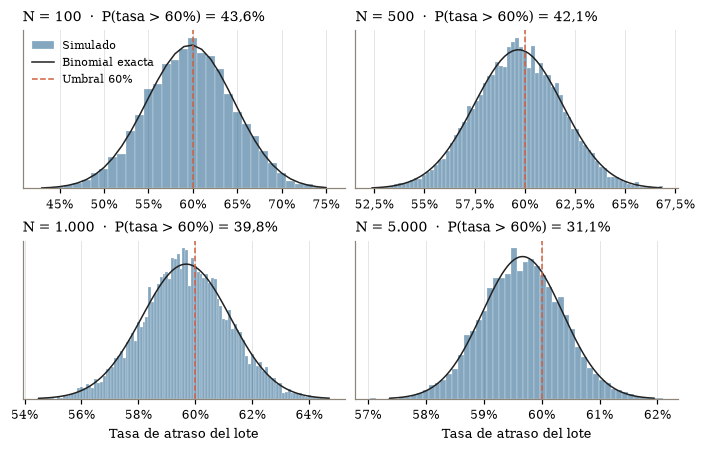

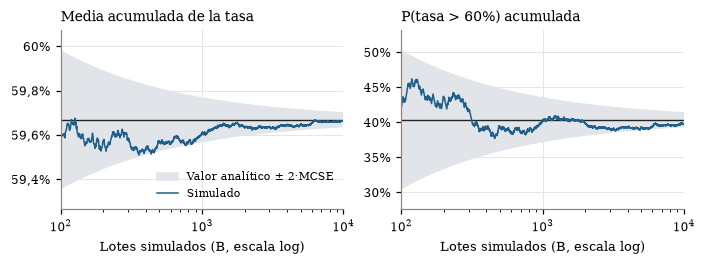

,B_parcial,media,mcse_media,prob_sobre_umbral,mcse_prob,dif_media,dif_prob
10,100,0.59579,0.00167,0.420,0.04936,-0.00090,0.01623
11,500,0.59567,0.00072,0.392,0.02183,-0.00102,-0.01177
12,1000,0.59608,0.00050,0.402,0.01550,-0.00061,-0.00177
13,5000,0.59650,0.00022,0.393,0.00691,-0.00019,-0.01077
14,10000,0.59664,0.00015,0.398,0.00489,-0.00005,-0.00577


In [23]:
def _pct(x, _=None):
    v = x * 100
    return f'{num(v, 0 if abs(v - round(v)) < 1e-9 else 1)}%'


FMT_TASA = FuncFormatter(_pct)

# Figura 1: distribución de la tasa por tamaño de lote, con la binomial exacta
fig, ejes, _ = rejilla(len(TAMANOS), ncols=2, alto=2.0)
for a, N in zip(ejes, TAMANOS):
    tasas = TASAS_MC[N]
    k = np.arange(binom.ppf(0.0005, N, P_S1), binom.ppf(0.9995, N, P_S1) + 1)
    bordes = (np.arange(k.min(), k.max() + 2) - 0.5) / N if N <= 1_000 else 50
    a.hist(tasas, bins=bordes, density=True, color=AZUL, alpha=0.55, edgecolor='white', linewidth=0.3,
           label='Simulado')
    a.plot(k / N, binom.pmf(k, N, P_S1) * N, color='#222222', lw=1, label='Binomial exacta')
    a.axvline(UMBRAL, color=TERRA, ls='--', lw=1, label='Umbral 60%')
    fila = montecarlo_escenarios.set_index('N').loc[N]
    a.set_title(f'N = {num(N)}  ·  P(tasa > 60%) = {num(fila["prob_sobre_umbral"] * 100, 1)}%')
    a.xaxis.set_major_formatter(FMT_TASA)
    a.set_yticks([])
ejes[0].legend(loc='upper left', fontsize=7)
for a in ejes[-2:]:
    a.set_xlabel('Tasa de atraso del lote')
guardar('fig_mc_1_distribucion', fig)

# Figura 2: convergencia de la media y de la probabilidad para N = 1.000
N_FOCO = 1_000
tasas = TASAS_MC[N_FOCO]
b = np.arange(1, len(tasas) + 1)
media_acum = np.cumsum(tasas) / b
prob_acum = np.cumsum(tasas > UMBRAL) / b
fila = montecarlo_escenarios.set_index('N').loc[N_FOCO]
fig, ejes = plt.subplots(1, 2, figsize=(ANCHO, 2.3))
for a, serie, ref, var, titulo in [
        (ejes[0], media_acum, P_S1, P_S1 * (1 - P_S1) / N_FOCO, 'Media acumulada de la tasa'),
        (ejes[1], prob_acum, fila['prob_exacta'], fila['prob_exacta'] * (1 - fila['prob_exacta']),
         'P(tasa > 60%) acumulada')]:
    banda = 2 * np.sqrt(var / b)
    a.fill_between(b, ref - banda, ref + banda, color=GRID, label='Valor analítico ± 2·MCSE')
    a.axhline(ref, color='#222222', lw=0.9)
    a.plot(b, serie, color=AZUL, lw=1, label='Simulado')
    a.set_xscale('log')
    a.set_xlim(100, len(tasas))   # la convergencia se evalúa desde B = 100
    a.set_ylim(ref - 1.3 * banda[99], ref + 1.3 * banda[99])
    a.set_title(titulo)
    a.set_xlabel('Lotes simulados (B, escala log)')
    a.yaxis.set_major_formatter(FMT_TASA)
ejes[0].legend(loc='lower right', fontsize=7)
guardar('fig_mc_2_convergencia', fig)

display(montecarlo_convergencia[montecarlo_convergencia['N'] == N_FOCO][
    ['B_parcial', 'media', 'mcse_media', 'prob_sobre_umbral', 'mcse_prob', 'dif_media', 'dif_prob']].round(5))

#### Interpretación del Monte Carlo principal

**Variabilidad según el tamaño del lote.** Con la proporción de S1 ($p = 59{,}67\%$), la tasa de atraso de un lote varía en torno a ese valor con una desviación que cae como $1/\sqrt{N}$. El rango central del 95 % de los lotes simulados va de 50,0 % a 69,0 % con 100 envíos, se estrecha a [56,6 %; 62,7 %] con 1.000 y a [58,3 %; 61,1 %] con 5.000. En lotes pequeños, por lo tanto, diferencias de varios puntos entre un lote y otro son esperables solo por azar y no indican por sí mismas un cambio en el proceso.

**Riesgo de superar el 60 % (lote de 1.000 envíos).** La probabilidad de que un lote supere el 60 % de atrasos es del 39,8 % (valor exacto binomial: 40,4 %), y el 1 % de los lotes supera el 63,3 %. Como $p$ está apenas 0,33 puntos bajo el umbral (0,2 desviaciones estándar con N = 1.000), superar el 60 % no es un evento excepcional. Esa probabilidad baja lentamente con el tamaño del lote, de 43,6 % (N = 100) a 31,1 % (N = 5.000). Un umbral operativo fijado en 60 % se activaría con frecuencia aunque el proceso no cambie.

**Coherencia y convergencia.** En los cuatro tamaños, la media y la desviación simuladas coinciden con los valores binomiales ($p$ y $\sqrt{p(1-p)/N}$), y las probabilidades quedan a menos de 4 MCSE de las exactas. Con B = 10.000 se cumplen las tolerancias fijadas antes de ejecutar, así que no fue necesario ampliar a 50.000: el MCSE de la media es ≤ 0,0005 y el de la probabilidad ≤ 0,005, aunque este último queda cerca del límite (0,0049 con N = 1.000) porque la probabilidad está cerca de 0,5. En el lote de 1.000, la probabilidad acumulada fluctúa entre 37,7 % y 46,2 % en los primeros 1.000 lotes y entre 38,8 % y 39,9 % desde B = 2.000. Se mantiene casi siempre dentro de la banda de ±2·MCSE; sale brevemente cerca de B ≈ 4.850, lo esperable con una banda de ese ancho. La coincidencia demuestra la coherencia del simulador, no una validación externa del modelo.

**Alcance.** Los cuantiles son un **intervalo de resultados simulados condicionado a $p = 59{,}67\%$**, no un intervalo de confianza de $p$. El modelo supone envíos independientes dentro del lote y una proporción fija igual a la de S1. Si los atrasos se concentran por bodega, ruta o período, la variabilidad real sería mayor. Además, el IC de Wilson de S1 para $p$ ([58,75 %; 60,58 %]) incluye valores sobre el 60 %, con los que el riesgo de superar el umbral sería mayor; esa incertidumbre de $p$ se examina en la sección 4.3.

## 4. Robustez, sensibilidad e insumos para S3

### 4.1 Observaciones influyentes (jackknife)

**Responsable:** Yerko · **Revisor:** José · **Desarrollo completo:** Anexo E

**Método.** Se conserva el análisis completo como referencia. Se aplica *jackknife* a todos los estimandos y coeficientes del inventario que admitan eliminar una fila: error estándar *jackknife* y cambio de cada estimación al retirar cada envío.

- **Medias:** se usa la identidad $\bar x_{(-i)} = (\text{suma} - x_i)/(n-1)$, que evita un cálculo cuadrático.
- **Efectos entre grupos:** se conserva la pertenencia al grupo y se actualizan los tamaños.
- **Pruebas:** se evalúa el cambio del efecto o del estadístico y de la decisión, sin interpretar el *jackknife* del valor *p* como un IC de un parámetro.
- **Casos indefinidos:** se registra la causa.

**Registro:** los diez registros más influyentes por estadístico, con `id_envio`, variable, valor original y cambio absoluto y relativo. Los empates se resuelven por ID y se informa que existen.

**Criterio.** Un valor extremo estadísticamente válido no se elimina por defecto.

**Interpretación** *(pendiente)*.

### 4.2 Sensibilidad a extremos y estructura

**Responsables:** Yerko y Sebastián · **Revisores:** José y Yerko · **Desarrollo completo:** Anexo E

**Escenarios**, evaluados por separado:

1. Datos completos (referencia).
2. Winsorización 1/99 de peso y costo.
3. Exclusión exploratoria de observaciones fuera de 1,5·IQR.
4. Análisis restringido a descuento ≤ 10.

Para cada escenario se registran la regla, los IDs afectados, el n retenido y los cambios en todos los estimandos, los IC, las siete pruebas, las 20 correlaciones y las 15 asociaciones. El CSV no se modifica, y los análisis restringidos no se tratan como estimaciones de la misma población.

**Recálculo por escenario.** Se repiten los IC *bootstrap* y las siete permutaciones en cada escenario válido, con B = 10.000, y se recalcula Holm para la familia completa del escenario. Si un escenario suprime un grupo (por ejemplo, E3 al restringir a descuento ≤ 10), se marca como «no evaluable por diseño», sin fabricar un contraste ni un resultado.

**Diagnósticos.** La comparación de la media con la mediana o la media recortada indica un cambio de estimando, no valida directamente el IC de la media.

**Segmento de descuento > 10.** En S1, los 2.647 envíos con descuento mayor que 10 están atrasados, frente a 3.916 de 8.352 con descuento ≤ 10 ($p = 0{,}468870$). Un *bootstrap* del primer segmento produce solo unos: IC [1, 1] y BCa posiblemente indefinido. No se interpreta como certeza poblacional; se conserva como advertencia el IC de Wilson de S1, [0,998551; 1]. El umbral no se cambia buscando el resultado más favorable.

**Para el cuerpo del informe** *(pendiente)*: qué conclusiones centrales se sostienen o cambian, con la magnitud y la evidencia de influencia, incluida toda discrepancia material que afecte la interpretación, aunque contradiga la conclusión inicial. Todos los cambios se publican en el Anexo E; no se trasladan al cuerpo todos los escenarios.

#### Reglas operativas y alcance de la comparación

Este bloque evalúa las **siete pruebas y los 35 coeficientes**. El análisis de
parámetros y el jackknife de observaciones influyentes corresponden al trabajo
complementario de Yerko; no se consideran terminados por ejecutar este bloque.
No se generan anexos ni se selecciona todavía el contenido del informe.

Los escenarios se construyen siempre desde los datos completos, sin encadenarlos:

- **Completos:** referencia ya ejecutada, con sus tablas y 10.000 réplicas; se
  verifican sus estimaciones y metadatos antes de reutilizarla.
- **Winsorización 1/99:** peso y costo se acotan por sus cuantiles globales, con
  interpolación lineal. Se conservan todos los envíos y la codificación del atraso.
- **Exclusión 1,5 IQR:** se aplica a llamadas, costo, compras previas, descuento y
  peso. Se elimina la unión de filas fuera de los límites de cualquiera de estas
  cinco variables; los límites se calculan una sola vez sobre los datos completos,
  son inclusivos y no se recalculan después de excluir. Esta decisión operativa
  fue confirmada por Sebastián antes de ejecutar y queda registrada para que el
  análisis complementario use exactamente las mismas filas.
- **Descuento ≤10:** se retienen los envíos que cumplen la condición original,
  sin modificar el umbral. Los resultados describen esa subpoblación.

Se registran umbrales, todos los IDs retenidos/excluidos, variables y valores
modificados, tamaños y tasas. La winsorización cambia las variables analizadas;
las exclusiones cambian la población de referencia. Por ello sus diferencias no
son nuevas estimaciones de un parámetro poblacional idéntico.

Se repiten las permutaciones y el bootstrap emparejado con **B=10.000** en cada
escenario alterado. Se conserva la regla de precisión computacional de las pruebas:
si los límites binomiales simultáneos del 99% permiten cambiar una decisión cruda
o Holm, se amplía una sola vez a 50.000 permutaciones; la ambigüedad restante se
informa sin seguir simulando hasta obtener una decisión deseada.

**Familia Holm:** se mantienen los siete contrastes planificados. Cuando uno no
es evaluable (E3 al eliminar el segmento >10), su p queda ausente. Solo dentro del
cálculo del ajuste se usa un relleno conservador de 1 para mantener el tamaño de
la familia; ese relleno no se publica como un resultado ni se interpreta como
«no rechazo». Se informa cuántas pruebas son evaluables en cada escenario.

**Flujos:** las simulaciones nuevas usan el subárbol 1 del flujo
`sensibilidad_escenarios`: `(5, 1, escenario, técnica, prueba)`. El subárbol 0 queda
disponible para parámetros. Cada prueba y técnica tiene un flujo fijo, independiente
del orden de ejecución y de la ausencia de un contraste. La referencia reutilizada
conserva sus flujos originales; las réplicas no son comparaciones pareadas entre
escenarios. No se interpreta la diferencia entre dos IC como un IC de la diferencia.

In [14]:
from IPython.display import display

# Decisión de escenario explícita y anterior al cálculo; límites sobre datos completos.
VARIABLES_IQR_SENS = ['llamadas_atencion', 'costo_producto', 'compras_previas',
                     'descuento_ofrecido', 'peso_gramos']
ORDEN_ESCENARIOS_SENS = ('completos', 'winsor_01_99', 'exclusion_iqr', 'descuento_le10')
B_SENS, LOTE_SENS = 10_000, 32
original_sens = df.copy(deep=True)
ESCENARIOS_SENS, resumen_escenarios_sens, umbrales_sens, registros_sens = construir_escenarios_sensibilidad(
    df, VARIABLES_IQR_SENS)
pd.testing.assert_frame_equal(df, original_sens)
assert tuple(ESCENARIOS_SENS)==ORDEN_ESCENARIOS_SENS
assert set(ESCENARIOS_SENS['descuento_le10']['id_envio'])==set(df.loc[df['descuento_ofrecido'].le(10),'id_envio'])
assert len(ESCENARIOS_SENS['descuento_le10'])==8352
for nombre, muestra in ESCENARIOS_SENS.items():
    assert muestra['id_envio'].is_unique
    assert set(muestra['id_envio']).issubset(set(df['id_envio']))
    np.testing.assert_array_equal(muestra[TARGET], df.loc[muestra.index,TARGET])
    if nombre!='winsor_01_99': pd.testing.assert_frame_equal(muestra, df.loc[muestra.index])

catalogo_sens = inventario[inventario['estimando'].isin(
    ['rho_spearman', 'r_punto_biserial', 'v_cramer'])].sort_values('id').reset_index(drop=True)
assert len(catalogo_sens)==35
# Referencia ya ejecutada: no se vuelve a simular el escenario sin tratamiento.
base_pruebas_sens = pd.read_csv(TABLAS_S2/'permutaciones_todas.csv', float_precision='round_trip')
base_coef_sens = pd.concat([pd.read_csv(TABLAS_S2/f'{nombre}_bootstrap.csv', float_precision='round_trip')
                           for nombre in ['correlaciones','asociaciones']], ignore_index=True)
assert base_pruebas_sens['codigo'].is_unique and set(base_pruebas_sens['codigo'])==set(ORDEN_PRUEBAS)
assert base_coef_sens['id'].is_unique and set(base_coef_sens['id'])==set(catalogo_sens['id'])
assert base_pruebas_sens['B'].ge(B_SENS).all() and base_coef_sens['B'].ge(B_SENS).all()
assert base_pruebas_sens['n'].eq(len(df)).all() and base_coef_sens['n'].eq(len(df)).all()
for codigo in ORDEN_PRUEBAS:
    etiquetas, funcion, meta = preparar_contraste(df, codigo)
    referencia = base_pruebas_sens.set_index('codigo').loc[codigo]
    np.testing.assert_allclose(funcion(etiquetas), referencia['estadistico_observado'], rtol=1e-10, atol=1e-12)
    np.testing.assert_allclose(meta['efecto'], referencia['efecto'], rtol=1e-10, atol=1e-12)
obs_coef_sens = coeficientes_lote(preparar_coeficientes(df,catalogo_sens), np.arange(len(df))[None,:])[0]
np.testing.assert_allclose(obs_coef_sens, base_coef_sens.set_index('id').loc[catalogo_sens['id'],'estimacion'], rtol=1e-10, atol=1e-12)
for archivo in ['permutaciones_metadatos.json','coeficientes_metadatos.json']:
    registro = json.loads((TABLAS_S2/archivo).read_text())
    # S1 registra tanto CRLF original como LF normalizado (mismos datos).
    assert registro['sha256_datos'] in {registro_fuente['file']['sha256'],
        registro_fuente['file']['sha256_lf_normalized']} and registro['semilla']==SEMILLA
resumen_escenarios_sens.to_csv(TABLAS_S2/'sensibilidad_escenarios.csv', index=False)
umbrales_sens.to_csv(TABLAS_S2/'sensibilidad_umbrales.csv', index=False)
registros_sens.to_csv(TABLAS_S2/'sensibilidad_registros.csv', index=False)
display(resumen_escenarios_sens)
display(umbrales_sens)

,escenario,n_original,n_retenido,n_excluido,n_modificado,n_atrasado,tasa_atraso
0,completos,10999,10999,0,0,6563,0.596691
1,winsor_01_99,10999,10999,0,425,6563,0.596691
2,exclusion_iqr,10999,7971,3028,0,3947,0.495170
3,descuento_le10,10999,8352,2647,0,3916,0.468870


,tratamiento,variable,inferior,superior,regla
0,winsor_01_99,peso_gramos,1030.00,5964.02,cuantiles 0.01/0.99; interpolación lineal
1,winsor_01_99,costo_producto,108.00,304.00,cuantiles 0.01/0.99; interpolación lineal
2,exclusion_iqr,llamadas_atencion,0.00,8.00,"fuera de [Q1−1.5 IQR, Q3+1.5 IQR]; unión entre..."
3,exclusion_iqr,costo_producto,46.00,374.00,"fuera de [Q1−1.5 IQR, Q3+1.5 IQR]; unión entre..."
4,exclusion_iqr,compras_previas,1.50,5.50,"fuera de [Q1−1.5 IQR, Q3+1.5 IQR]; unión entre..."
5,exclusion_iqr,descuento_ofrecido,-5.00,19.00,"fuera de [Q1−1.5 IQR, Q3+1.5 IQR]; unión entre..."
6,exclusion_iqr,peso_gramos,-2976.25,9865.75,"fuera de [Q1−1.5 IQR, Q3+1.5 IQR]; unión entre..."
7,descuento_le10,descuento_ofrecido,NaN,10.00,retener descuento <=10


In [15]:
inicio_sens = time.perf_counter()
base_pruebas_sens = base_pruebas_sens.copy()
base_pruebas_sens['escenario'] = 'completos'
base_pruebas_sens['estado'], base_pruebas_sens['motivo'] = 'evaluable', ''
base_pruebas_sens['rechaza_p_perm'] = base_pruebas_sens['p_perm'].le(0.05)
base_pruebas_sens['rechaza_p_perm_holm'] = base_pruebas_sens['p_perm_holm'].le(0.05)
base_pruebas_sens['familia_holm'] = base_pruebas_sens['n_pruebas_evaluables'] = 7
base_pruebas_sens['origen'] = 'referencia reutilizada: permutaciones_todas.csv'
base_coef_sens = base_coef_sens.copy()
base_coef_sens['escenario'] = 'completos'
base_coef_sens['origen'] = 'referencia reutilizada: tablas bootstrap de coeficientes'
pruebas_por_escenario_sens = [base_pruebas_sens]
coef_por_escenario_sens = [base_coef_sens]
REPLICAS_SENS, precision_sens = {}, {}
for numero, nombre in enumerate(ORDEN_ESCENARIOS_SENS[1:], 1):
    muestra = ESCENARIOS_SENS[nombre]
    pruebas, replicas, historial = evaluar_pruebas_sensibilidad(muestra, numero, B=B_SENS)
    pruebas['escenario'], pruebas['origen'] = nombre, 'permutación recalculada'
    pruebas_por_escenario_sens.append(pruebas)
    precision_sens[nombre] = historial
    for codigo, valores in replicas.items(): REPLICAS_SENS[f'{nombre}__{codigo}'] = valores
    ss = semilla_sensibilidad(numero, 1)
    coef, replicas_coef = bootstrap_coeficientes(muestra, catalogo_sens, np.random.default_rng(ss), B=B_SENS, lote=LOTE_SENS)
    coef['escenario'], coef['origen'] = nombre, 'bootstrap emparejado recalculado'
    coef['spawn_key'] = '.'.join(map(str,ss.spawn_key))
    coef_por_escenario_sens.append(coef)
    REPLICAS_SENS[f'{nombre}__coeficientes'] = replicas_coef
    print(f"Escenario {nombre}: {len(muestra):,} envíos, {pruebas['estado'].eq('evaluable').sum()} pruebas evaluables y {len(coef)} coeficientes.")

sensibilidad_pruebas = pd.concat(pruebas_por_escenario_sens, ignore_index=True)
sensibilidad_coeficientes = pd.concat(coef_por_escenario_sens, ignore_index=True)
refp = base_pruebas_sens.set_index('codigo')
refc = base_coef_sens.set_index('id')
for columna in ['p_s1','p_s1_holm','estadistico_s1','fuente_s1','ids_inventario','advertencia']:
    sensibilidad_pruebas[columna] = sensibilidad_pruebas['codigo'].map(refp[columna])
for columna in ['efecto', 'estadistico_observado', 'p_perm', 'p_perm_holm']:
    referencia = sensibilidad_pruebas['codigo'].map(refp[columna])
    sensibilidad_pruebas[columna+'_base'] = referencia
    sensibilidad_pruebas['delta_'+columna] = sensibilidad_pruebas[columna]-referencia
sensibilidad_pruebas['delta_efecto_relativo'] = sensibilidad_pruebas['delta_efecto']/sensibilidad_pruebas['efecto_base'].abs().replace(0,np.nan)
for sufijo in ['p_perm','p_perm_holm']:
    base_decision = sensibilidad_pruebas['codigo'].map(refp['rechaza_'+sufijo])
    actual = sensibilidad_pruebas['rechaza_'+sufijo].astype('boolean')
    sensibilidad_pruebas['cambia_decision_'+sufijo] = actual.ne(base_decision)
# U cambia con los tamaños de grupo: comparar el efecto biserial, no solo el U bruto.
for columna in ['estimacion','ic_inf','ic_sup','ancho_ic','sesgo','ee']:
    referencia = sensibilidad_coeficientes['id'].map(refc[columna])
    sensibilidad_coeficientes[columna+'_base'] = referencia
    sensibilidad_coeficientes['delta_'+columna] = sensibilidad_coeficientes[columna]-referencia
sensibilidad_coeficientes['delta_relativo'] = sensibilidad_coeficientes['delta_estimacion']/sensibilidad_coeficientes['estimacion_base'].abs().replace(0,np.nan)
es_cor = sensibilidad_coeficientes['estimando'].ne('v_cramer')
finito = sensibilidad_coeficientes[['estimacion','ic_inf','ic_sup']].notna().all(axis=1)
sensibilidad_coeficientes['cambia_signo'] = pd.array([
    bool(np.sign(r.estimacion)!=np.sign(r.estimacion_base)) if cor and valido else pd.NA
    for cor,valido,r in zip(es_cor,finito,sensibilidad_coeficientes.itertuples())],dtype='boolean')
sensibilidad_coeficientes['cambia_inclusion_cero'] = pd.array([
    bool((r.ic_inf<=0<=r.ic_sup)!=(r.ic_inf_base<=0<=r.ic_sup_base)) if cor and valido else pd.NA
    for cor,valido,r in zip(es_cor,finito,sensibilidad_coeficientes.itertuples())],dtype='boolean')
sensibilidad_coeficientes['sensibilidad'] = 'comparación descriptiva entre escenarios; ver deltas y diagnóstico'
for tabla in [sensibilidad_pruebas,sensibilidad_coeficientes]:
    tabla['semilla'] = SEMILLA
    tabla['flujo'] = np.where(tabla['escenario'].eq('completos'), 'referencia original', 'sensibilidad_escenarios')
    tabla['poblacion'] = tabla['escenario'].map({
        'completos':'muestra original', 'winsor_01_99':'mismos envíos; peso/costo transformados',
        'exclusion_iqr':'subpoblación sin extremos según regla global', 'descuento_le10':'subpoblación descuento <=10'})
assert len(sensibilidad_pruebas)==28 and len(sensibilidad_coeficientes)==140
assert not sensibilidad_pruebas.duplicated(['escenario','codigo']).any()
assert not sensibilidad_coeficientes.duplicated(['escenario','id']).any()
assert sensibilidad_pruebas.loc[sensibilidad_pruebas['estado'].eq('evaluable'),'B'].ge(B_SENS).all()
assert sensibilidad_coeficientes['B'].ge(B_SENS).all()
for nombre,tabla in [('pruebas',sensibilidad_pruebas),('coeficientes',sensibilidad_coeficientes)]:
    tabla.to_csv(TABLAS_S2/f'sensibilidad_{nombre}.csv', index=False)
np.savez_compressed(TABLAS_S2/'sensibilidad_replicas.npz', **REPLICAS_SENS)
import platform, scipy, statsmodels
mapa_sens = {nombre:dict(permutaciones={codigo:list(semilla_sensibilidad(i,0,j).spawn_key)
    for j,codigo in enumerate(ORDEN_PRUEBAS)}, coeficientes=list(semilla_sensibilidad(i,1).spawn_key))
    for i,nombre in enumerate(ORDEN_ESCENARIOS_SENS) if i>0}
metadatos_sens = dict(semilla=SEMILLA, flujo='sensibilidad_escenarios', subarbol=1,
    mapa_flujos=mapa_sens, orden_escenarios=list(ORDEN_ESCENARIOS_SENS),
    variables_iqr=VARIABLES_IQR_SENS, regla_iqr='unión; umbrales globales; sin iterar; límites inclusivos',
    interpolacion_cuantiles='linear', B=B_SENS, lote=LOTE_SENS, precision_permutacion=precision_sens,
    orden_coeficientes=catalogo_sens['id'].tolist(), familia_holm=7,
    no_evaluables='p ausente; relleno 1 solo interno para ajuste conservador de la familia planificada',
    sha256_datos=HUELLA_DATOS, commit_s1=COMMIT_S1,
    sha256_lock=hashlib.sha256((RAIZ.parent/'uv.lock').read_bytes()).hexdigest(),
    versiones=dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,
                   scipy=scipy.__version__,statsmodels=statsmodels.__version__),
    segundos=time.perf_counter()-inicio_sens)
(TABLAS_S2/'sensibilidad_metadatos.json').write_text(json.dumps(metadatos_sens,ensure_ascii=False,indent=2),encoding='utf-8')
pd.testing.assert_frame_equal(df, original_sens)
assert hashlib.sha256(DATOS.read_bytes()).hexdigest()==HUELLA_DATOS
print('Comparación completa: 28 filas de pruebas y 140 coeficientes; excepciones conservadas explícitamente.')
display(sensibilidad_pruebas[['escenario','codigo','n','efecto','delta_efecto','p_perm','p_perm_holm','cambia_decision_p_perm_holm','estado']])

Escenario winsor_01_99: 10,999 envíos, 7 pruebas evaluables y 35 coeficientes.


Escenario exclusion_iqr: 7,971 envíos, 7 pruebas evaluables y 35 coeficientes.


Escenario descuento_le10: 8,352 envíos, 6 pruebas evaluables y 35 coeficientes.


Comparación completa: 28 filas de pruebas y 140 coeficientes; excepciones conservadas explícitamente.


,escenario,codigo,n,efecto,delta_efecto,p_perm,p_perm_holm,cambia_decision_p_perm_holm,estado
0,completos,T01,10999,0.008221,0.000000,0.691131,0.691131,False,evaluable
1,completos,T02,10999,-896.028291,0.000000,0.000100,0.000700,False,evaluable
2,completos,T03,10999,13.117733,0.000000,0.000100,0.000700,False,evaluable
3,completos,E1,10999,-0.313010,0.000000,0.000100,0.000700,False,evaluable
4,completos,E2,10999,0.058107,0.000000,0.000800,0.001600,False,evaluable
5,completos,E3,10999,0.531130,0.000000,0.000100,0.000700,False,evaluable
6,completos,E4,10999,-7.209450,0.000000,0.000100,0.000700,False,evaluable
7,winsor_01_99,T01,10999,0.008221,0.000000,0.681632,0.681632,False,evaluable
8,winsor_01_99,T02,10999,-897.369198,-1.340906,0.000100,0.000700,False,evaluable
9,winsor_01_99,T03,10999,13.117733,0.000000,0.000100,0.000700,False,evaluable


#### Comparación gráfica

Se muestran todos los IC y efectos por escenario. Las comparaciones de U se
interpretan a través del efecto biserial, pues el estadístico bruto depende de los
tamaños de grupo. En V de Cramér se comparan magnitud, ancho y sesgo; un IC positivo
no prueba dependencia. Los p de Holm y sus cambios se distinguen de la magnitud
práctica de los efectos.

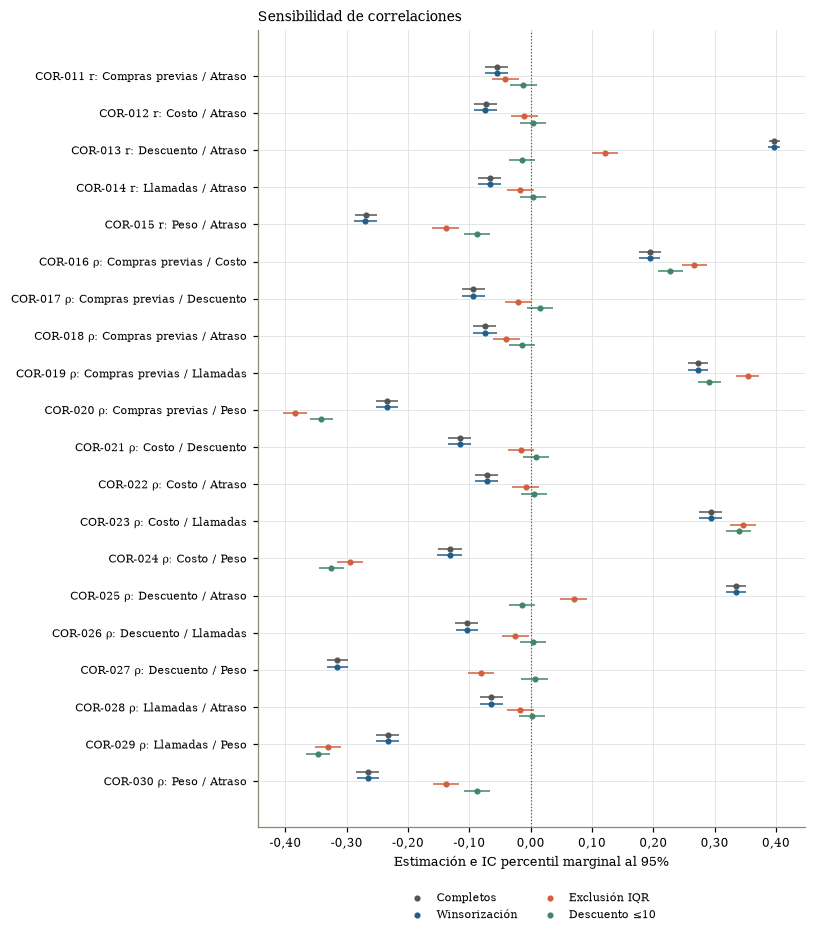

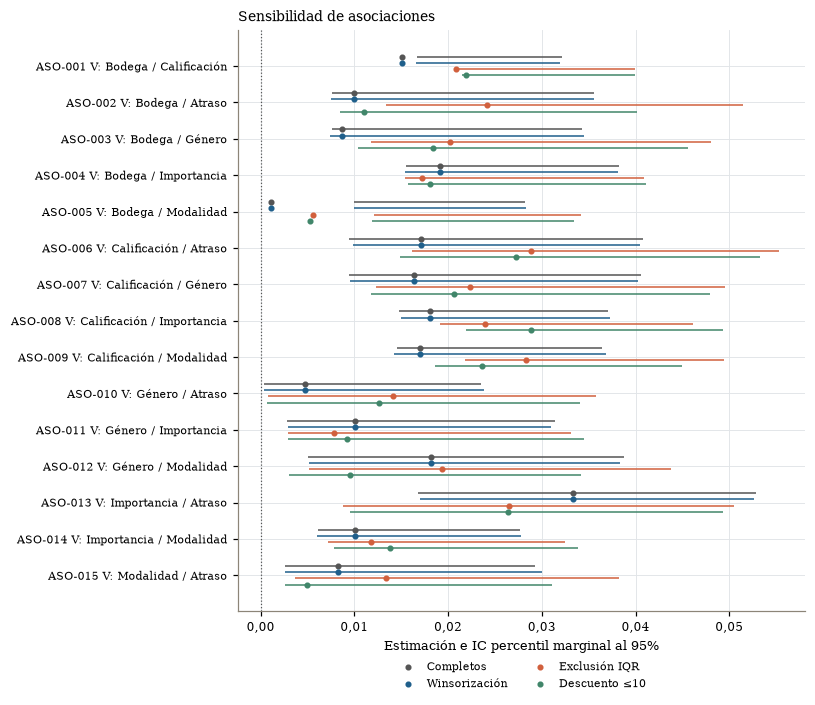

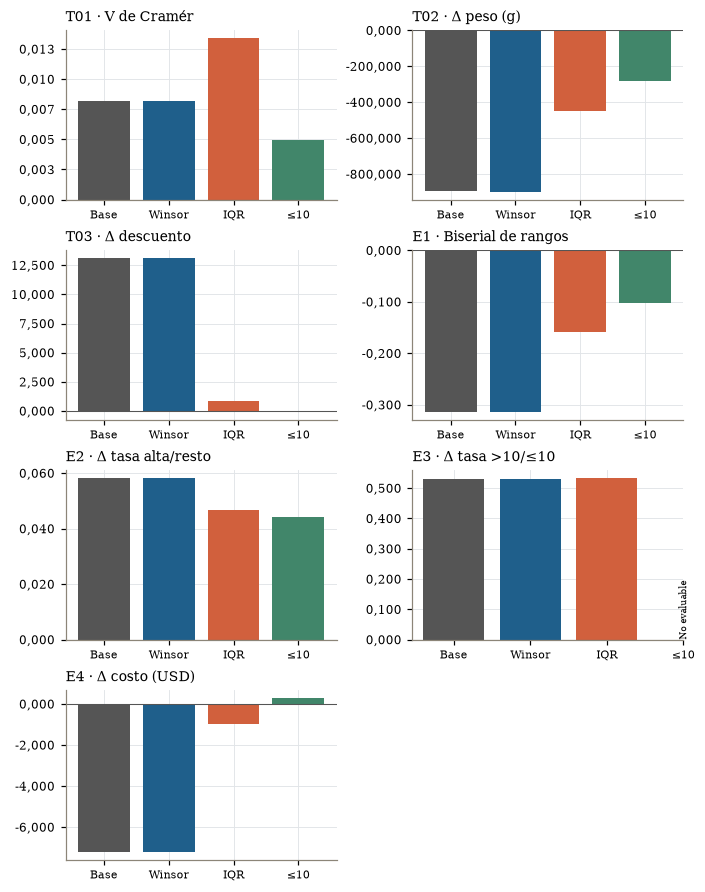

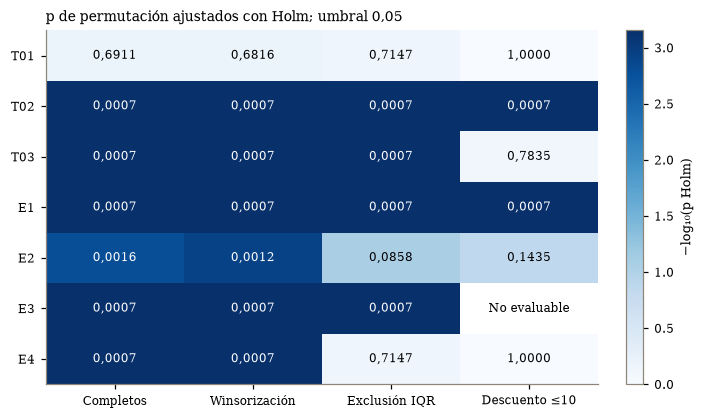

In [16]:
COLORES_SENS = {'completos': GRIS, 'winsor_01_99': AZUL, 'exclusion_iqr': TERRA, 'descuento_le10':'#41866a'}
ETIQ_SENS = {'completos':'Completos', 'winsor_01_99':'Winsorización', 'exclusion_iqr':'Exclusión IQR', 'descuento_le10':'Descuento ≤10'}
for familia, es_v in [('correlaciones',False),('asociaciones',True)]:
    sub = sensibilidad_coeficientes[sensibilidad_coeficientes['estimando'].eq('v_cramer')==es_v]
    ids = sorted(sub['id'].unique())
    fig, ax = plt.subplots(figsize=(ANCHO+1, max(5,len(ids)*0.42)))
    for j,nombre in enumerate(ORDEN_ESCENARIOS_SENS):
        t = sub[sub['escenario'].eq(nombre)].set_index('id').loc[ids]
        posiciones = np.arange(len(ids))+(j-1.5)*0.17
        ax.hlines(posiciones,t['ic_inf'],t['ic_sup'],color=COLORES_SENS[nombre],linewidth=1)
        ax.scatter(t['estimacion'],posiciones,s=9,color=COLORES_SENS[nombre],label=ETIQ_SENS[nombre],zorder=3)
    base = sub[sub['escenario'].eq('completos')].set_index('id').loc[ids]
    etiquetas = []
    for id,r in base.iterrows():
        a,b=r['variable'].split('|')
        metodo = 'V' if es_v else ('ρ' if r['estimando']=='rho_spearman' else 'r')
        etiquetas.append(f"{id} {metodo}: {ETIQ_CORTA.get(a,'Atraso')} / {ETIQ_CORTA.get(b,'Atraso')}")
    ax.set_yticks(range(len(ids)),etiquetas,fontsize=7)
    ax.invert_yaxis()
    ax.axvline(0,color=GRIS,linestyle=':',linewidth=0.8)
    ax.set_xlabel('Estimación e IC percentil marginal al 95%')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x,_:num(x,2)))
    ax.set_title(f'Sensibilidad de {familia}')
    ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.07),ncols=2,fontsize=7)
    guardar(f'fig_sens_{familia}_intervalos',fig)
    plt.close(fig)

fig,ejes,sobrantes = rejilla(7,ncols=2,alto=2.0)
for ax,codigo in zip(ejes,ORDEN_PRUEBAS):
    t = sensibilidad_pruebas[sensibilidad_pruebas['codigo'].eq(codigo)].set_index('escenario').loc[list(ORDEN_ESCENARIOS_SENS)]
    ax.bar(range(4),t['efecto'],color=[COLORES_SENS[x] for x in ORDEN_ESCENARIOS_SENS])
    ax.axhline(0,color=GRIS,linewidth=0.7)
    ax.set_xticks(range(4),['Base','Winsor','IQR','≤10'],fontsize=7)
    ax.set_title(codigo+' · '+{'T01':'V de Cramér','T02':'Δ peso (g)','T03':'Δ descuento',
        'E1':'Biserial de rangos','E2':'Δ tasa alta/resto','E3':'Δ tasa >10/≤10','E4':'Δ costo (USD)'}[codigo])
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x,_:num(x,3)))
    for j,(_,r) in enumerate(t.iterrows()):
        if r['estado']!='evaluable': ax.text(j,0,'No evaluable',rotation=90,fontsize=6,va='bottom',ha='center')
for ax in sobrantes: ax.set_visible(False)
guardar('fig_sens_efectos_pruebas',fig)
plt.close(fig)

matriz_p = sensibilidad_pruebas.pivot(index='codigo',columns='escenario',values='p_perm_holm').reindex(index=ORDEN_PRUEBAS,columns=ORDEN_ESCENARIOS_SENS)
fig,ax = plt.subplots(figsize=(ANCHO,3.7))
im = ax.imshow(-np.log10(matriz_p.to_numpy()),aspect='auto',cmap='Blues',vmin=0)
ax.set_xticks(range(4),[ETIQ_SENS[x] for x in ORDEN_ESCENARIOS_SENS],fontsize=8)
ax.set_yticks(range(7),ORDEN_PRUEBAS)
for i in range(7):
    for j in range(4):
        v=matriz_p.iloc[i,j]
        ax.text(j,i,'No evaluable' if pd.isna(v) else num(v,4),ha='center',va='center',fontsize=8,
                color='white' if pd.notna(v) and -np.log10(v)>2 else 'black')
ax.set_title('p de permutación ajustados con Holm; umbral 0,05')
ax.grid(False)
fig.colorbar(im,ax=ax,label='−log₁₀(p Holm)')
guardar('fig_sens_holm_escenarios',fig)
plt.close(fig)

#### Interpretación de la sensibilidad

**Cobertura.** Se comparan 28 filas de pruebas y 140 coeficientes: cuatro escenarios
por siete contrastes y 35 coeficientes. Los tres escenarios alterados usan 10.000
permutaciones por prueba evaluable y 10.000 remuestras emparejadas por coeficiente.
No fue necesario ampliar las permutaciones según el criterio de precisión
Monte Carlo. No hubo réplicas bootstrap indefinidas. La referencia completa
reutiliza las simulaciones previamente verificadas, no constituye una ejecución
independiente adicional.

| Escenario | Envíos retenidos | Excluidos | Modificados | Tasa observada de atraso |
|---|---:|---:|---:|---:|
| Completos | 10.999 | 0 | 0 | 59,67% |
| Winsorización | 10.999 | 0 | 425 | 59,67% |
| Exclusión IQR | 7.971 | 3.028 | 0 | 49,52% |
| Descuento ≤10 | 8.352 | 2.647 | 0 | 46,89% |

**Winsorización: estabilidad frente a esta transformación.** Las siete decisiones
crudas y ajustadas se conservan, al igual que el signo de las 20 correlaciones.
El mayor cambio absoluto entre los 35 coeficientes es 0,000744. La diferencia
media de peso pasa de −896,03 a −897,37 g y la de costo de −7,21 a −7,19 USD.
Los efectos de las pruebas que no usan peso o costo y las asociaciones categóricas
no cambian; las pequeñas diferencias de p e IC en esos resultados provienen del
remuestreo con flujos independientes, no de un efecto de la winsorización.
Esta estabilidad se refiere al tratamiento 1/99 especificado, no a todos los
posibles tratamientos de extremos.

**Exclusión IQR: sensibilidad a la composición.** Las exclusiones se originan en
compras previas >5,5 y descuento >19: 819 envíos solo por compras, 2.025 solo por
descuento y 184 por ambas variables. Peso, costo y llamadas no generan exclusiones
con sus límites globales. No se trata de eliminar errores acreditados: son valores
observados válidos considerados extremos por una regla exploratoria.

La diferencia de peso sigue siendo negativa, pero baja en magnitud a −449,62 g.
Descuento sigue rechazando igualdad de medias, aunque su diferencia se reduce de
13,12 a 0,86 unidades. E2 (importancia alta/resto) tiene p crudo=0,0286 y
p Holm=0,0858: conserva el rechazo crudo y pierde el ajustado. E4 (costo) pasa a
p Holm=0,7147, con diferencia de −0,99 USD. Por tanto, la conclusión ajustada
sobre importancia y la diferencia de costo son sensibles a esta restricción.
Seis correlaciones pasan a incluir cero; no hay inversiones de signo puntual.

**Restricción a descuento ≤10: cambios sustantivos.** E3 es no evaluable, pues
no existe el grupo >10; su p y su decisión permanecen ausentes. Para los contrastes
evaluables se conserva la familia planificada de siete mediante el ajuste
conservador descrito arriba. Frente al análisis completo cambian las decisiones
Holm de T03, E2 y E4:

| Contraste | Efecto en descuento ≤10 | p de permutación | p Holm | Lectura |
|---|---:|---:|---:|---|
| T02: peso | −283,75 g | 0,000100 | 0,000700 | Conserva rechazo, con menor magnitud |
| T03: descuento | −0,0825 unidades | 0,1959 | 0,7835 | No rechaza igualdad de medias |
| E2: importancia alta/resto | 0,0443 de diferencia de tasas | 0,0287 | 0,1435 | Rechazo crudo, no ajustado |
| E4: costo | 0,29 USD | 0,7851 | 1,0000 | No rechaza igualdad de medias |

E1 conserva evidencia de diferencias de rangos, con efecto biserial que pasa de
−0,3130 a −0,1015. T01 no rechaza independencia en ninguno de los escenarios,
pero eso no demuestra equivalencia entre modalidades. Los valores p=0,000100
están redondeados: cuando no hay excedencias, el valor exacto reportado es
1/10.001, no cero ni una cuantificación precisa de una cola extremadamente pequeña.

**Correlaciones: signo preciso en la muestra completa no implica estabilidad
entre poblaciones.** En descuento ≤10, 12 de las 20 correlaciones incluyen cero
y diez cambian de signo puntual. Las diez inversiones tienen IC que incluyen cero:
no son evidencia de una asociación opuesta bien determinada.

| Relación | Muestra completa | Exclusión IQR | Descuento ≤10 e IC 95% |
|---|---:|---:|---:|
| Descuento–atraso, punto-biserial | 0,3971 | 0,1209 | −0,0143 [−0,0356; 0,0070] |
| Peso–atraso, punto-biserial | −0,2688 | −0,1388 | −0,0881 [−0,1092; −0,0670] |
| Descuento–peso, Spearman | −0,3157 | −0,0811 | 0,0065 [−0,0150; 0,0287] |

La relación peso–atraso conserva dirección y exclusión de cero, pero su magnitud
es sensible a la composición. Las asociaciones de descuento con atraso y peso
se debilitan sustancialmente al retirar el segmento alto. Esto es compatible con
que el patrón global esté concentrado en ese segmento, sin probar causalidad ni
que el patrón sea un error. Las correlaciones de costo, llamadas y compras previas
con atraso también requieren cautela por su pequeña magnitud y pérdida de precisión
del signo en las restricciones.

**V de Cramér.** Las 15 asociaciones conservan magnitudes pequeñas: el máximo es
0,0333 en la referencia y winsorización, 0,0288 con exclusión IQR y 0,0289 con
descuento ≤10. Sus tablas conservan sesgo, error estándar, IC y cambios de amplitud.
No se aplica un criterio de cambio de signo a V, ni se interpreta un IC percentil
positivo como prueba de dependencia. Los cambios relativos pueden resultar grandes
cuando la referencia está cerca de cero; se prioriza el cambio absoluto junto con
la incertidumbre y la magnitud original.

**Síntesis para la siguiente fase.** Las decisiones y coeficientes resisten la
winsorización evaluada. La dirección negativa del peso se conserva también bajo
las restricciones, pero su tamaño no es transportable sin cautela. Las conclusiones
sobre descuento, importancia y costo son sensibles a qué envíos se incluyen.
Conviene conservar el análisis completo y comparar explícitamente los segmentos
de descuento antes de construir modelos, documentando cualquier exclusión. La
regla IQR no justifica eliminar automáticamente los 3.028 registros en la siguiente
fase. Los resultados restringidos corresponden a otras subpoblaciones, y los
umbrales de tratamiento se mantuvieron fijos al remuestrear: los IC no incorporan
incertidumbre por elegir o estimar una regla de tratamiento diferente.

Los IC siguen siendo marginales, no simultáneos; no se crean nuevas pruebas sobre
los 35 coeficientes ni se interpreta una diferencia entre IC como un IC del cambio.
Esta comparación no demuestra independencia, representatividad o causalidad.
El jackknife y los parámetros del trabajo complementario de Yerko siguen pendientes
para la síntesis global de robustez. La revisión cruzada y la integración del reporte
validado corresponden a etapas posteriores; aquí se conserva la evidencia completa
sin generar LaTeX ni anexos.


### 4.3 Sensibilidad de Monte Carlo

**Responsable:** José · **Revisor:** Sebastián · **Desarrollo completo:** Anexo D

**Sensibilidad a $p$.** Se varía $p$ en los extremos y el centro del IC de Wilson de S1, con $N = 1.000$ y $B \ge 10.000$ por escenario. Se miden los cambios en la media, el percentil 99 y $P(\text{tasa} > 0{,}60)$, y se presentan en un gráfico de sensibilidad. Esta actividad evidencia el indicador ID2.3.

**Otras entradas.** Para cada entrada adicional con IC en S1, se varían el centro y los extremos y se registra el efecto sobre su salida pertinente; si no hay IC en S1, se usan escenarios empíricos identificados como extensión. No se agregan parámetros ajustados fuera de S1.

**Contraste de estructura.** Se simula una composición fija de los dos segmentos de descuento, a partir de sus tamaños y tasas en S1:

- $N_{alto} = \text{redondeo}(N \cdot 2.647/10.999)$
- $K_{alto} \sim \text{Binomial}(N_{alto}, 1)$
- $K_{bajo} \sim \text{Binomial}(N - N_{alto},\ 3.916/8.352)$

Su dispersión se contrasta con la del modelo global. Se explicita que $p_{alto} = 1$ es una frontera muestral y una limitación.

**Interpretación** *(pendiente)*.

### 4.4 Reporte de resultados validados

**Responsable:** José · **Revisor:** Yerko · **Desarrollo completo:** Anexo F

**Archivos:** `outputs/resultados_validados.csv` (entrada a S3) y su síntesis legible, `docs/resultados_validados.md`.

**Campos por resultado:** ID, fuente y valor en S1, método en S2, n/B, estimación, IC o *p* en S2, diagnóstico de sensibilidad, estado, limitación, recomendación para S3, evidencia, responsable, revisor, commit y semilla.

**Estados permitidos:** *pendiente*, *respaldado bajo supuestos*, *sensible*, *no concluyente* y *no evaluable con justificación*. Se asignan solo después de ejecutar y revisar.

**Cobertura.** Se comprueba una cobertura del 100 % del inventario: cada resultado tiene una validación o una excepción metodológica explícita. El Anexo F contiene la matriz completa; el cuerpo del informe incluye únicamente los resultados y recomendaciones para S3 que derivan de la discusión central, con evidencia e incertidumbre.

**Orientación para S3:** variables a conservar, registros a inspeccionar, tratamientos a comparar y validación externa necesaria. No se declara causalidad, independencia ni transportabilidad a partir de la concordancia entre métodos.

## 5. Comprobaciones de aceptación

Antes del congelamiento final se verifica:

- [ ] Huellas y referencias de S1; los valores de referencia se reproducen con una tolerancia explícita de punto flotante.
- [ ] B ≥ 10.000 en cada técnica; dominios e IC válidos (coeficientes en [−1, 1] y V de Cramér en [0, 1]).
- [ ] Colas de *t*, *z*, *U* y $\chi^2$; Holm; emparejamiento del *bootstrap* y advertencias de BCa.
- [ ] Monte Carlo: MCSE, convergencia y controles binomiales.
- [ ] Revisión final del cuaderno completo por todo el equipo.
- [ ] Kernel reiniciado y todas las celdas ejecutadas en orden, repetido en un segundo equipo; cifras cotejadas con las tablas exportadas.
- [ ] Cobertura completa en los anexos y, en el cuerpo del informe, al menos tres parámetros, una prueba y entre tres y cinco correlaciones con evidencia y discusión, dentro de siete páginas.